<a href="https://colab.research.google.com/github/Mohamed-01-git/ADABOOST/blob/main/WRF_GEN_evaluation_colab_optimized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WRF-GEN ensemble evaluation

**Setup:** `ens0` = WRF driven by ERA5 (control), `ens1..ens10` = WRF driven by EraGAN members.
Evaluated per simulation day (`sim_YYYY_MM_DD_surface`) against ERA5 (`datain_YYYY_MM_DD/single_*.grib`) interpolated to the WRF grid.

**Metrics**
1. Deterministic: bias, RMSE, MAE of the control (`ens0`) and of the ensemble mean
2. Probabilistic: fair CRPS, CRPSS vs the control (MAE), spread-skill ratio, rank histograms, Brier skill score and reliability diagrams (season-specific tail event: > p90, or < p10 for winter T2)
3. Categorical (season-specific tail event): POD, FAR, CSI (and frequency bias) for the control, the ensemble mean and the majority vote of the members, plus the **full contingency scores** (accuracy, POFD, ETS, Hanssen-Kuipers, Heidke, odds-ratio skill score)
4. Lead-time curves, spatial maps, per-day scores, bootstrap confidence intervals over days
5. **Initial-conditions assessment** (lead 0 h, before the forecast is judged)
6. **Station verification** (section 7): the same scores against your own observations (`t2m_o`, `ws_o`, `tp_o`), with ERA5 at the stations as a reference

**Domain and seasons:** all scores are computed over **Morocco land points only** (mask from the shapefile) and are reported for *all days*, then split into *winter* and *summer* (`SEASONS` in the config cell).

**Precipitation** has two variables. `PRECIP_ACC` (main metric) is the total over non-overlapping `ACC_H`-hour windows (WRF `RAINNC+RAINC` vs ERA5 `tp`), scored at lead = `ACC_H`, 2·`ACC_H`, ...; totals below `ACC_MIN` mm are set to 0 and the event threshold is `max(p90, 1 mm)`. `PRECIP` (secondary: intensity and timing) is verified as the mean rate (mm/h) over each WRF output interval: WRF `RAINNC + RAINC` (de-accumulated) vs ERA5 `tp` summed over the same interval. Rates below `PRECIP_MIN` are set to 0 in both (removes ERA5 drizzle), the event threshold is `max(p90, 0.1 mm/h)`, tied (dry) ranks are randomised in the rank histogram, and the first output step is skipped (no interval yet).

**Caveat:** `ens0` is driven by ERA5, so verifying against ERA5 is *not independent* and favours the control. Treat this as a consistency check, and confirm with station observations when you can (see the last cell).

## Running on Google Colab (optimized loader)

1. **Runtime:** a standard CPU runtime is enough; use *High-RAM* if it runs out of memory, or evaluate fewer days at a time (`MAX_DAYS` in the config cell).
2. **Run the install cell below once per session**, then continue from the config cell.
3. **Data in two folders:** the notebook looks for `sim_YYYY_MM_DD_surface/` and `datain_YYYY_MM_DD/` in every folder listed in `ROOTS` (`WRF-GEN` and `WRF-GEN2`) and merges them, so **nothing has to be copied or moved into one place**. A folder that was *shared with you* (or lives in another Google account) is not under `MyDrive` until you add a shortcut to it (Drive > Shared with me > right-click the folder > Organize > Add shortcut).
4. **What is faster than before**
   * WRF files are read with `netCDF4` (only the variables needed) instead of xarray, **in parallel, one process per ensemble member**, with a progress bar.
   * Each finished member is saved as a small *part* file, so if the session is interrupted the next run **resumes** instead of starting the day again. The day cache is written uncompressed (compression was a major stall).
   * A missing, truncated or unreadable `wrfout` file is skipped and reported; it no longer stops the run. A member that hangs on Drive is abandoned after `MEMBER_TIMEOUT` seconds.
   * ERA5 GRIB files are decoded in parallel and the result is cached, so later runs skip this step.
5. **Output:** results, figures and the per-day cache go to `OUT_ROOT/GLOBAL_WRFGEN_EVALUATION/notebook_eval` in your Drive, so the cache survives the end of the session. The first run is still the slow one; later runs reuse the cache.
6. The outputs of the original notebook were cleared; run all cells to regenerate them.

In [1]:
# Run once per Colab session (restart the runtime if pip asks you to)
!apt-get -qq install -y libeccodes-dev > /dev/null
!pip -q install cfgrib eccodes cartopy netCDF4 xarray pyshp shapely

In [5]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

# Mount Google Drive (no-op when the notebook is run outside Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("not running in Colab: skipping drive.mount")
import os, shutil, time
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

# ------------------------- CONFIG -------------------------
DRIVE = Path("/content/drive/MyDrive")
# DRIVE = Path("/home/muhammed/GoogleDrive")
# Folders that contain sim_YYYY_MM_DD_surface/ and datain_YYYY_MM_DD/ (a day may live in either folder).
# A folder shared with you only shows up under MyDrive after: Drive > Shared with me > right-click > Organize > Add shortcut.
ROOTS = [DRIVE / "WRF-GEN", DRIVE / "WRF-GEN2"]
OUT_ROOT = ROOTS[0]                    # results + cache are written here: must be a folder you can write to

OUT   = OUT_ROOT / "GLOBAL_WRFGEN_EVALUATION" / "notebook_eval"
CACHE = OUT / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

# use <folder>/datasets if the data sit one level down; drop folders that are not found
# ROOTS = [r / "datasets" if (r / "datasets").is_dir() else r for r in ROOTS]
ROOTS = [r if r.is_dir() else r for r in ROOTS]
for r in ROOTS:
    print(f"{r}: {'found' if r.is_dir() else 'NOT FOUND (shared folder? add a shortcut to My Drive)'}")
ROOTS = [r for r in ROOTS if r.is_dir()]
assert ROOTS, "no data folder found: check ROOTS and that Drive is mounted"


CTRL    = "ens0"
MEMBERS = [f"ens{i}" for i in range(1, 11)]
ALL     = [CTRL] + MEMBERS
N       = len(MEMBERS)

# ---- loading / performance settings ----
NWORK          = 10                       # parallel worker processes (I/O bound; lower to 3-4 if Colab runs out of RAM)
MAX_DAYS       = None                    # e.g. 2 to test the pipeline on the first 2 days only; None = all days
STAGE_LOCAL    = False                   # True: copy each wrfout to local disk before reading (try it if direct Drive reads are slow); the copy is deleted right after, so no extra storage is kept
MEMBER_TIMEOUT = 1800                    # seconds to wait for one ensemble member before giving up on it (Drive hang protection)
PARTS          = Path("/content/_parts")  # per-member scratch files (local disk, deleted once a day is cached)

SPINUP_H = 3      # drop lead times shorter than this (hours since first wrfout)
STRIDE   = 3      # spatial subsampling for rank histogram / reliability (speed)
PCTL     = 90     # percentile of ERA5 used as the event threshold for Brier/reliability (upper tail)
COLD_T2_WINTER = True   # True: in winter the 2 m temperature event is the COLD tail (T2 < p(100-PCTL), e.g. p10); thresholds are computed per season
N_BOOT   = 2000
_shp = [r / "shapefile" / "maroc-world.shp" for r in ROOTS] + [r.parent / "shapefile" / "maroc-world.shp" for r in ROOTS]
SHP      = next((p for p in _shp if p.exists()), _shp[0])   # shapefile: searched in each data folder (set it by hand if elsewhere)

ACC_H   = 6      # precipitation accumulation window in hours (6, 12 or 24); windows end at lead = ACC_H, 2*ACC_H, ...
ACC_MIN = 0.1    # mm per window: totals below this are set to 0 (WRF and ERA5)

VARS = {
    "T2":   dict(label="2 m temperature",  unit="°C"),
    "WS10": dict(label="10 m wind speed",  unit="m/s"),
    "PSFC": dict(label="Surface pressure", unit="hPa"),   # NB: WRF vs ERA5 terrain mismatch -> bias expected
    # precipitation: WRF RAINNC+RAINC vs ERA5 tp. thr_min = floor for the p90 event threshold
    "PRECIP_ACC": dict(label=f"Precipitation ({ACC_H} h total)", unit="mm",   thr_min=1.0),   # main metric
    "PRECIP":     dict(label="Precipitation (hourly rate)",      unit="mm/h", thr_min=0.1),   # secondary: intensity / timing
}
# variables read from WRF/ERA5 (PRECIP_ACC is derived from the hourly PRECIP rate, so it needs no new cache)
STORED = [v for v in VARS if v != "PRECIP_ACC"] + (["PRECIP"] if "PRECIP_ACC" in VARS and "PRECIP" not in VARS else [])
PRECIP_MIN = 0.1   # mm/h: rates below this are set to 0 in WRF and in ERA5 (a wet-hour definition; kills ERA5 drizzle)

# day -> folder, searched over all data folders (the first folder wins if a day exists in both)
SIM, DATAIN = {}, {}
for r in ROOTS:
    for p in sorted(r.glob("sim_*_surface")):
        day = p.name[4:14]
        if day in SIM: print("day", day, "also in", r, "-> keeping", SIM[day].parent)
        else: SIM[day] = p
    for p in sorted(r.glob("datain_*")):
        day = p.name[7:17]
        if p.is_dir() and day not in DATAIN: DATAIN[day] = p
DAYS = sorted(SIM)
if MAX_DAYS: DAYS = DAYS[:MAX_DAYS]
for r in ROOTS:
    print(f"{r.name}: {sum(p.parent == r for p in SIM.values())} sim days, {sum(p.parent == r for p in DATAIN.values())} datain folders")
print(len(DAYS), "simulation days:", DAYS)
print("days without a datain folder (no ERA5 truth):", [d for d in DAYS if d not in DATAIN])

# ---- land mask (Morocco only) and seasons ----
LAND_ONLY   = True     # True: every score, map and plot below is computed over Morocco land points only (shapefile SHP)
MASK_FIELD  = None     # name of the shapefile attribute that holds the country name (None = look in all text attributes)
MASK_NAMES  = ["morocco", "maroc", "mar", "ma", "المغرب"]   # attribute values that identify Morocco in the shapefile
                       # (add e.g. "western sahara" here if the southern provinces are a separate feature in your file)
SEASONS = {"winter": [12, 1, 2], "summer": [6, 7, 8]}       # months of each season; every analysis is repeated per season


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/WRF-GEN: found
/content/drive/MyDrive/WRF-GEN2: NOT FOUND (shared folder? add a shortcut to My Drive)
WRF-GEN: 352 sim days, 353 datain folders
352 simulation days: ['2017_12_01', '2017_12_02', '2017_12_03', '2017_12_04', '2017_12_05', '2017_12_06', '2017_12_07', '2017_12_08', '2017_12_09', '2017_12_10', '2017_12_11', '2017_12_12', '2017_12_13', '2017_12_14', '2017_12_15', '2017_12_16', '2017_12_17', '2017_12_18', '2017_12_19', '2017_12_20', '2017_12_21', '2017_12_22', '2017_12_23', '2017_12_24', '2017_12_25', '2017_12_26', '2017_12_27', '2017_12_28', '2017_12_29', '2017_12_30', '2017_12_31', '2018_01_01', '2018_01_02', '2018_01_03', '2018_01_04', '2018_01_05', '2018_01_06', '2018_01_07', '2018_01_08', '2018_01_09', '2018_01_10', '2018_01_11', '2018_01_12', '2018_01_13', '2018_01_14', '2018_01_15', '2018_01_16', '2018_01_17', '2018_01_1

## 1. Load WRF outputs (parallel, resumable, cached as .npz per day)

In [6]:
import os, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import multiprocessing as mp
import netCDF4 as nc
from concurrent.futures import ProcessPoolExecutor, as_completed, TimeoutError as FutTimeout
from tqdm.auto import tqdm

# Expects these globals from your notebook (unchanged):
#   SIM, CTRL, ALL, DAYS, VARS, STORED, CACHE, PARTS, NWORK, MEMBER_TIMEOUT,
#   STAGE_LOCAL, PRECIP_MIN, ACC_H, ACC_MIN

# ---------- precipitation helpers (unchanged) ----------
def precip_rate(acc, hours, axis):
    """Accumulated precipitation (mm) -> mean rate (mm/h) over each output interval. First step = NaN."""
    a = np.moveaxis(acc, axis, 0)
    out = np.full(a.shape, np.nan, "float32")
    dt = np.diff(hours).reshape((-1,) + (1,) * (a.ndim - 1))
    out[1:] = np.maximum(np.diff(a, axis=0), 0) / dt
    return np.moveaxis(out, 0, axis)

def dry_cut(x, thr=None):
    return np.where(x < (PRECIP_MIN if thr is None else thr), 0.0, x).astype("float32")

def precip_window(rate, hours, axis, win):
    r = np.moveaxis(rate, axis, 0)
    amt = r * np.r_[np.nan, np.diff(hours)].reshape((-1,) + (1,) * (r.ndim - 1))
    out = np.full(r.shape, np.nan, "float32")
    idx = {int(round(h)): k for k, h in enumerate(hours)}
    for k, h in enumerate(hours):
        h = int(round(h))
        if h >= win and h % win == 0 and (h - win) in idx:
            out[k] = amt[idx[h - win] + 1:k + 1].sum(0)
    return np.moveaxis(out, 0, axis)

# ---------- fast WRF reading ----------
def _wrf_path(day, ens, t):
    return SIM[day] / ens / "wrf_out" / f"wrfout_d01_{t:%Y-%m-%d_%H:%M:%S}"

def _read_one(p):
    """Read ONLY the needed 2D fields from one wrfout file."""
    src_ = p
    if STAGE_LOCAL:                       # whole-file copy: usually SLOWER, see notes
        stage = Path("/content/_stage"); stage.mkdir(parents=True, exist_ok=True)
        src_ = stage / f"{os.getpid()}_{p.name}"
        shutil.copyfile(p, src_)
    try:
        with nc.Dataset(str(src_)) as ds:
            ds.set_auto_maskandscale(False)
            V = ds.variables
            g = lambda n: np.asarray(V[n][0], dtype="float32")
            out = {"T2": g("T2") - np.float32(273.15),
                   "WS10": np.hypot(g("U10"), g("V10")),
                   "PSFC": g("PSFC") / np.float32(100.0)}
            if "PRECIP" in STORED:
                bucket = float(getattr(ds, "BUCKET_MM", -1))
                tot, found = None, False
                for acc, cnt in (("RAINNC", "I_RAINNC"), ("RAINC", "I_RAINC")):
                    if acc in V:
                        found = True
                        a = g(acc)
                        if cnt in V and bucket > 0:
                            a = a + g(cnt) * np.float32(bucket)
                        tot = a if tot is None else tot + a
                if not found:
                    raise KeyError("RAINNC / RAINC not found in wrfout")
                out["PRECIP"] = tot
            return out
    finally:
        if STAGE_LOCAL:
            Path(src_).unlink(missing_ok=True)

# ---------- shared on-disk work arrays (replace part files) ----------
def _mm_path(day, v):
    return PARTS / day / f"fc_{v}.npy"

def _marker(day, ens):
    return PARTS / day / f"{ens}.done"

def _read_member(args):
    """Worker: read all time steps of one (day, member) straight into the shared memmaps."""
    day, i, ens, times = args
    mk = _marker(day, ens)
    if mk.exists():
        return day, ens, int(mk.read_text()), ["(reused)"]
    mm = {v: np.load(_mm_path(day, v), mmap_mode="r+") for v in STORED}
    for v in STORED:
        mm[v][i] = np.nan                         # this member's slot starts as NaN
    nread, bad = 0, []
    for j, t in enumerate(times):
        p = _wrf_path(day, ens, t)
        if not p.exists():
            continue
        try:
            f = _read_one(p)
        except Exception as e:
            bad.append((p.name, repr(e)[:80])); continue
        for v in STORED:
            mm[v][i, j] = f[v]
        nread += 1
    if nread and "PRECIP" in mm:                  # accumulated mm -> mm/h, per member, in the worker
        hrs = ((pd.DatetimeIndex(times) - times[0]) / pd.Timedelta("1h")).values
        mm["PRECIP"][i] = precip_rate(np.array(mm["PRECIP"][i]), hrs, axis=0)
    for m in mm.values():
        m.flush()
    if nread:
        mk.write_text(str(nread))
    return day, ens, nread, bad

# ---------- per-day bookkeeping ----------
def _try_cache(day):
    cf = CACHE / f"wrf_{day}.npz"
    if not cf.exists():
        return None
    try:
        with np.load(cf) as z:
            if all(f"fc_{v}" in z.files for v in STORED):
                return dict(times=pd.to_datetime(z["times"]), lat=z["lat"], lon=z["lon"],
                            fc={v: z[f"fc_{v}"] for v in STORED})
        print(day, "cache has no data for every variable in VARS -> rebuilding")
    except Exception as e:
        print(day, "cache unreadable (", repr(e)[:60], ") -> rebuilding")
    return None

def _prepare(day):
    """Discover times from file names, read lat/lon once, create the (sparse) work arrays."""
    d = SIM[day] / CTRL / "wrf_out"
    times = sorted(pd.to_datetime(f.name.replace("wrfout_d01_", ""), format="%Y-%m-%d_%H:%M:%S")
                   for f in d.glob("wrfout_d01_*"))
    if not times:
        raise FileNotFoundError(f"no wrfout files for {CTRL} in {d}")
    with nc.Dataset(str(_wrf_path(day, CTRL, times[0]))) as ds:
        lat = np.asarray(ds.variables["XLAT"][0], dtype="float32")
        lon = np.asarray(ds.variables["XLONG"][0], dtype="float32")
    shape = (len(ALL), len(times)) + lat.shape
    (PARTS / day).mkdir(parents=True, exist_ok=True)
    for v in STORED:
        pth = _mm_path(day, v)
        ok = False
        if pth.exists():
            try:
                ok = np.load(pth, mmap_mode="r").shape == shape
            except Exception:
                ok = False
        if not ok:                                # new or incompatible -> start this day from scratch
            for m in (PARTS / day).glob("*.done"):
                m.unlink()
            np.lib.format.open_memmap(pth, mode="w+", dtype="float32", shape=shape).flush()
    return dict(times=times, lat=lat, lon=lon)

def _assemble(day, meta):
    times, lat, lon = meta["times"], meta["lat"], meta["lon"]
    fc = {v: np.array(np.load(_mm_path(day, v), mmap_mode="r")) for v in STORED}
    for i, e in enumerate(ALL):
        if not _marker(day, e).exists():
            print(f"  {day} {e}: NO DATA (member left as NaN)")
            for v in STORED:
                fc[v][i] = np.nan
    np.savez(CACHE / f"wrf_{day}.npz", times=np.array(times, dtype="datetime64[ns]"),
             lat=lat, lon=lon, **{f"fc_{v}": fc[v] for v in STORED})
    shutil.rmtree(PARTS / day, ignore_errors=True)
    return dict(times=pd.DatetimeIndex(times), lat=lat, lon=lon, fc=fc)

# ---------- ONE pool for all days x members ----------
def read_all_days(days):
    D, metas, tasks = {}, {}, []
    for day in days:
        c = _try_cache(day)
        if c is not None:
            D[day] = c; continue
        try:
            metas[day] = _prepare(day)
        except Exception as e:
            print("SKIP", day, "->", repr(e)); continue
        tasks += [(day, i, e, metas[day]["times"]) for i, e in enumerate(ALL)]

    if tasks:
        t0 = time.time()
        ex = ProcessPoolExecutor(max_workers=min(NWORK, len(tasks)), mp_context=mp.get_context("fork"))
        futs = {ex.submit(_read_member, a): a for a in tasks}
        try:
            for fu in tqdm(as_completed(futs, timeout=MEMBER_TIMEOUT * int(np.ceil(len(tasks) / NWORK))),
                           total=len(futs), desc="members"):
                day, e, nread, bad = fu.result()
                nt = len(metas[day]["times"])
                if nread < nt or (bad and bad[0] != "(reused)"):
                    print(f"  {day} {e}: {nread}/{nt} files read", bad[:2])
        except FutTimeout:
            print("  TIMEOUT, gave up on unfinished members (they stay NaN)")
            for p in list(getattr(ex, "_processes", {}).values()):
                try: p.terminate()
                except Exception: pass
        finally:
            ex.shutdown(wait=False, cancel_futures=True)
        print(f"  read {len(tasks)} members in {time.time() - t0:.0f} s")
        for day in metas:
            D[day] = _assemble(day, metas[day])
    return D

D = read_all_days(DAYS)
for day in list(D):
    try:
        fc, hrs = D[day]["fc"], ((D[day]["times"] - D[day]["times"][0]) / pd.Timedelta("1h")).values
        if "PRECIP_ACC" in VARS:
            fc["PRECIP_ACC"] = dry_cut(precip_window(fc["PRECIP"], hrs, 1, ACC_H), ACC_MIN)
        if "PRECIP" in VARS:
            fc["PRECIP"] = dry_cut(fc["PRECIP"])
        print(day, fc["T2"].shape)
    except Exception as e:
        print("SKIP", day, "->", repr(e)); D.pop(day, None)
assert D, "no day could be loaded: check the messages above"
LAT, LON = next(iter(D.values()))["lat"], next(iter(D.values()))["lon"]

SKIP 2022_06_05 -> FileNotFoundError('no wrfout files for ens0 in /content/drive/MyDrive/WRF-GEN/sim_2022_06_05_surface/ens0/wrf_out')
SKIP 2022_06_11 -> ValueError('unconverted data remains when parsing with format "%Y-%m-%d_%H:%M:%S": " (1)", at position 0. You might want to try:\n    - passing `format` if your strings have a consistent format;\n    - passing `format=\'ISO8601\'` if your strings are all ISO8601 but not necessarily in exactly the same format;\n    - passing `format=\'mixed\'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.')
SKIP 2022_06_12 -> FileNotFoundError('no wrfout files for ens0 in /content/drive/MyDrive/WRF-GEN/sim_2022_06_12_surface/ens0/wrf_out')
SKIP 2022_06_13 -> OSError(-51, 'NetCDF: Unknown file format')
SKIP 2022_07_05 -> FileNotFoundError('no wrfout files for ens0 in /content/drive/MyDrive/WRF-GEN/sim_2022_07_05_surface/ens0/wrf_out')
SKIP 2022_07_12 -> OSError(-51, 'NetCDF: Unknown file

members:   0%|          | 0/165 [00:00<?, ?it/s]

  read 165 members in 633 s
2017_12_01 (11, 25, 104, 104)
2017_12_02 (11, 25, 104, 104)
2017_12_03 (11, 25, 104, 104)
2017_12_04 (11, 25, 104, 104)
2017_12_05 (11, 25, 104, 104)
2017_12_06 (11, 25, 104, 104)
2017_12_07 (11, 25, 104, 104)
2017_12_08 (11, 25, 104, 104)
2017_12_09 (11, 25, 104, 104)
2017_12_10 (11, 25, 104, 104)
2017_12_11 (11, 25, 104, 104)
2017_12_12 (11, 25, 104, 104)
2017_12_13 (11, 25, 104, 104)
2017_12_14 (11, 25, 104, 104)
2017_12_15 (11, 25, 104, 104)
2017_12_16 (11, 25, 104, 104)
2017_12_17 (11, 25, 104, 104)
2017_12_18 (11, 25, 104, 104)
2017_12_19 (11, 25, 104, 104)
2017_12_20 (11, 25, 104, 104)
2017_12_21 (11, 25, 104, 104)
2017_12_22 (11, 25, 104, 104)
2017_12_23 (11, 25, 104, 104)
2017_12_24 (11, 25, 104, 104)
2017_12_25 (11, 25, 104, 104)
2017_12_26 (11, 25, 104, 104)
2017_12_27 (11, 25, 104, 104)
2017_12_28 (11, 25, 104, 104)
2017_12_29 (11, 25, 104, 104)
2017_12_30 (11, 25, 104, 104)
2017_12_31 (11, 25, 104, 104)
2018_01_01 (11, 25, 104, 104)
2018_01_02 (

## 2. ERA5 truth, interpolated to the WRF grid
All `datain_*/single_*.grib` files are concatenated so that every WRF valid time has a match (the WRF runs start the day before the folder date).

In [7]:
def open_era_var(path, short, bbox):
    ds = xr.open_dataset(path, engine="cfgrib",
                         backend_kwargs=dict(filter_by_keys={"shortName": short}, indexpath=""))
    da = ds[list(ds.data_vars)[0]]
    if "valid_time" in da.coords and da["valid_time"].ndim == 1:
        da = da.drop_vars("time", errors="ignore")
        da = da.swap_dims({da["valid_time"].dims[0]: "valid_time"}).rename(valid_time="time")
    elif "valid_time" in da.coords and da["valid_time"].ndim == 2:
        # accumulated fields (tp): forecast time x step -> one flat valid-time axis
        tdim, sdim = da["valid_time"].dims
        rest = [d for d in da.dims if d not in (tdim, sdim)]
        vt = da["valid_time"].transpose(tdim, sdim).values.reshape(-1)
        vals = da.transpose(tdim, sdim, *rest).values.reshape((-1,) + tuple(da.sizes[d] for d in rest))
        da = xr.DataArray(vals, dims=("time",) + tuple(rest), name=da.name,
                          coords={"time": vt, **{d: da[d].values for d in rest}})
        da = da.dropna("time", how="all")          # (time, step) combinations that are not in the file
    da = da.reset_coords(drop=True).sortby("latitude")
    if da.longitude.max() > 180 and bbox["lon0"] < 0:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")
    return da.sel(latitude=slice(bbox["lat0"], bbox["lat1"]), longitude=slice(bbox["lon0"], bbox["lon1"]))

def _era_job(args):
    """Worker: decode one GRIB variable of one day (cfgrib/eccodes are not thread-safe -> processes)."""
    path, short, bbox, day = args
    return day, short, open_era_var(path, short, bbox).load()

def build_era(days, lat2d, lon2d, pad=1.5):
    bbox = dict(lat0=float(lat2d.min()-pad), lat1=float(lat2d.max()+pad), lon0=float(lon2d.min()-pad), lon1=float(lon2d.max()+pad))
    keys = ["2t", "10u", "10v", "sp"] + (["tp"] if "PRECIP" in STORED else [])
    used = [d for d in days if d in DATAIN and (DATAIN[d] / f"single_{d}.grib").exists()]
    key = f"{used}|{keys}|{[round(x, 2) for x in bbox.values()]}"
    ecf = CACHE / "era5_cropped.nc"
    if ecf.exists():
        try:
            with xr.open_dataset(ecf) as z:
                if z.attrs.get("key") == key:
                    print("ERA5: loaded from cache", ecf.name)
                    return z.load()
        except Exception as e:
            print("ERA5 cache unreadable ->", repr(e)[:60])
    jobs = [(DATAIN[d] / f"single_{d}.grib", k, bbox, d) for d in used for k in keys]
    parts = {k: [] for k in keys}
    ex = ProcessPoolExecutor(max_workers=min(NWORK, len(jobs)), mp_context=mp.get_context("fork"))
    try:
        for fu in tqdm(as_completed([ex.submit(_era_job, j) for j in jobs]), total=len(jobs), desc="ERA5 GRIB"):
            try:
                d_, k_, da = fu.result()
                parts[k_].append(da)
            except Exception as e:
                print("  GRIB read failed:", repr(e)[:100])
    finally:
        ex.shutdown(wait=False, cancel_futures=True)
    cat = {}
    for k, lst in parts.items():
        a = xr.concat(lst, dim="time").sortby("time")
        a = a.isel(time=~a.indexes["time"].duplicated())
        cat[k] = a.load()
    data = {"T2": cat["2t"] - 273.15,
            "WS10": np.hypot(cat["10u"], cat["10v"]),
            "PSFC": cat["sp"] / 100.0}
    if "tp" in cat:
        data["TP"] = cat["tp"] * 1000.0      # m -> mm, accumulated over the hour ending at each time
    ds = xr.Dataset(data)
    try:
        ds.attrs["key"] = key
        ds.to_netcdf(ecf)
        print("ERA5: cached to", ecf.name)
    except Exception as e:
        print("could not write ERA5 cache:", repr(e)[:80])
    return ds

def era_precip_rate(tp, times):
    """ERA5 hourly accumulations (mm) -> mean rate (mm/h) over each WRF output interval (t_prev, t]. First step = NaN."""
    t = pd.DatetimeIndex(times)
    cum = tp.sel(time=slice(t[0], t[-1])).cumsum("time", skipna=False).reindex(time=t)
    dt = xr.DataArray(np.r_[np.nan, np.diff(t.values) / np.timedelta64(1, "h")], dims="time", coords={"time": t})
    return cum.diff("time", label="upper").reindex(time=t) / dt

def era_on_wrf(era, times, lat2d, lon2d):
    lon = lon2d if float(era.longitude.min()) < 0 else lon2d % 360
    e = era.drop_vars("TP", errors="ignore").reindex(time=times)
    if "PRECIP" in STORED:
        e["PRECIP"] = era_precip_rate(era["TP"], times)
    e = e.interp(latitude=xr.DataArray(lat2d, dims=("y", "x")),
                 longitude=xr.DataArray(lon, dims=("y", "x")), method="linear")
    return {v: e[v].values.astype("float32") for v in STORED}

ERA = build_era(DAYS, LAT, LON)
if "TP" in ERA:
    print("ERA5 tp [mm per hour]: mean %.3f, max %.1f  (hourly accumulations: max should be ~10-50, not hundreds)"
          % (float(ERA["TP"].mean()), float(ERA["TP"].max())))
for day in D:
    D[day]["obs"] = era_on_wrf(ERA, D[day]["times"], D[day]["lat"], D[day]["lon"])
    D[day]["lead"] = ((D[day]["times"] - D[day]["times"][0]) / pd.Timedelta("1h")).values
    ob = D[day]["obs"]
    if "PRECIP_ACC" in VARS:
        ob["PRECIP_ACC"] = dry_cut(precip_window(ob["PRECIP"], D[day]["lead"], 0, ACC_H), ACC_MIN)
    if "PRECIP" in VARS:
        ob["PRECIP"] = dry_cut(ob["PRECIP"])
    miss = int(np.isnan(ob["T2"][:, 0, 0]).sum())
    print(day, "valid times without ERA5 match:", miss)

ERA5 GRIB:   0%|          | 0/1740 [00:00<?, ?it/s]

ERROR:cfgrib.messages:skipping corrupted Message
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/messages.py", line 274, in itervalues
    yield self.filestream.message_from_file(file, errors=errors)
          ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/messages.py", line 341, in message_from_file
    return Message.from_file(file, offset, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/messages.py", line 97, in from_file
    codes_id = eccodes.codes_grib_new_from_file(file)
  File "/usr/local/lib/python3.13/dist-packages/gribapi/gribapi.py", line 415, in grib_new_from_file
    GRIB_CHECK(err)
    ~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist

ERA5: cached to era5_cropped.nc
ERA5 tp [mm per hour]: mean 0.025, max 15.2  (hourly accumulations: max should be ~10-50, not hundreds)
2017_12_01 valid times without ERA5 match: 0
2017_12_02 valid times without ERA5 match: 0
2017_12_03 valid times without ERA5 match: 0
2017_12_04 valid times without ERA5 match: 0
2017_12_05 valid times without ERA5 match: 0
2017_12_06 valid times without ERA5 match: 0
2017_12_07 valid times without ERA5 match: 0
2017_12_08 valid times without ERA5 match: 0
2017_12_09 valid times without ERA5 match: 0
2017_12_10 valid times without ERA5 match: 0
2017_12_11 valid times without ERA5 match: 0
2017_12_12 valid times without ERA5 match: 0
2017_12_13 valid times without ERA5 match: 0
2017_12_14 valid times without ERA5 match: 0
2017_12_15 valid times without ERA5 match: 0
2017_12_16 valid times without ERA5 match: 0
2017_12_17 valid times without ERA5 match: 0
2017_12_18 valid times without ERA5 match: 0
2017_12_19 valid times without ERA5 match: 0
2017_12_2

## 2b. Land mask (Morocco only), seasons and shared helpers
* **Land mask:** the shapefile (`SHP`) is used to keep only the WRF grid points that fall inside Morocco. Points outside are set to `NaN` in the forecasts *and* in ERA5, so **every** metric, threshold, map, histogram and table below is land-only. Set `LAND_ONLY = False` in the config cell to switch it off.
* **Seasons:** each simulation day is assigned to a season from its valid dates (`SEASONS` in the config cell). Every analysis is run for *all days* and then repeated for *winter* and *summer*.

Morocco features selected from the shapefile: ['MA', 'Morocco']
land mask: 1739 of 10816 grid points kept (16% of the domain)
Winter (Dec–Feb): 172 simulation day(s)
Summer (Jun–Aug): 172 simulation day(s)
days outside every season (only in 'All days'): []


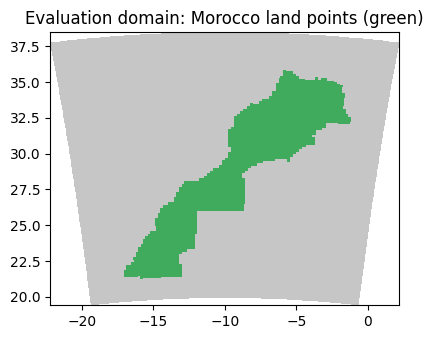

In [8]:
import calendar, shapefile as _pyshp, shapely
from shapely.geometry import shape as _shape
from shapely.ops import unary_union

# ---------------- land mask: Morocco only ----------------
def morocco_geometry(shp, field=None, names=MASK_NAMES):
    """Union of the shapefile features that belong to Morocco (matched on attribute text)."""
    try:    # some attribute columns hold garbled multilingual names: never let them stop the run
        rd = _pyshp.Reader(str(shp), encoding="utf-8", encodingErrors="replace")
    except TypeError:
        rd = _pyshp.Reader(str(shp), encoding="latin-1")
    cols = [f[0] for f in rd.fields[1:]]
    nm = {str(n).strip().lower() for n in names}
    picked, labels = [], []
    for sr in rd.shapeRecords():
        a = dict(zip(cols, sr.record))
        vals = [a.get(field)] if field else list(a.values())
        hit = [x for x in vals if isinstance(x, str) and
               (x.strip().lower() in nm or "morocco" in x.lower() or "maroc" in x.lower())]
        if hit:
            picked.append(sr.shape); labels.append(hit[0])
    if not picked:
        print("WARNING: no feature of", Path(shp).name, "matches", sorted(nm), "-> using ALL features of the file.")
        print("         Attribute columns:", cols)
        for sr in list(rd.shapeRecords())[:5]: print("        ", dict(zip(cols, sr.record)))
        print("         Set MASK_FIELD / MASK_NAMES in the config cell if the file contains other countries.")
        picked = [sr.shape for sr in rd.shapeRecords()]
    else:
        print("Morocco features selected from the shapefile:", sorted(set(labels)))
    geoms = [_shape(p.__geo_interface__).buffer(0) for p in picked]
    return unary_union(geoms)

def points_in(geom, lon, lat):
    if hasattr(shapely, "contains_xy"):
        return np.asarray(shapely.contains_xy(geom, lon, lat))
    from shapely import vectorized
    return np.asarray(vectorized.contains(geom, lon, lat))

if LAND_ONLY:
    if not SHP.exists():
        raise FileNotFoundError(f"shapefile not found: {SHP}. Fix SHP in the config cell, or set LAND_ONLY = False.")
    MORO = morocco_geometry(SHP, MASK_FIELD)
    MASK = points_in(MORO, np.asarray(LON, dtype="float64"), np.asarray(LAT, dtype="float64"))
    assert MASK.any(), ("no WRF grid point falls inside the selected shapefile geometry: check that the shapefile is in "
                        "lon/lat degrees (EPSG:4326) and that the right country was selected")
else:
    MASK = np.ones(LAT.shape, bool)
print(f"land mask: {int(MASK.sum())} of {MASK.size} grid points kept ({100 * MASK.mean():.0f}% of the domain)")

# set every point outside Morocco to NaN, in the forecasts and in ERA5 (all later cells then become land-only)
for _d in D.values():
    for _a in list(_d["fc"].values()) + list(_d["obs"].values()):
        _a[..., ~MASK] = np.nan

# ---------------- seasons ----------------
def day_season(day):
    t = D[day]["times"]
    mth = int(pd.Timestamp(t[len(t) // 2]).month)          # month of the middle of the simulated period
    for s, ms in SEASONS.items():
        if mth in ms: return s
    return None                                            # not in any season: kept in "all days" only

DAY_SEASON = {d: day_season(d) for d in D}
SEAS_LABEL = {"all": "All days"}
for _s, _m in SEASONS.items():
    SEAS_LABEL[_s] = f"{_s.capitalize()} ({calendar.month_abbr[_m[0]]}–{calendar.month_abbr[_m[-1]]})"
SEAS_LIST = ["all"] + [s for s in SEASONS if s in DAY_SEASON.values()]
for _s in SEASONS:
    n_ = sum(v == _s for v in DAY_SEASON.values())
    print(f"{SEAS_LABEL[_s]}: {n_} simulation day(s)" + ("   <-- none: this season is skipped" if n_ == 0 else ""))
print("days outside every season (only in 'All days'):", [d for d, s in DAY_SEASON.items() if s is None])

# quick look at the mask
fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.pcolormesh(LON, LAT, np.where(MASK, 1.0, np.nan), cmap="Greens", vmin=0, vmax=1.6, shading="auto")
ax.pcolormesh(LON, LAT, np.where(MASK, np.nan, 1.0), cmap="Greys", vmin=0, vmax=3, shading="auto")
ax.set_aspect("equal"); ax.set_title("Evaluation domain: Morocco land points (green)")
plt.show()


In [9]:
# Publication style (applies to all figures below)
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42,
})
def save_fig(fig, name):
    """Save vector PDF (for the journal) + high-res PNG."""
    fig.savefig(OUT / f"{name}.pdf"); fig.savefig(OUT / f"{name}.png")

In [10]:
# Helpers for the automatic written analysis that follows each figure
from IPython.display import Markdown, display
NL = chr(10)
def show(lines):
    display(Markdown(NL.join(lines)))

def disp_verdict(ssr):
    if ssr < 0.85: return "**under-dispersive** (spread too small for the error: over-confident)"
    if ssr > 1.15: return "**over-dispersive** (spread larger than the error warrants)"
    return "**close to calibrated**"

def crps_fair(ens, y):
    """Fair CRPS (Ferro 2014) for an ensemble ens (N,...) against y (...)."""
    n = ens.shape[0]
    a = np.abs(ens - y).mean(0)
    b = np.zeros_like(a)
    for i in range(n):
        for j in range(i + 1, n):
            b += np.abs(ens[i] - ens[j])
    return a - b / (n * (n - 1))


In [11]:
# Publication-quality spatial maps, drawn in the WRF projection so the domain is not distorted
try:
    import cartopy.crs as ccrs
    from cartopy.io import shapereader
    from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("cartopy not found -> plain lon/lat axes, shapefile not drawn (pip install cartopy)")

PROJ = ccrs.PlateCarree() if HAS_CARTOPY else None
EXTENT = [float(LON.min()), float(LON.max()), float(LAT.min()), float(LAT.max())]

# ---- projection of the WRF domain (read from the wrfout global attributes) ----
MAPPROJ, X, Y, EXT_P = None, None, None, None
if HAS_CARTOPY:
    try:
        _f = sorted((SIM[DAYS[0]] / CTRL / "wrf_out").glob("wrfout_d01_*"))[0]
        with nc.Dataset(str(_f)) as _ds:
            _mp = int(_ds.getncattr("MAP_PROJ"))
            _tl1, _tl2 = float(_ds.getncattr("TRUELAT1")), float(_ds.getncattr("TRUELAT2"))
            _slon, _clat = float(_ds.getncattr("STAND_LON")), float(_ds.getncattr("CEN_LAT"))
        print("MAP_PROJ", _mp, "| truelat", _tl1, _tl2, "| stand_lon", _slon, "| cen_lat", _clat)
        if _mp == 1:      # Lambert conformal
            MAPPROJ = ccrs.LambertConformal(central_longitude=_slon, central_latitude=_clat,
                                            standard_parallels=(_tl1, _tl2))
        elif _mp == 2:    # polar stereographic
            MAPPROJ = ccrs.Stereographic(central_longitude=_slon, central_latitude=_tl1)
        elif _mp == 3:    # Mercator
            MAPPROJ = ccrs.Mercator(central_longitude=_slon, latitude_true_scale=_tl1)
        else:             # lat-lon (6) or unknown
            MAPPROJ = ccrs.PlateCarree()
    except Exception as e:
        print("could not read projection from wrfout (", repr(e)[:80], ") -> estimating a Lambert projection")
        MAPPROJ = ccrs.LambertConformal(central_longitude=float(LON.mean()), central_latitude=float(LAT.mean()),
                                        standard_parallels=(float(LAT.min()), float(LAT.max())))
    _xyz = MAPPROJ.transform_points(PROJ, np.asarray(LON), np.asarray(LAT))
    X, Y = _xyz[..., 0], _xyz[..., 1]                       # grid in projection coordinates (metres)
    EXT_P = [float(X.min()), float(X.max()), float(Y.min()), float(Y.max())]

def _lines(g):
    t = g.geom_type
    if t == "Polygon":
        yield np.asarray(g.exterior.coords)[:, :2]
        for r in g.interiors:
            yield np.asarray(r.coords)[:, :2]
    elif t in ("LineString", "LinearRing"):
        yield np.asarray(g.coords)[:, :2]
    elif hasattr(g, "geoms"):
        for sub in g.geoms:
            yield from _lines(sub)

SHP_LINES = []   # only the parts of your shapefile that touch the WRF domain
if HAS_CARTOPY and SHP.exists():
    pad = 1.0
    for g in shapereader.Reader(str(SHP)).geometries():
        bx = g.bounds
        if bx[2] >= EXTENT[0] - pad and bx[0] <= EXTENT[1] + pad and bx[3] >= EXTENT[2] - pad and bx[1] <= EXTENT[3] + pad:
            SHP_LINES += list(_lines(g))
    print(len(SHP_LINES), "boundary segments loaded from", SHP.name)
elif HAS_CARTOPY:
    print("Shapefile not found:", SHP)

def map_panel(fig, ax, f, cmap, vmin, vmax, tag, title, mean_txt=None, show_left=True, show_bottom=True):
    if HAS_CARTOPY:
        im = ax.pcolormesh(X, Y, f, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", rasterized=True)  # already in projection coords
        for xy in SHP_LINES:
            ax.plot(xy[:, 0], xy[:, 1], transform=PROJ, color="k", lw=0.7, zorder=5)
        ax.set_extent(EXT_P, crs=MAPPROJ)                  # set once, after everything is drawn
        gl = ax.gridlines(draw_labels=True, lw=0.3, color="0.4", alpha=0.5, ls=":")
        gl.top_labels = gl.right_labels = False
        gl.left_labels, gl.bottom_labels = show_left, show_bottom
        gl.xlabel_style = gl.ylabel_style = {"size": 7}
        gl.xformatter, gl.yformatter = LONGITUDE_FORMATTER, LATITUDE_FORMATTER
    else:
        im = ax.pcolormesh(LON, LAT, f, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", rasterized=True)
        ax.set_xlim(EXTENT[:2]); ax.set_ylim(EXTENT[2:]); ax.set_aspect("equal")
        ax.spines[["top", "right"]].set_visible(True)
        if not show_left: ax.set_yticklabels([])
        if not show_bottom: ax.set_xticklabels([])
    ax.set_title(title, loc="left", pad=3)
    ax.text(0.02, 0.97, tag, transform=ax.transAxes, va="top", ha="left", fontsize=9, fontweight="bold",
            bbox=dict(fc="white", ec="none", alpha=0.8, pad=1.5))
    if mean_txt:
        ax.text(0.98, 0.03, mean_txt, transform=ax.transAxes, va="bottom", ha="right", fontsize=6.5,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1.5))
    return im


MAP_PROJ 1 | truelat 30.0 60.0 | stand_lon -10.0 | cen_lat 29.00000762939453
563 boundary segments loaded from maroc-world.shp


## 2c. Initial-conditions assessment (before looking at the WRF forecast)
Before judging the forecasts, check what each member *starts from*. At the first output time (lead 0 h) the WRF state is the initial condition, so each simulation's initial 2D fields are compared with ERA5 over Morocco:

* `ens0` vs ERA5: should be almost identical (only interpolation / terrain differences), a sanity check of the pipeline;
* each EraGAN member vs ERA5: error of the generated initial state, and which members are outliers;
* initial ensemble spread and ensemble-mean error: is the initial diversity sensible compared with the initial error?
* distance of each member to `ens0`: how far the generated states are from the ERA5-driven start.

Only the surface variables stored in the cache are available at lead 0 (T2, WS10; add `PSFC` to `VARS` to include surface pressure). Precipitation has no value at lead 0 and is not part of this section.

In [12]:
IC_VARS = [v for v in VARS if not v.startswith("PRECIP")]
IC_ROWS, IC_MEM = [], []
IC_MAP = {s: {v: {k: np.zeros(LAT.shape) for k in ["cnt", "bias_c", "bias_m", "var"]} for v in IC_VARS} for s in SEAS_LIST}

for day, d in D.items():
    j0 = int(np.argmin(d["lead"]))                       # first output time = initial condition
    if d["lead"][j0] != 0:
        print(day, f"first output is at lead {d['lead'][j0]:.0f} h, not 0 h")
    s_day = DAY_SEASON[day]
    keys = ["all"] + ([s_day] if s_day in IC_MAP else [])
    for v in IC_VARS:
        y = d["obs"][v][j0]
        if np.all(np.isnan(y)):
            continue
        ens, ctrl = d["fc"][v][1:, j0], d["fc"][v][0, j0]
        ok = np.isfinite(y) & np.isfinite(ctrl) & np.all(np.isfinite(ens), axis=0)
        if not ok.any():
            continue
        mean, var = ens.mean(0), ens.var(0, ddof=1)
        e_c, e_m = ctrl - y, mean - y
        m = lambda a: float(np.mean(a[ok]))
        IC_ROWS.append(dict(day=day, season=s_day, var=v, bias_c=m(e_c), bias_m=m(e_m),
                            mse_c=m(e_c**2), mse_m=m(e_m**2), var_ens=m(var), crps=m(crps_fair(ens, y)),
                            mse_mem=float(np.mean([m((ens[i] - y)**2) for i in range(N)])),
                            dist_c=float(np.mean([m((ens[i] - ctrl)**2) for i in range(N)]))))   # member -> ens0 distance
        for i, e in enumerate(MEMBERS):
            IC_MEM.append(dict(day=day, season=s_day, var=v, member=e, bias=m(ens[i] - y), mse=m((ens[i] - y)**2)))
        for s in keys:
            A = IC_MAP[s][v]
            A["cnt"] += ok; A["var"] += np.where(ok, var, 0)
            A["bias_c"] += np.where(ok, e_c, 0); A["bias_m"] += np.where(ok, e_m, 0)

ICR, ICM = pd.DataFrame(IC_ROWS), pd.DataFrame(IC_MEM)
assert len(ICR), "no initial-condition data found (is lead 0 present and ERA5 available?)"

def ic_summary(g):
    s = pd.Series(dtype=float)
    s["n_days"]        = g.day.nunique()
    s["bias_ens0"]     = g.bias_c.mean()
    s["rmse_ens0"]     = np.sqrt(g.mse_c.mean())
    s["rmse_members"]  = np.sqrt(g.mse_mem.mean())          # typical single-member error
    s["bias_mean"]     = g.bias_m.mean()
    s["rmse_mean"]     = np.sqrt(g.mse_m.mean())           # ensemble-mean error
    s["spread"]        = np.sqrt(g.var_ens.mean())
    s["SSR"]           = np.sqrt((N + 1) / N) * s["spread"] / s["rmse_mean"] if s["rmse_mean"] > 0 else np.nan
    s["dist_to_ens0"]  = np.sqrt(g.dist_c.mean())          # RMS difference member - ens0
    s["crps"]          = g.crps.mean()
    return s

IC_TAB = {}
for s in SEAS_LIST:
    g = ICR if s == "all" else ICR[ICR.season == s]
    if len(g):
        IC_TAB[s] = g.groupby("var").apply(ic_summary).loc[[v for v in IC_VARS if v in set(g["var"])]]
        IC_TAB[s].to_csv(OUT / f"initial_conditions_summary{'' if s == 'all' else '_' + s}.csv")
IC_ALL = pd.concat({s: IC_TAB[s] for s in IC_TAB}, names=["period", "var"])
ICM.groupby(["season", "var", "member"], dropna=False).agg(bias=("bias", "mean"), mse=("mse", "mean")).assign(
    rmse=lambda x: np.sqrt(x.mse)).to_csv(OUT / "initial_conditions_per_member.csv")
IC_ALL.round(3)


n_days  bias_ens0  rmse_ens0  rmse_members  bias_mean  rmse_mean  \
period var                                                                      
all    T2     337.0     -0.013      0.140         7.241      3.028      6.054   
       WS10   337.0     -0.016      0.276         3.498      1.035      2.724   
       PSFC   337.0     -0.388      6.867         6.867     -0.388      6.867   
winter T2     169.0     -0.020      0.138         7.352      4.304      6.440   
       WS10   169.0     -0.016      0.264         3.607      1.612      2.760   
       PSFC   169.0     -0.446      7.025         7.025     -0.446      7.025   
summer T2     168.0     -0.007      0.142         7.127      1.745      5.638   
       WS10   168.0     -0.015      0.287         3.386      0.454      2.687   
       PSFC   168.0     -0.328      6.705         6.705     -0.328      6.705   

             spread    SSR  dist_to_ens0   crps  
period var                                       
all    T2     4.188  0.726         7.281  3.474  
       WS10   2.314  0.891         3.525  1.500  
       PSFC   0.000  0.000         0.000  3.974  
winter T2     3.739  0.609         7.392  3.783  
       WS10   2.449  0.931         3.631  1.469  
       PSFC   0.000  0.000         0.000  4.061  
summer T2     4.595  0.855         7.168  3.164  
       WS10   2.171  0.847         3.414  1.531  
       PSFC   0.000  0.000         0.000  3.887

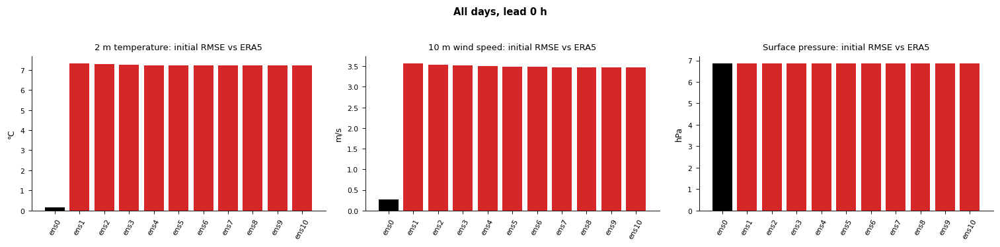

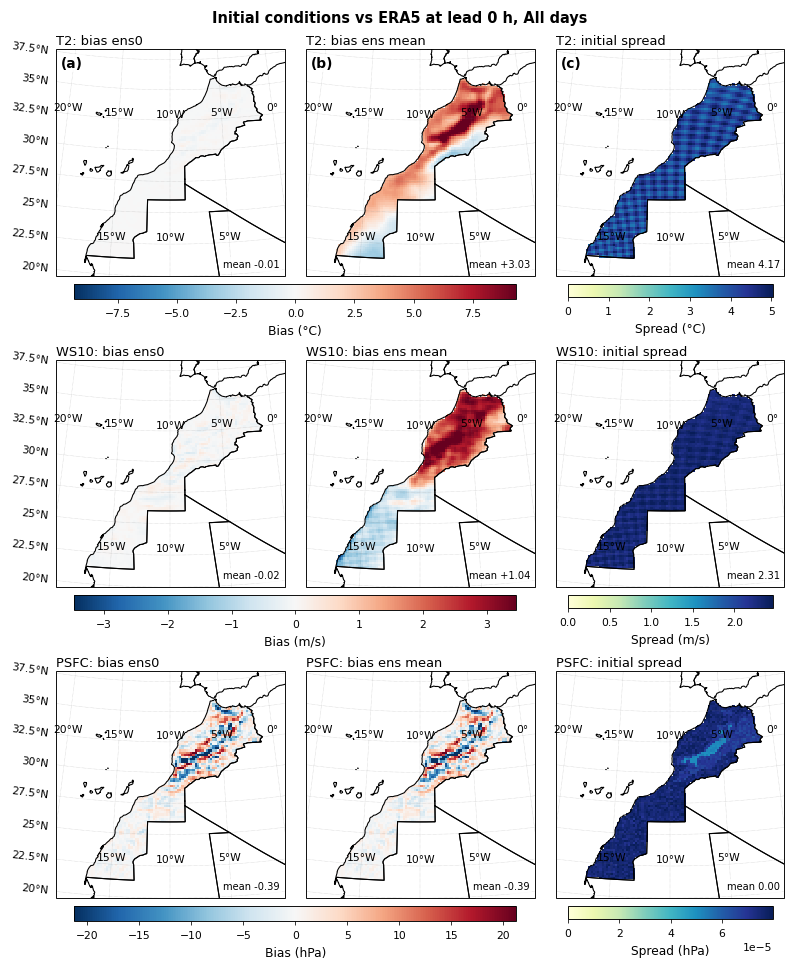

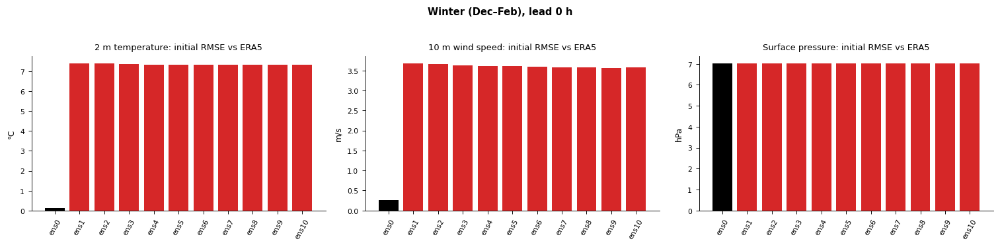

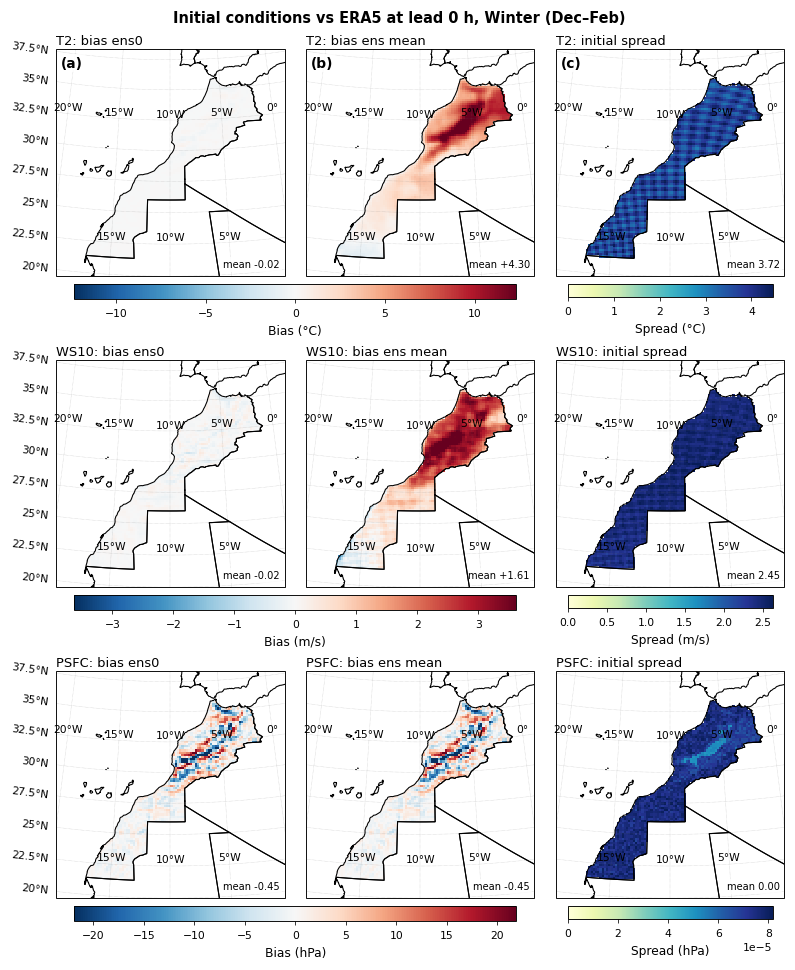

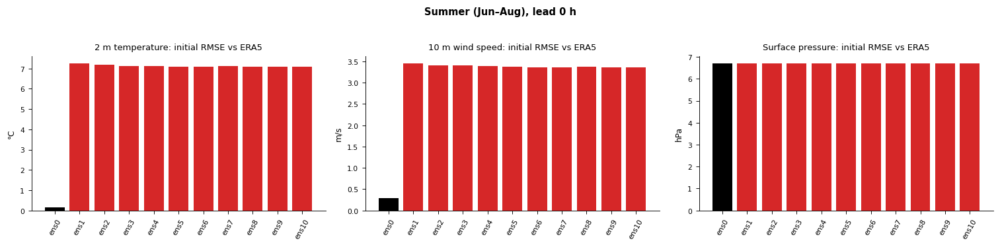

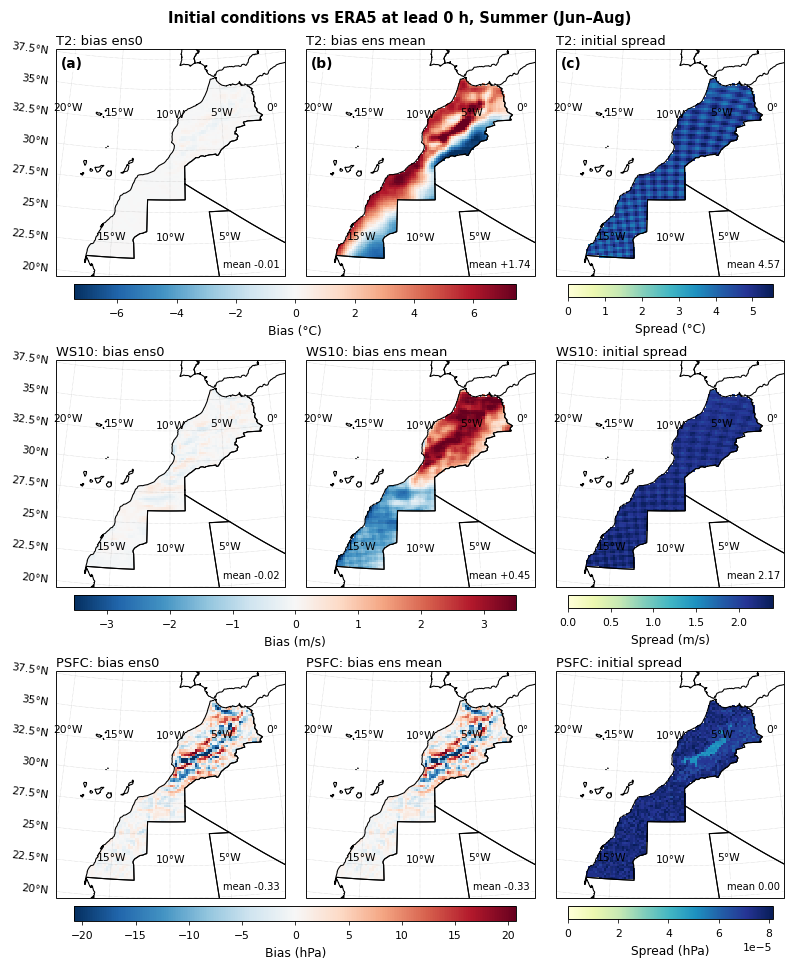

In [13]:
# Initial conditions: per-member error (bars) and maps of the initial bias and spread, for each period
for SEAS in [s for s in SEAS_LIST if s in IC_TAB]:
    SLAB = SEAS_LABEL[SEAS]; SFX = "" if SEAS == "all" else "_" + SEAS
    g = ICM if SEAS == "all" else ICM[ICM.season == SEAS]
    gr = ICR if SEAS == "all" else ICR[ICR.season == SEAS]
    # (1) per-member RMSE against ERA5 at lead 0
    fig, axes = plt.subplots(1, len(IC_VARS), figsize=(4.6 * len(IC_VARS), 3.2), squeeze=False)
    for i, v in enumerate(IC_VARS):
        gv = g[g["var"] == v]
        r0 = np.sqrt(gr[gr["var"] == v].mse_c.mean())
        rm = np.sqrt(gv.groupby("member").mse.mean()).reindex(MEMBERS)
        axes[0, i].bar(["ens0"] + MEMBERS, [r0] + list(rm.values), color=["k"] + ["tab:red"] * N)
        axes[0, i].set_title(f"{VARS[v]['label']}: initial RMSE vs ERA5"); axes[0, i].set_ylabel(VARS[v]["unit"])
        axes[0, i].tick_params(axis="x", rotation=60)
    fig.suptitle(SLAB + ", lead 0 h", fontweight="bold", y=1.04); plt.tight_layout(); save_fig(fig, "initial_conditions_members" + SFX); plt.show()
    # (2) maps: ens0 bias, ensemble-mean bias, initial ensemble spread
    kw = dict(subplot_kw=dict(projection=MAPPROJ)) if HAS_CARTOPY else {}
    fig, axes = plt.subplots(len(IC_VARS), 3, figsize=(7.2, 2.9 * len(IC_VARS)), constrained_layout=True, squeeze=False, **kw)
    for i, v in enumerate(IC_VARS):
        M = IC_MAP[SEAS][v]; nz = M["cnt"] == 0; c = np.maximum(M["cnt"], 1); u = VARS[v]["unit"]
        b_c, b_m, spr = M["bias_c"] / c, M["bias_m"] / c, np.sqrt(M["var"] / c)
        for a_ in (b_c, b_m, spr): a_[nz] = np.nan
        bl = np.nanpercentile(np.abs(np.r_[b_c.ravel(), b_m.ravel()]), 98) or 1e-6
        sh = np.nanpercentile(spr, 98) or 1e-6
        ims = [map_panel(fig, axes[i, 0], b_c, "RdBu_r", -bl, bl, "(a)" if i == 0 else "", f"{v}: bias ens0", f"mean {np.nanmean(b_c):+.2f}", True, i == len(IC_VARS) - 1),
               map_panel(fig, axes[i, 1], b_m, "RdBu_r", -bl, bl, "(b)" if i == 0 else "", f"{v}: bias ens mean", f"mean {np.nanmean(b_m):+.2f}", False, i == len(IC_VARS) - 1),
               map_panel(fig, axes[i, 2], spr, "YlGnBu", 0, sh, "(c)" if i == 0 else "", f"{v}: initial spread", f"mean {np.nanmean(spr):.2f}", False, i == len(IC_VARS) - 1)]
        for im, a_, lab in [(ims[0], [axes[i, 0], axes[i, 1]], f"Bias ({u})"), (ims[2], [axes[i, 2]], f"Spread ({u})")]:
            cb = fig.colorbar(im, ax=a_, orientation="horizontal", shrink=0.9 if len(a_) > 1 else 0.85, pad=0.03, aspect=30 if len(a_) > 1 else 16)
            cb.set_label(lab); cb.ax.tick_params(width=0.5, length=2.5)
    fig.suptitle(f"Initial conditions vs ERA5 at lead 0 h, {SLAB}", fontsize=9.5, fontweight="bold")
    save_fig(fig, "initial_conditions_maps" + SFX); plt.show()


In [14]:
for SEAS in [s for s in SEAS_LIST if s in IC_TAB]:
    SLAB = SEAS_LABEL[SEAS]
    t_all = IC_TAB[SEAS]
    g = ICM if SEAS == "all" else ICM[ICM.season == SEAS]
    L = [f"### Analysis: initial conditions — {SLAB}", ""]
    for v in IC_VARS:
        t, u = t_all.loc[v], VARS[v]["unit"]
        r = np.sqrt(g[g["var"] == v].groupby("member").mse.mean()).reindex(MEMBERS)
        med = r.median(); mad = (r - med).abs().median()
        bad = [k for k, x in r.items() if x > 1.15 * med or (mad > 0 and x > med + 3 * 1.4826 * mad)]
        L.append(f"- **{VARS[v]['label']}** ({int(t.n_days)} days): `ens0` starts from ERA5 with bias {t.bias_ens0:+.3f} and RMSE {t.rmse_ens0:.3f} {u} "
                 f"({'as expected, essentially the ERA5 state' if t.rmse_ens0 < 0.5 * max(t.rmse_members, 1e-9) else 'not negligible: check the WRF initialisation / interpolation'}). "
                 f"The EraGAN initial states have a typical RMSE of {t.rmse_members:.3f} {u} (members range {r.min():.3f} [{r.idxmin()}] to {r.max():.3f} [{r.idxmax()}]) and lie {t.dist_to_ens0:.3f} {u} (RMS) from `ens0`. "
                 f"The ensemble-mean initial error is {t.rmse_mean:.3f} {u} against an initial spread of {t.spread:.3f} {u} (SSR {t.SSR:.2f}, {disp_verdict(t.SSR) if np.isfinite(t.SSR) else 'n/a'}). "
                 + ("Outlier member(s) at the start: " + ", ".join(bad) + "." if bad else "No outlier member at the start."))
        if t.spread < 1e-3:
            L.append(f"  - The initial spread is ~0: the members start practically identical, so any later spread must come from the model.")
    L.append("")
    L.append("*A healthy ensemble starts with a spread comparable to the initial error of its mean (SSR near 1). A much smaller spread means the EraGAN states are too close to each other; a member with a clearly larger RMSE is a bad initial state to inspect before running WRF with it.*")
    L[0] = L[0]
    show(L)


### Analysis: initial conditions — All days

- **2 m temperature** (337 days): `ens0` starts from ERA5 with bias -0.013 and RMSE 0.140 °C (as expected, essentially the ERA5 state). The EraGAN initial states have a typical RMSE of 7.241 °C (members range 7.216 [ens6] to 7.325 [ens1]) and lie 7.281 °C (RMS) from `ens0`. The ensemble-mean initial error is 6.054 °C against an initial spread of 4.188 °C (SSR 0.73, **under-dispersive** (spread too small for the error: over-confident)). Outlier member(s) at the start: ens1, ens2.
- **10 m wind speed** (337 days): `ens0` starts from ERA5 with bias -0.016 and RMSE 0.276 m/s (as expected, essentially the ERA5 state). The EraGAN initial states have a typical RMSE of 3.498 m/s (members range 3.464 [ens9] to 3.569 [ens1]) and lie 3.525 m/s (RMS) from `ens0`. The ensemble-mean initial error is 2.724 m/s against an initial spread of 2.314 m/s (SSR 0.89, **close to calibrated**). Outlier member(s) at the start: ens1.
- **Surface pressure** (337 days): `ens0` starts from ERA5 with bias -0.388 and RMSE 6.867 hPa (not negligible: check the WRF initialisation / interpolation). The EraGAN initial states have a typical RMSE of 6.867 hPa (members range 6.867 [ens1] to 6.867 [ens1]) and lie 0.000 hPa (RMS) from `ens0`. The ensemble-mean initial error is 6.867 hPa against an initial spread of 0.000 hPa (SSR 0.00, **under-dispersive** (spread too small for the error: over-confident)). No outlier member at the start.
  - The initial spread is ~0: the members start practically identical, so any later spread must come from the model.

*A healthy ensemble starts with a spread comparable to the initial error of its mean (SSR near 1). A much smaller spread means the EraGAN states are too close to each other; a member with a clearly larger RMSE is a bad initial state to inspect before running WRF with it.*

### Analysis: initial conditions — Winter (Dec–Feb)

- **2 m temperature** (169 days): `ens0` starts from ERA5 with bias -0.020 and RMSE 0.138 °C (as expected, essentially the ERA5 state). The EraGAN initial states have a typical RMSE of 7.352 °C (members range 7.319 [ens4] to 7.405 [ens2]) and lie 7.392 °C (RMS) from `ens0`. The ensemble-mean initial error is 6.440 °C against an initial spread of 3.739 °C (SSR 0.61, **under-dispersive** (spread too small for the error: over-confident)). Outlier member(s) at the start: ens2.
- **10 m wind speed** (169 days): `ens0` starts from ERA5 with bias -0.016 and RMSE 0.264 m/s (as expected, essentially the ERA5 state). The EraGAN initial states have a typical RMSE of 3.607 m/s (members range 3.567 [ens9] to 3.679 [ens1]) and lie 3.631 m/s (RMS) from `ens0`. The ensemble-mean initial error is 2.760 m/s against an initial spread of 2.449 m/s (SSR 0.93, **close to calibrated**). No outlier member at the start.
- **Surface pressure** (169 days): `ens0` starts from ERA5 with bias -0.446 and RMSE 7.025 hPa (not negligible: check the WRF initialisation / interpolation). The EraGAN initial states have a typical RMSE of 7.025 hPa (members range 7.025 [ens1] to 7.025 [ens1]) and lie 0.000 hPa (RMS) from `ens0`. The ensemble-mean initial error is 7.025 hPa against an initial spread of 0.000 hPa (SSR 0.00, **under-dispersive** (spread too small for the error: over-confident)). No outlier member at the start.
  - The initial spread is ~0: the members start practically identical, so any later spread must come from the model.

*A healthy ensemble starts with a spread comparable to the initial error of its mean (SSR near 1). A much smaller spread means the EraGAN states are too close to each other; a member with a clearly larger RMSE is a bad initial state to inspect before running WRF with it.*

### Analysis: initial conditions — Summer (Jun–Aug)

- **2 m temperature** (168 days): `ens0` starts from ERA5 with bias -0.007 and RMSE 0.142 °C (as expected, essentially the ERA5 state). The EraGAN initial states have a typical RMSE of 7.127 °C (members range 7.087 [ens10] to 7.253 [ens1]) and lie 7.168 °C (RMS) from `ens0`. The ensemble-mean initial error is 5.638 °C against an initial spread of 4.595 °C (SSR 0.85, **close to calibrated**). Outlier member(s) at the start: ens1, ens2.
- **10 m wind speed** (168 days): `ens0` starts from ERA5 with bias -0.015 and RMSE 0.287 m/s (as expected, essentially the ERA5 state). The EraGAN initial states have a typical RMSE of 3.386 m/s (members range 3.357 [ens9] to 3.455 [ens1]) and lie 3.414 m/s (RMS) from `ens0`. The ensemble-mean initial error is 2.687 m/s against an initial spread of 2.171 m/s (SSR 0.85, **under-dispersive** (spread too small for the error: over-confident)). Outlier member(s) at the start: ens1.
- **Surface pressure** (168 days): `ens0` starts from ERA5 with bias -0.328 and RMSE 6.705 hPa (not negligible: check the WRF initialisation / interpolation). The EraGAN initial states have a typical RMSE of 6.705 hPa (members range 6.705 [ens1] to 6.705 [ens1]) and lie 0.000 hPa (RMS) from `ens0`. The ensemble-mean initial error is 6.705 hPa against an initial spread of 0.000 hPa (SSR 0.00, **under-dispersive** (spread too small for the error: over-confident)). No outlier member at the start.
  - The initial spread is ~0: the members start practically identical, so any later spread must come from the model.

*A healthy ensemble starts with a spread comparable to the initial error of its mean (SSR near 1). A much smaller spread means the EraGAN states are too close to each other; a member with a clearly larger RMSE is a bad initial state to inspect before running WRF with it.*

## 3. Metrics

**Event definition (changed).** The event thresholds are now computed **per season** from the ERA5 days of that season (previously one p90 pooled over all days was reused in winter and summer). The tail follows the physics: upper tail (`> p90`) for every variable, except the **winter 2 m temperature**, where the extreme is the cold tail (`< p10`). Set `COLD_T2_WINTER = False` in the config cell to go back to a winter p90 for T2. Each day is scored with the threshold of its own season; the `all` tables simply pool those scores.

In [15]:
LEAD_BINS = [(0, 24), (24, 48), (48, 1e9)]
LEAD_LAB  = ["<24 h", "24–48 h", ">48 h"]
def lead_bin(h):
    for k, (a, b) in enumerate(LEAD_BINS):
        if a <= h < b: return k

# ---- event definition: tail direction and threshold depend on the variable AND on the season ----
# upper tail (value > pPCTL) for every variable, except the 2 m temperature in winter, where the extreme is the cold tail
# (value < p(100-PCTL)): a "p90" of winter temperature would only measure unusually mild days.
def event_def(v, s):
    """(sign, percentile) of the event for variable v in period s ('winter', 'summer', 'all')."""
    if COLD_T2_WINTER and v == "T2" and s == "winter":
        return "<", 100 - PCTL
    return ">", PCTL

def ev(a, thr, sg):
    """Boolean event array: a < thr for the cold tail, a > thr for the upper tail (NaN -> False)."""
    return (a < thr) if sg == "<" else (a > thr)

# thresholds from the ERA5 distribution of THAT season only (land points only: ocean points are NaN)
THR, EVSIGN, EVPCT = {}, {}, {}
for _s in SEAS_LIST:                        # "all" is only the fallback for days outside every season
    _days = [d for d in D if _s == "all" or DAY_SEASON[d] == _s]
    for v in VARS:
        _sg, _pc = event_def(v, _s)
        _x = np.concatenate([D[d]["obs"][v][:, ::STRIDE, ::STRIDE].ravel() for d in _days])
        _t = float(np.nanpercentile(_x, _pc))
        if _sg == ">": _t = max(_t, VARS[v].get("thr_min", -np.inf))     # thr_min: floor for zero-inflated variables (precipitation)
        THR[(_s, v)], EVSIGN[(_s, v)], EVPCT[(_s, v)] = _t, _sg, _pc

def EVLAB(v, s):
    """Readable event label for titles and texts, e.g. '< p10 (11.3 °C)'."""
    u = VARS[v]["unit"]
    if s != "all" and (s, v) in THR:
        return f"{EVSIGN[(s, v)]} p{EVPCT[(s, v)]} ({THR[(s, v)]:.1f} {u})"
    return " / ".join(f"{EVSIGN[(x, v)]} p{EVPCT[(x, v)]} ({THR[(x, v)]:.1f} {u}, {x[:3]})" for x in SEAS_LIST if x != "all")

print("event thresholds (season-specific):")
for _s in SEAS_LIST:
    print(f"  {_s:7s}", {v: f"{EVSIGN[(_s, v)]} p{EVPCT[(_s, v)]} = {THR[(_s, v)]:.2f}" for v in VARS})

RNG_RANK = np.random.default_rng(42)     # random rank among tied values (dry points) in the rank histogram
shape2d  = LAT.shape

def new_acc():
    """Accumulators (rank histogram, reliability, maps) for ONE period (all days / winter / summer)."""
    return dict(rank={(v, k): np.zeros(N + 1) for v in VARS for k in range(len(LEAD_BINS))},
                rel_n={v: np.zeros(N + 1) for v in VARS}, rel_o={v: np.zeros(N + 1) for v in VARS},
                MAP={v: {k: np.zeros(shape2d) for k in ["cnt", "bias_c", "bias_m", "se_c", "se_m", "var"]} for v in VARS})
ACC = {s: new_acc() for s in SEAS_LIST}

rows = []
for day, d in D.items():
    s_day = DAY_SEASON[day]
    tk = s_day if s_day in SEAS_LIST else "all"          # key of the event thresholds used for this day
    accs = [ACC["all"]] + ([ACC[s_day]] if s_day in ACC else [])      # every day feeds "all" and its own season
    for j, h in enumerate(d["lead"]):
        if h < SPINUP_H:
            continue
        for v in VARS:
            y = d["obs"][v][j]
            if np.all(np.isnan(y)):
                continue
            ens  = d["fc"][v][1:, j]
            ctrl = d["fc"][v][0, j]
            ok   = np.isfinite(y) & np.isfinite(ctrl) & np.all(np.isfinite(ens), axis=0)
            if ok.sum() == 0:
                continue
            mean = ens.mean(0)
            var  = ens.var(0, ddof=1)
            e_c, e_m = ctrl - y, mean - y
            crps = crps_fair(ens, y)
            # event (Brier)
            thr, sg = THR[(tk, v)], EVSIGN[(tk, v)]
            o  = ev(y, thr, sg).astype(float)
            k  = ev(ens, thr, sg).sum(0)
            p  = k / N
            pc = ev(ctrl, thr, sg).astype(float)
            m  = lambda a: float(np.mean(a[ok]))
            # contingency counts for POD / FAR / CSI: control, ensemble mean, majority vote (>= half of the members)
            ob = o.astype(bool)
            cnt = {}
            for key, f in (("c", ev(ctrl, thr, sg)), ("m", ev(mean, thr, sg)), ("p", p >= 0.5)):
                cnt[f"hit_{key}"] = int((f & ob & ok).sum())
                cnt[f"mis_{key}"] = int((~f & ob & ok).sum())
                cnt[f"fa_{key}"]  = int((f & ~ob & ok).sum())
                cnt[f"cn_{key}"]  = int((~f & ~ob & ok).sum())      # correct negatives (needed for ETS / HK / HSS / ORSS)
            rows.append(dict(day=day, season=s_day, lead=h, var=v,
                             bias_c=m(e_c), bias_m=m(e_m),
                             mse_c=m(e_c**2), mse_m=m(e_m**2), mae_c=m(np.abs(e_c)),
                             var_ens=m(var), crps=m(crps),
                             bs_ens=m((p - o)**2), bs_ctrl=m((pc - o)**2), o_rate=m(o), **cnt))
            # rank histogram (subsampled)
            sl = (slice(None, None, STRIDE), slice(None, None, STRIDE))
            okk = ok[sl]
            es, ys = ens[(slice(None),) + sl], y[sl]
            r = ((es < ys).sum(0) + np.floor(RNG_RANK.random(ys.shape) * ((es == ys).sum(0) + 1)).astype(int))[okk]
            rk = np.bincount(r, minlength=N + 1)
            # reliability
            kk = k[sl][okk]; oo = o[sl][okk]
            rn, ro = np.bincount(kk, minlength=N + 1), np.bincount(kk, weights=oo, minlength=N + 1)
            for A in accs:
                A["rank"][(v, lead_bin(h))] += rk
                A["rel_n"][v] += rn
                A["rel_o"][v] += ro
                # maps
                M = A["MAP"][v]
                M["cnt"] += ok
                M["bias_c"] += np.where(ok, e_c, 0); M["bias_m"] += np.where(ok, e_m, 0)
                M["se_c"] += np.where(ok, e_c**2, 0); M["se_m"] += np.where(ok, e_m**2, 0)
                M["var"] += np.where(ok, var, 0)

R = pd.DataFrame(rows)
print(R.shape, "rows;", R["day"].nunique(), "days;", R.groupby("season").day.nunique().to_dict(), "days per season")
R.head()


event thresholds (season-specific):
  all     {'T2': '> p90 = 33.57', 'WS10': '> p90 = 7.61', 'PSFC': '> p90 = 1001.01', 'PRECIP_ACC': '> p90 = 1.00', 'PRECIP': '> p90 = 0.10'}
  winter  {'T2': '< p10 = 5.14', 'WS10': '> p90 = 7.27', 'PSFC': '> p90 = 1003.50', 'PRECIP_ACC': '> p90 = 1.00', 'PRECIP': '> p90 = 0.10'}
  summer  {'T2': '> p90 = 36.97', 'WS10': '> p90 = 7.87', 'PSFC': '> p90 = 998.17', 'PRECIP_ACC': '> p90 = 1.00', 'PRECIP': '> p90 = 0.10'}
(36125, 26) rows; 337 days; {'summer': 170, 'winter': 167} days per season


,day,season,lead,var,bias_c,bias_m,mse_c,mse_m,mae_c,var_ens,...,fa_c,cn_c,hit_m,mis_m,fa_m,cn_m,hit_p,mis_p,fa_p,cn_p
0,2017_12_01,winter,3.0,T2,-2.089144,-2.158294,7.560596,8.110201,2.262165,0.237259,...,32,1707,0,0,29,1710,0,0,28,1711
1,2017_12_01,winter,3.0,WS10,0.811314,0.926919,3.676588,4.085700,1.260556,0.292506,...,165,1543,16,15,171,1537,17,14,181,1527
2,2017_12_01,winter,3.0,PSFC,0.493677,0.479653,48.359383,47.989079,4.175703,0.003935,...,17,1627,91,4,17,1627,91,4,17,1627
3,2017_12_01,winter,3.0,PRECIP,0.041662,0.055174,0.187843,0.205890,0.112872,0.009125,...,3,1395,193,148,5,1393,200,141,7,1391
4,2017_12_01,winter,6.0,T2,-2.689044,-2.719271,11.753297,12.402023,2.772892,0.074828,...,35,1702,2,0,32,1705,2,0,33,1704


In [16]:
def _div(a, b):
    return float(a) / float(b) if b > 0 else np.nan

def summarize(g):
    s = pd.Series(dtype=float)
    s["n"]          = len(g)
    s["bias_ctrl"]  = g.bias_c.mean()
    s["bias_mean"]  = g.bias_m.mean()
    s["rmse_ctrl"]  = np.sqrt(g.mse_c.mean())
    s["rmse_mean"]  = np.sqrt(g.mse_m.mean())
    s["mae_ctrl"]   = g.mae_c.mean()
    s["spread"]     = np.sqrt(g.var_ens.mean())
    s["crps_ens"]   = g.crps.mean()
    s["SSR"]        = np.sqrt((N + 1) / N) * s["spread"] / s["rmse_mean"]      # ideal = 1
    s["RMSE_gain_%"] = 100 * (1 - s["rmse_mean"] / s["rmse_ctrl"])
    s["CRPSS_vs_ctrl"] = 1 - s["crps_ens"] / s["mae_ctrl"]                      # >0: ensemble beats control
    ob = g.o_rate.mean()
    s["BSS_ens"]  = 1 - g.bs_ens.mean()  / (ob * (1 - ob))
    s["BSS_ctrl"] = 1 - g.bs_ctrl.mean() / (ob * (1 - ob))
    # categorical scores for the p90 event: counts are SUMMED over days / leads, then the ratios are formed
    for k, nm in (("c", "ctrl"), ("m", "mean"), ("p", "maj")):
        h, ms, fa = g[f"hit_{k}"].sum(), g[f"mis_{k}"].sum(), g[f"fa_{k}"].sum()
        s[f"POD_{nm}"] = _div(h, h + ms)             # probability of detection = hits / (hits + misses)
        s[f"FAR_{nm}"] = _div(fa, h + fa)            # false alarm ratio = false alarms / (hits + false alarms)
        s[f"CSI_{nm}"] = _div(h, h + ms + fa)        # critical success index = hits / (hits + misses + false alarms)
        s[f"FBI_{nm}"] = _div(h + fa, h + ms)        # frequency bias = forecast events / observed events
    s["n_events"] = float(g["hit_c"].sum() + g["mis_c"].sum())     # observed event points
    return s

# one set of tables per period: "all" days, then each season
STATS = {}
for s in SEAS_LIST:
    g_ = R if s == "all" else R[R.season == s]
    if g_.empty:
        print("no data for", s, "-> skipped"); continue
    vs = [v for v in VARS if v in set(g_["var"])]
    sfx = "" if s == "all" else "_" + s
    STATS[s] = dict(SUMMARY=g_.groupby("var").apply(summarize).loc[vs],
                    LEADTAB=g_.groupby(["var", "lead"]).apply(summarize),
                    DAYTAB=g_.groupby(["var", "day"]).apply(summarize))
    STATS[s]["SUMMARY"].to_csv(OUT / f"summary_by_variable{sfx}.csv")
    STATS[s]["LEADTAB"].to_csv(OUT / f"summary_by_lead{sfx}.csv")
    STATS[s]["DAYTAB"].to_csv(OUT / f"summary_by_day{sfx}.csv")
SEAS_LIST = [s for s in SEAS_LIST if s in STATS]

def use_season(s):
    """Point the tables / accumulators used by the plotting cells at one period ('all', 'winter', 'summer')."""
    global SUMMARY, LEADTAB, DAYTAB, CI, rank_cnt, rel_n, rel_o, MAP, DSEL, SFX, SLAB
    st = STATS[s]
    SUMMARY, LEADTAB, DAYTAB, CI = st["SUMMARY"], st["LEADTAB"], st["DAYTAB"], st.get("CI")
    A = ACC[s]; rank_cnt, rel_n, rel_o, MAP = A["rank"], A["rel_n"], A["rel_o"], A["MAP"]
    DSEL = {d: D[d] for d in D if s == "all" or DAY_SEASON[d] == s}
    SFX, SLAB = ("" if s == "all" else "_" + s), SEAS_LABEL[s]

SUMMARY_ALL = pd.concat({s: STATS[s]["SUMMARY"] for s in SEAS_LIST}, names=["period", "var"])
SUMMARY_ALL.to_csv(OUT / "summary_by_variable_by_season.csv")
SUMMARY_ALL.round(3)


n  bias_ctrl  bias_mean  rmse_ctrl  rmse_mean  \
period var                                                              
all    T2          8029.0     -1.477     -1.428      3.096      3.084   
       WS10        8029.0      0.990      0.983      2.145      2.124   
       PSFC        8029.0     -0.283     -0.292      6.877      6.874   
       PRECIP_ACC  4012.0      0.060      0.060      0.736      0.702   
       PRECIP      8026.0      0.011      0.011      0.147      0.138   
winter T2          4008.0     -1.714     -1.661      3.029      3.003   
       WS10        4008.0      0.873      0.871      2.100      2.084   
       PSFC        4008.0     -0.118     -0.132      7.084      7.079   
       PRECIP_ACC  2004.0      0.119      0.118      0.971      0.938   
       PRECIP      4008.0      0.021      0.021      0.191      0.182   
summer T2          4021.0     -1.242     -1.195      3.161      3.163   
       WS10        4021.0      1.106      1.095      2.190      2.164   
       PSFC        4021.0     -0.448     -0.452      6.664      6.663   
       PRECIP_ACC  2008.0      0.001      0.002      0.378      0.328   
       PRECIP      4018.0      0.001      0.001      0.082      0.070   

                   mae_ctrl  spread  crps_ens    SSR  RMSE_gain_%  ...  \
period var                                                         ...   
all    T2             2.398   0.249     2.314  0.085        0.383  ...   
       WS10           1.542   0.326     1.444  0.161        1.000  ...   
       PSFC           4.049   0.062     4.027  0.010        0.046  ...   
       PRECIP_ACC     0.090   0.253     0.073  0.378        4.629  ...   
       PRECIP         0.015   0.058     0.012  0.443        6.263  ...   
winter T2             2.355   0.238     2.258  0.083        0.876  ...   
       WS10           1.470   0.283     1.374  0.143        0.788  ...   
       PSFC           4.177   0.046     4.155  0.007        0.071  ...   
       PRECIP_ACC     0.158   0.261     0.130  0.292        3.403  ...   
       PRECIP         0.027   0.061     0.022  0.351        4.662  ...   
summer T2             2.442   0.260     2.369  0.086       -0.066  ...   
       WS10           1.614   0.364     1.513  0.176        1.194  ...   
       PSFC           3.922   0.075     3.900  0.012        0.017  ...   
       PRECIP_ACC     0.022   0.244     0.017  0.780       13.127  ...   
       PRECIP         0.003   0.055     0.002  0.833       15.388  ...   

                   FBI_ctrl  POD_mean  FAR_mean  CSI_mean  FBI_mean  POD_maj  \
period var                                                                     
all    T2             1.365     0.870     0.354     0.589     1.347    0.870   
       WS10           1.716     0.810     0.524     0.428     1.702    0.813   
       PSFC           1.043     0.956     0.081     0.882     1.041    0.956   
       PRECIP_ACC     1.553     0.752     0.528     0.408     1.593    0.744   
       PRECIP         1.104     0.611     0.434     0.416     1.081    0.622   
winter T2             1.649     0.890     0.446     0.519     1.606    0.891   
       WS10           1.637     0.793     0.513     0.432     1.629    0.796   
       PSFC           1.063     0.966     0.090     0.881     1.062    0.966   
       PRECIP_ACC     1.632     0.813     0.510     0.440     1.661    0.809   
       PRECIP         1.193     0.684     0.408     0.465     1.154    0.698   
summer T2             1.106     0.851     0.234     0.676     1.110    0.852   
       WS10           1.796     0.827     0.534     0.424     1.774    0.829   
       PSFC           1.022     0.946     0.072     0.882     1.020    0.947   
       PRECIP_ACC     0.898     0.243     0.765     0.136     1.034    0.207   
       PRECIP         0.538     0.150     0.756     0.103     0.615    0.135   

                   FAR_maj  CSI_maj  FBI_maj   n_events  
period var                                               
all    T2            0.357    0.587    1.353  

### How to read the headline table
| Column | Meaning | Good |
|---|---|---|
| `RMSE_gain_%` | ensemble-mean RMSE vs control RMSE | > 0 |
| `CRPSS_vs_ctrl` | fair CRPS of the ensemble vs MAE of the control (its CRPS) | > 0 |
| `SSR` | spread-skill ratio (finite-size corrected) | ≈ 1 (< 1 under-dispersive, > 1 over-dispersive) |
| `BSS_ens` | Brier skill score for the p90 event vs climatology | > 0, and > `BSS_ctrl` |
| `POD_*` | probability of detection = hits / (hits + misses) | → 1 |
| `FAR_*` | false alarm ratio = false alarms / (hits + false alarms) | → 0 |
| `CSI_*` | critical success index = hits / (hits + misses + false alarms) | → 1 |
| `FBI_*` | frequency bias = forecast events / observed events | ≈ 1 (< 1 under-forecasts the event, > 1 over-forecasts it) |

`*` = `ctrl` (`ens0`), `mean` (ensemble mean exceeds the threshold) or `maj` (at least half of the members exceed it). The event is the *season-specific ERA5 tail*: value above the seasonal p90 for every variable, except the winter 2 m temperature, where it is the cold tail (value below the seasonal p10); with the floor given by `thr_min` for precipitation. Counts are summed over all days and leads before the ratios are formed. The table has one block per period: `all` days, `winter` and `summer`.

In [17]:
# Bootstrap confidence intervals over simulation days (per period)
rng = np.random.default_rng(0)
for s in SEAS_LIST:
    g0 = R if s == "all" else R[R.season == s]
    daily = g0.groupby(["var", "day"]).agg(crps=("crps", "mean"), mae=("mae_c", "mean"),
                                           mse_c=("mse_c", "mean"), mse_m=("mse_m", "mean")).reset_index()
    ci = []
    for v in VARS:
        g = daily[daily["var"] == v].reset_index(drop=True)
        nd = len(g)
        if nd == 0:
            continue
        crpss, gain = [], []
        for _ in range(N_BOOT):
            idx = rng.integers(0, nd, nd)
            sm = g.iloc[idx]
            crpss.append(1 - sm.crps.mean() / sm.mae.mean())
            gain.append(100 * (1 - np.sqrt(sm.mse_m.mean() / sm.mse_c.mean())))
        ci.append(dict(var=v, n_days=nd,
                       CRPSS_mean=np.mean(crpss), CRPSS_lo=np.percentile(crpss, 2.5), CRPSS_hi=np.percentile(crpss, 97.5),
                       RMSEgain_mean=np.mean(gain), RMSEgain_lo=np.percentile(gain, 2.5), RMSEgain_hi=np.percentile(gain, 97.5)))
    STATS[s]["CI"] = pd.DataFrame(ci).set_index("var")
    STATS[s]["CI"].to_csv(OUT / f"bootstrap_ci{'' if s == 'all' else '_' + s}.csv")
CI_ALL = pd.concat({s: STATS[s]["CI"] for s in SEAS_LIST}, names=["period", "var"])
CI_ALL.round(3)


n_days  CRPSS_mean  CRPSS_lo  CRPSS_hi  RMSEgain_mean  \
period var                                                                 
all    T2             337       0.035     0.033     0.037          0.370   
       WS10           337       0.063     0.060     0.067          0.995   
       PSFC           337       0.005     0.005     0.006          0.046   
       PRECIP_ACC     337       0.187     0.172     0.203          4.630   
       PRECIP         337       0.216     0.198     0.234          6.248   
winter T2             167       0.041     0.038     0.044          0.878   
       WS10           167       0.065     0.061     0.070          0.790   
       PSFC           167       0.005     0.005     0.006          0.071   
       PRECIP_ACC     167       0.178     0.164     0.194          3.416   
       PRECIP         167       0.207     0.190     0.225          4.672   
summer T2             170       0.029     0.027     0.032         -0.084   
       WS10           170       0.062     0.057     0.068          1.189   
       PSFC           170       0.006     0.005     0.006          0.017   
       PRECIP_ACC     170       0.246     0.190     0.294         12.836   
       PRECIP         170       0.281     0.220     0.332         15.048   

                   RMSEgain_lo  RMSEgain_hi  
period var                                   
all    T2                0.264        0.474  
       WS10              0.861        1.142  
       PSFC              0.040        0.051  
       PRECIP_ACC        3.467        6.077  
       PRECIP            4.785        7.871  
winter T2                0.739        1.018  
       WS10              0.662        0.928  
       PSFC              0.064        0.079  
       PRECIP_ACC        2.740        4.195  
       PRECIP            3.764        5.669  
summer T2               -0.204        0.034  
       WS10              0.978        1.433  
       PSFC              0.012        0.023  
       PRECIP_ACC        7.573       17.535  
       PRECIP           10.145       19.374

## 4. Plots

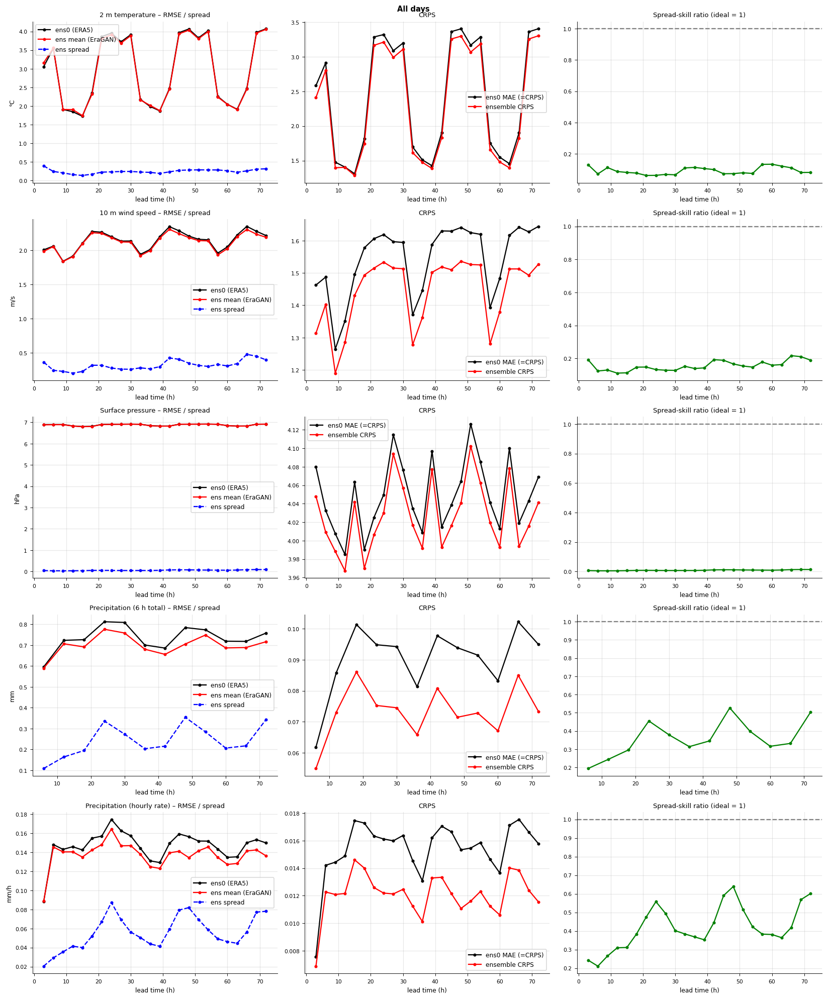

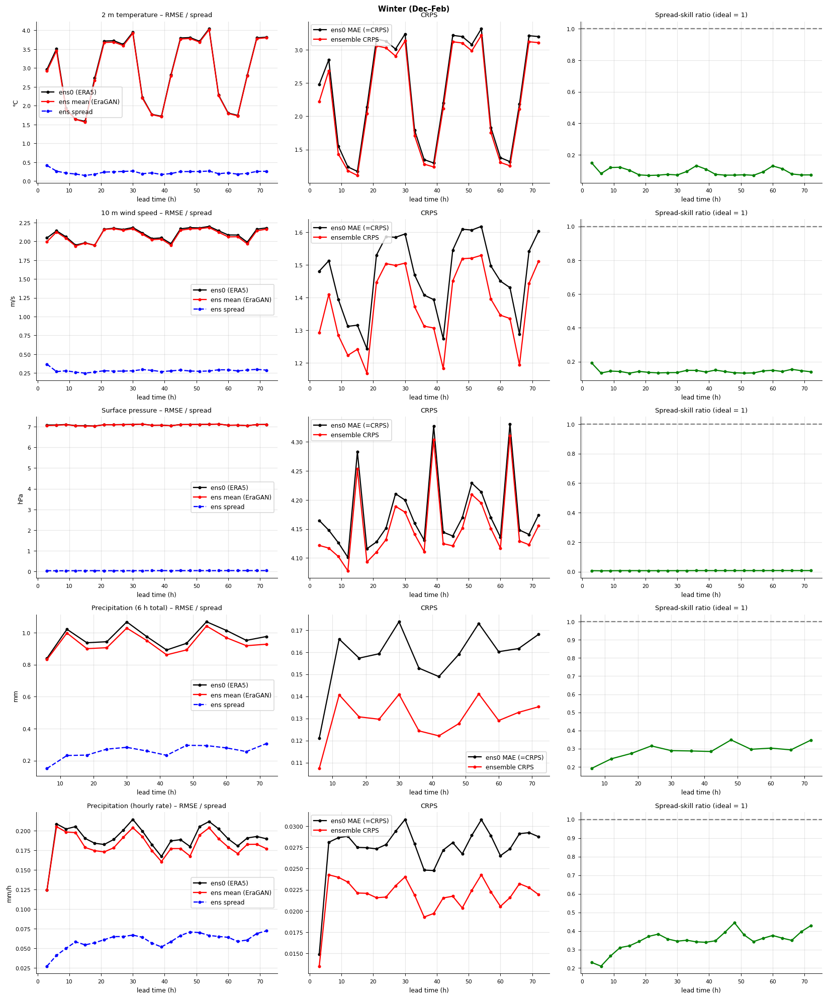

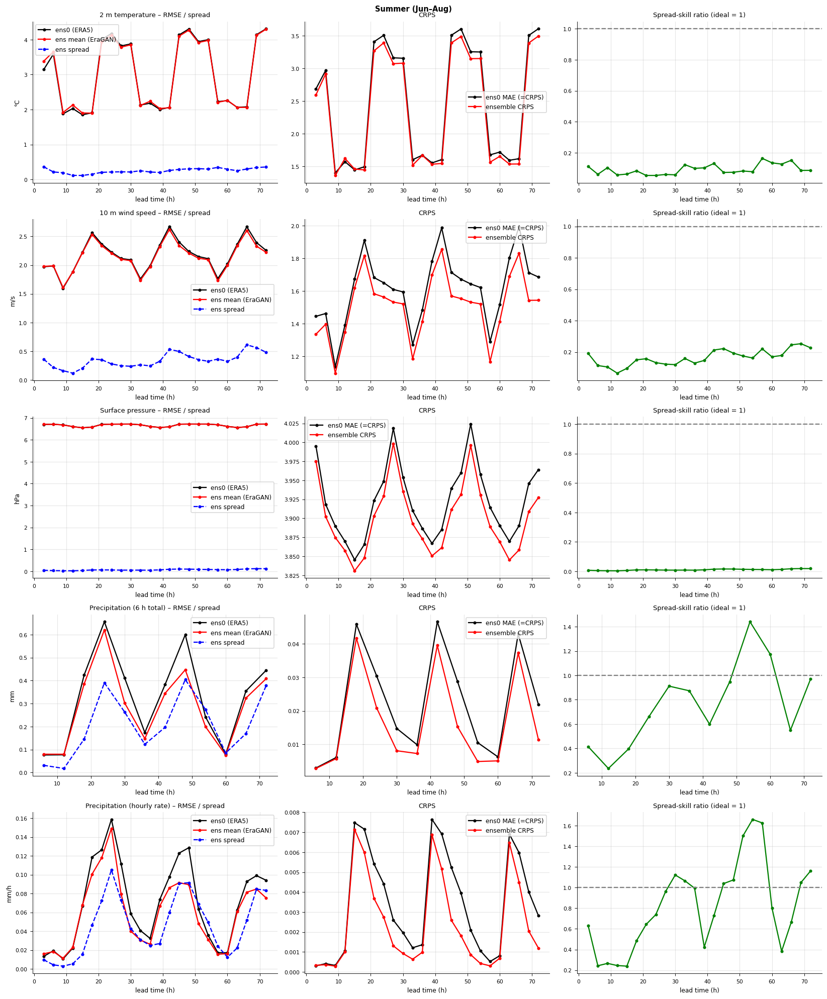

In [18]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    # Lead-time curves: error, spread, CRPS
    fig, axes = plt.subplots(len(VARS), 3, figsize=(15, 3.6 * len(VARS)), squeeze=False)
    for i, v in enumerate(VARS):
        t = LEADTAB.loc[v]
        ax = axes[i, 0]
        ax.plot(t.index, t.rmse_ctrl, "k-o", ms=3, label="ens0 (ERA5)")
        ax.plot(t.index, t.rmse_mean, "r-o", ms=3, label="ens mean (EraGAN)")
        ax.plot(t.index, t.spread, "b--o", ms=3, label="ens spread")
        ax.set_title(f"{VARS[v]['label']} – RMSE / spread"); ax.set_ylabel(VARS[v]["unit"]); ax.legend(fontsize=8)
        ax = axes[i, 1]
        ax.plot(t.index, t.mae_ctrl, "k-o", ms=3, label="ens0 MAE (=CRPS)")
        ax.plot(t.index, t.crps_ens, "r-o", ms=3, label="ensemble CRPS")
        ax.set_title("CRPS"); ax.legend(fontsize=8)
        ax = axes[i, 2]
        ax.plot(t.index, t.SSR, "g-o", ms=3); ax.axhline(1, color="gray", ls="--")
        ax.set_title("Spread-skill ratio (ideal = 1)")
        for a in axes[i]: a.set_xlabel("lead time (h)"); a.grid(alpha=.3)
    plt.tight_layout(); plt.gcf().suptitle(SLAB, y=1.0, fontweight="bold"); save_fig(plt.gcf(), "lead_time_scores" + SFX); plt.show()

In [19]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = ["### Analysis: lead-time scores", ""]
    for v in VARS:
        t = LEADTAB.loc[v]; u = VARS[v]["unit"]
        h0, h1 = t.index[0], t.index[-1]
        g0, g1 = t["RMSE_gain_%"].iloc[0], t["RMSE_gain_%"].iloc[-1]
        s0, s1 = t.spread.iloc[0], t.spread.iloc[-1]
        e0, e1 = t.rmse_mean.iloc[0], t.rmse_mean.iloc[-1]
        frac = (t.CRPSS_vs_ctrl > 0).mean()
        L.append(f"- **{VARS[v]['label']}**: the ensemble-mean RMSE differs from `ens0` by {g0:+.1f}% at +{h0:.0f} h and {g1:+.1f}% at +{h1:.0f} h (positive = ensemble better). The fair CRPSS is positive at {frac*100:.0f}% of lead times (mean {t.CRPSS_vs_ctrl.mean():+.3f}).")
        if s0 > 0 and e0 > 0:
            gs, ge = s1 / s0, e1 / e0
            if gs < 0.7 * ge: trend = "spread grows more slowly than the error, so under-dispersion worsens with lead time"
            elif gs > 1.3 * ge: trend = "spread grows faster than the error, so over-dispersion increases with lead time"
            else: trend = "spread and error grow at a similar rate"
            L.append(f"  - Spread goes from {s0:.2f} to {s1:.2f} {u} (x{gs:.1f}) while the ensemble-mean error goes from {e0:.2f} to {e1:.2f} {u} (x{ge:.1f}): {trend}. Mean SSR = {t.SSR.mean():.2f}, i.e. {disp_verdict(t.SSR.mean())}.")
        else:
            L.append(f"  - Spread at the first lead is ~0 (members start almost identical); mean SSR = {t.SSR.mean():.2f}, i.e. {disp_verdict(t.SSR.mean())}.")
        if t.crps_ens.iloc[-1] > t.mae_ctrl.iloc[-1]:
            L.append("  - At the longest lead the ensemble CRPS is worse than the control MAE: the benefit of the ensemble is lost late in the forecast.")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: lead-time scores — All days

- **2 m temperature**: the ensemble-mean RMSE differs from `ens0` by -3.4% at +3 h and +0.3% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.036).
  - Spread goes from 0.39 to 0.31 °C (x0.8) while the ensemble-mean error goes from 3.16 to 4.06 °C (x1.3): spread grows more slowly than the error, so under-dispersion worsens with lead time. Mean SSR = 0.09, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **10 m wind speed**: the ensemble-mean RMSE differs from `ens0` by +1.1% at +3 h and +1.1% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.064).
  - Spread goes from 0.36 to 0.40 m/s (x1.1) while the ensemble-mean error goes from 1.99 to 2.19 m/s (x1.1): spread and error grow at a similar rate. Mean SSR = 0.16, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Surface pressure**: the ensemble-mean RMSE differs from `ens0` by +0.2% at +3 h and +0.0% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.005).
  - Spread goes from 0.05 to 0.09 hPa (x2.0) while the ensemble-mean error goes from 6.88 to 6.91 hPa (x1.0): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.01, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Precipitation (6 h total)**: the ensemble-mean RMSE differs from `ens0` by +1.0% at +6 h and +5.5% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.185).
  - Spread goes from 0.11 to 0.34 mm (x3.2) while the ensemble-mean error goes from 0.59 to 0.72 mm (x1.2): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.36, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Precipitation (hourly rate)**: the ensemble-mean RMSE differs from `ens0` by -0.5% at +3 h and +9.1% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.213).
  - Spread goes from 0.02 to 0.08 mm/h (x3.8) while the ensemble-mean error goes from 0.09 to 0.14 mm/h (x1.5): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.42, i.e. **under-dispersive** (spread too small for the error: over-confident).

### Analysis: lead-time scores — Winter (Dec–Feb)

- **2 m temperature**: the ensemble-mean RMSE differs from `ens0` by +1.6% at +3 h and +0.4% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.044).
  - Spread goes from 0.42 to 0.26 °C (x0.6) while the ensemble-mean error goes from 2.92 to 3.80 °C (x1.3): spread grows more slowly than the error, so under-dispersion worsens with lead time. Mean SSR = 0.09, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **10 m wind speed**: the ensemble-mean RMSE differs from `ens0` by +2.5% at +3 h and +0.8% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.065).
  - Spread goes from 0.37 to 0.29 m/s (x0.8) while the ensemble-mean error goes from 2.00 to 2.16 m/s (x1.1): spread and error grow at a similar rate. Mean SSR = 0.14, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Surface pressure**: the ensemble-mean RMSE differs from `ens0` by +0.4% at +3 h and +0.0% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.005).
  - Spread goes from 0.04 to 0.05 hPa (x1.1) while the ensemble-mean error goes from 7.05 to 7.10 hPa (x1.0): spread and error grow at a similar rate. Mean SSR = 0.01, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Precipitation (6 h total)**: the ensemble-mean RMSE differs from `ens0` by +1.0% at +6 h and +4.9% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.177).
  - Spread goes from 0.15 to 0.31 mm (x2.0) while the ensemble-mean error goes from 0.83 to 0.93 mm (x1.1): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.29, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Precipitation (hourly rate)**: the ensemble-mean RMSE differs from `ens0` by -0.2% at +3 h and +6.6% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.205).
  - Spread goes from 0.03 to 0.07 mm/h (x2.6) while the ensemble-mean error goes from 0.12 to 0.18 mm/h (x1.4): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.35, i.e. **under-dispersive** (spread too small for the error: over-confident).

### Analysis: lead-time scores — Summer (Jun–Aug)

- **2 m temperature**: the ensemble-mean RMSE differs from `ens0` by -7.7% at +3 h and +0.3% at +72 h (positive = ensemble better). The fair CRPSS is positive at 92% of lead times (mean +0.029).
  - Spread goes from 0.36 to 0.36 °C (x1.0) while the ensemble-mean error goes from 3.38 to 4.30 °C (x1.3): spread and error grow at a similar rate. Mean SSR = 0.09, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **10 m wind speed**: the ensemble-mean RMSE differs from `ens0` by -0.3% at +3 h and +1.4% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.062).
  - Spread goes from 0.36 to 0.48 m/s (x1.3) while the ensemble-mean error goes from 1.98 to 2.22 m/s (x1.1): spread and error grow at a similar rate. Mean SSR = 0.16, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Surface pressure**: the ensemble-mean RMSE differs from `ens0` by -0.0% at +3 h and +0.0% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.006).
  - Spread goes from 0.05 to 0.12 hPa (x2.5) while the ensemble-mean error goes from 6.71 to 6.72 hPa (x1.0): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.01, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Precipitation (6 h total)**: the ensemble-mean RMSE differs from `ens0` by -4.5% at +6 h and +8.2% at +72 h (positive = ensemble better). The fair CRPSS is positive at 100% of lead times (mean +0.264).
  - Spread goes from 0.03 to 0.38 mm (x12.0) while the ensemble-mean error goes from 0.08 to 0.41 mm (x5.1): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.76, i.e. **under-dispersive** (spread too small for the error: over-confident).
- **Precipitation (hourly rate)**: the ensemble-mean RMSE differs from `ens0` by -20.9% at +3 h and +19.9% at +72 h (positive = ensemble better). The fair CRPSS is positive at 96% of lead times (mean +0.309).
  - Spread goes from 0.01 to 0.08 mm/h (x8.7) while the ensemble-mean error goes from 0.02 to 0.08 mm/h (x4.7): spread grows faster than the error, so over-dispersion increases with lead time. Mean SSR = 0.82, i.e. **under-dispersive** (spread too small for the error: over-confident).

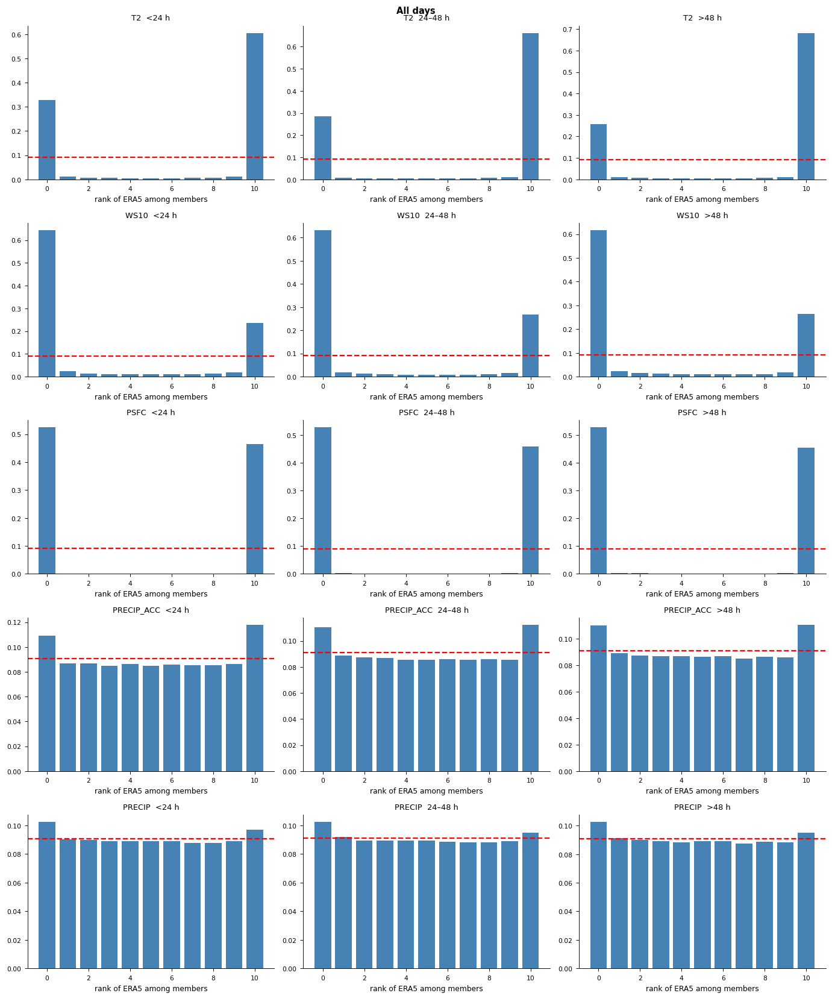

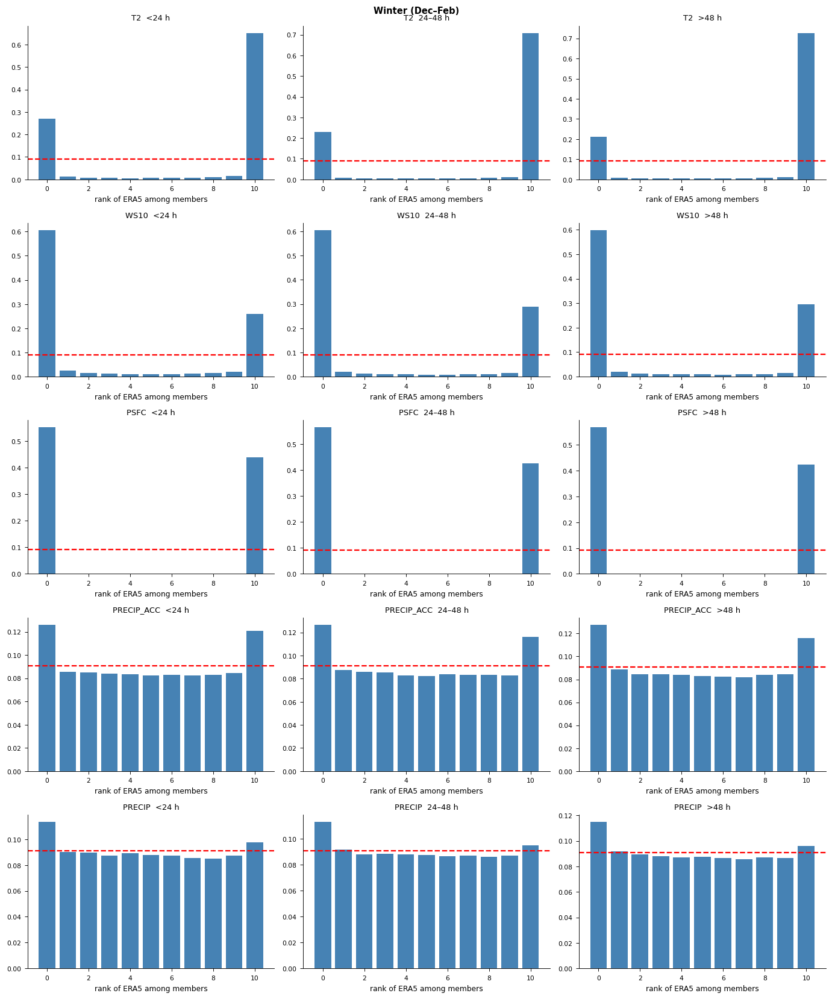

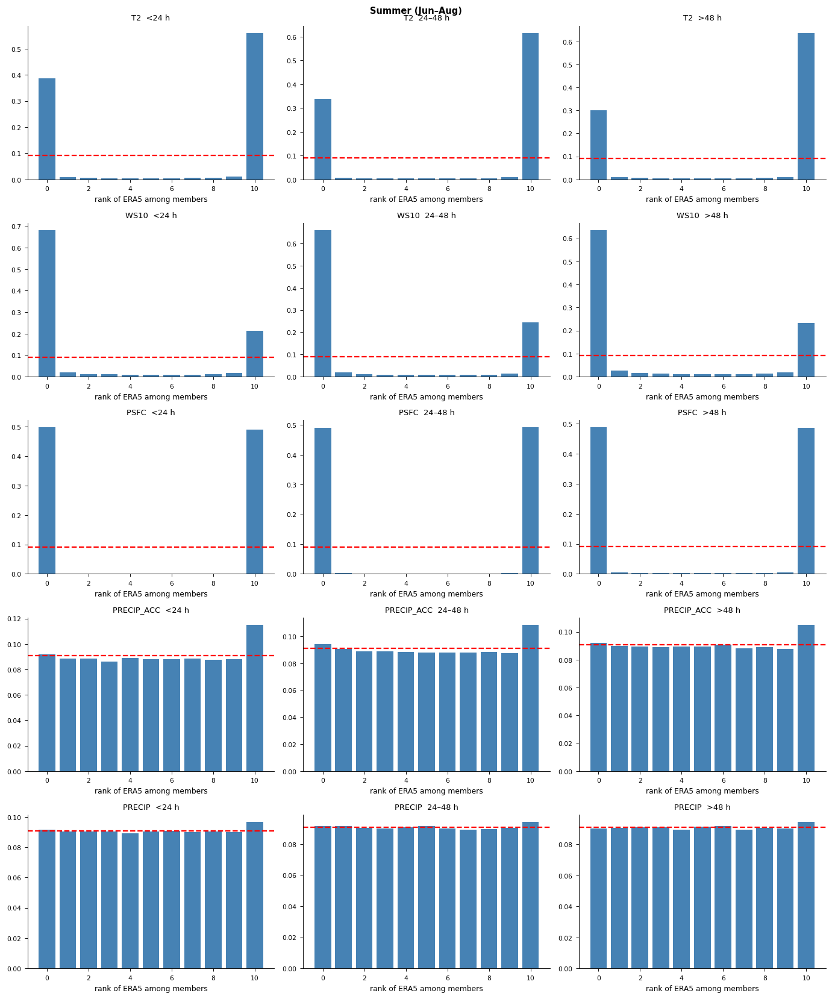

In [20]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    # Rank histograms (flat = reliable; U-shape = under-dispersive; dome = over-dispersive)
    fig, axes = plt.subplots(len(VARS), len(LEAD_BINS), figsize=(4.2 * len(LEAD_BINS), 3 * len(VARS)), squeeze=False)
    for i, v in enumerate(VARS):
        for k in range(len(LEAD_BINS)):
            c = rank_cnt[(v, k)]
            f = c / max(c.sum(), 1)
            axes[i, k].bar(range(N + 1), f, color="steelblue")
            axes[i, k].axhline(1 / (N + 1), color="r", ls="--")
            axes[i, k].set_title(f"{v}  {LEAD_LAB[k]}"); axes[i, k].set_xlabel("rank of ERA5 among members")
    plt.tight_layout(); plt.gcf().suptitle(SLAB, y=1.0, fontweight="bold"); save_fig(plt.gcf(), "rank_histograms" + SFX); plt.show()

In [21]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = ["### Analysis: rank histograms", "", "Rank = number of members below ERA5. Flat = reliable, U = under-dispersive, dome = over-dispersive, left-heavy = members too high, right-heavy = members too low.", ""]
    for v in VARS:
        for k in range(len(LEAD_BINS)):
            c = rank_cnt[(v, k)]
            if c.sum() == 0: continue
            f = c / c.sum()
            ratio = (f[0] + f[-1]) / (2 / (N + 1))
            skew = f[N // 2 + 1:].sum() - f[:N // 2].sum()
            shape = "U-shaped (under-dispersive)" if ratio > 1.4 else ("dome-shaped (over-dispersive)" if ratio < 0.7 else "approximately flat")
            if abs(skew) > 0.08:
                bias = "members systematically too low (ERA5 above most members)" if skew > 0 else "members systematically too high (ERA5 below most members)"
            else:
                bias = "no marked asymmetry"
            L.append(f"- **{v}, {LEAD_LAB[k]}**: {shape}; the two extreme ranks hold {100*(f[0]+f[-1]):.1f}% of cases ({ratio:.1f}x the {200/(N+1):.1f}% expected for a reliable ensemble); {bias} (asymmetry {skew:+.2f}).")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: rank histograms — All days

Rank = number of members below ERA5. Flat = reliable, U = under-dispersive, dome = over-dispersive, left-heavy = members too high, right-heavy = members too low.

- **T2, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 93.4% of cases (5.1x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.28).
- **T2, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 94.6% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.38).
- **T2, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 93.9% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.43).
- **WS10, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 87.9% of cases (4.8x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.42).
- **WS10, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 90.0% of cases (4.9x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.37).
- **WS10, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 88.1% of cases (4.8x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.36).
- **PSFC, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.9% of cases (5.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.06).
- **PSFC, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.7% of cases (5.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.07).
- **PSFC, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.2% of cases (5.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.07).
- **PRECIP_ACC, <24 h**: approximately flat; the two extreme ranks hold 22.7% of cases (1.2x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.01).
- **PRECIP_ACC, 24–48 h**: approximately flat; the two extreme ranks hold 22.3% of cases (1.2x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.00).
- **PRECIP_ACC, >48 h**: approximately flat; the two extreme ranks hold 22.0% of cases (1.2x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.01).
- **PRECIP, <24 h**: approximately flat; the two extreme ranks hold 20.0% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.01).
- **PRECIP, 24–48 h**: approximately flat; the two extreme ranks hold 19.7% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.01).
- **PRECIP, >48 h**: approximately flat; the two extreme ranks hold 19.8% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.01).

### Analysis: rank histograms — Winter (Dec–Feb)

Rank = number of members below ERA5. Flat = reliable, U = under-dispersive, dome = over-dispersive, left-heavy = members too high, right-heavy = members too low.

- **T2, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 92.3% of cases (5.1x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.39).
- **T2, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 93.8% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.48).
- **T2, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 93.9% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.52).
- **WS10, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 86.4% of cases (4.8x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.35).
- **WS10, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 89.3% of cases (4.9x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.32).
- **WS10, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 89.3% of cases (4.9x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.31).
- **PSFC, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.9% of cases (5.4x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.11).
- **PSFC, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 99.0% of cases (5.4x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.14).
- **PSFC, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.9% of cases (5.4x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.14).
- **PRECIP_ACC, <24 h**: approximately flat; the two extreme ranks hold 24.7% of cases (1.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.01).
- **PRECIP_ACC, 24–48 h**: approximately flat; the two extreme ranks hold 24.3% of cases (1.3x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.02).
- **PRECIP_ACC, >48 h**: approximately flat; the two extreme ranks hold 24.3% of cases (1.3x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.02).
- **PRECIP, <24 h**: approximately flat; the two extreme ranks hold 21.1% of cases (1.2x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.03).
- **PRECIP, 24–48 h**: approximately flat; the two extreme ranks hold 20.8% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.03).
- **PRECIP, >48 h**: approximately flat; the two extreme ranks hold 21.1% of cases (1.2x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.03).

### Analysis: rank histograms — Summer (Jun–Aug)

Rank = number of members below ERA5. Flat = reliable, U = under-dispersive, dome = over-dispersive, left-heavy = members too high, right-heavy = members too low.

- **T2, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 94.6% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.18).
- **T2, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 95.3% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.28).
- **T2, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 93.9% of cases (5.2x the 18.2% expected for a reliable ensemble); members systematically too low (ERA5 above most members) (asymmetry +0.34).
- **WS10, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 89.4% of cases (4.9x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.48).
- **WS10, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 90.6% of cases (5.0x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.42).
- **WS10, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 87.0% of cases (4.8x the 18.2% expected for a reliable ensemble); members systematically too high (ERA5 below most members) (asymmetry -0.42).
- **PSFC, <24 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.9% of cases (5.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.01).
- **PSFC, 24–48 h**: U-shaped (under-dispersive); the two extreme ranks hold 98.4% of cases (5.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.00).
- **PSFC, >48 h**: U-shaped (under-dispersive); the two extreme ranks hold 97.4% of cases (5.4x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.00).
- **PRECIP_ACC, <24 h**: approximately flat; the two extreme ranks hold 20.7% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.02).
- **PRECIP_ACC, 24–48 h**: approximately flat; the two extreme ranks hold 20.3% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.01).
- **PRECIP_ACC, >48 h**: approximately flat; the two extreme ranks hold 19.7% of cases (1.1x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.01).
- **PRECIP, <24 h**: approximately flat; the two extreme ranks hold 18.8% of cases (1.0x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.01).
- **PRECIP, 24–48 h**: approximately flat; the two extreme ranks hold 18.6% of cases (1.0x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry -0.00).
- **PRECIP, >48 h**: approximately flat; the two extreme ranks hold 18.5% of cases (1.0x the 18.2% expected for a reliable ensemble); no marked asymmetry (asymmetry +0.00).

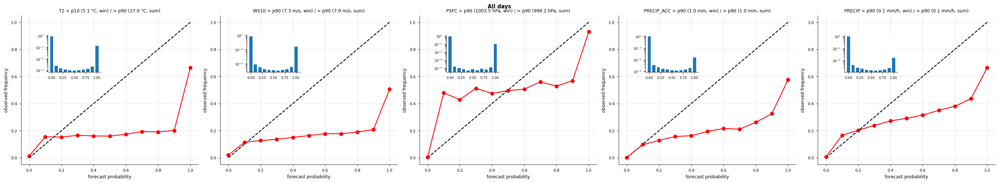

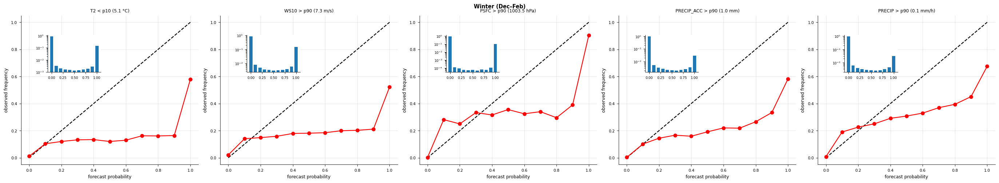

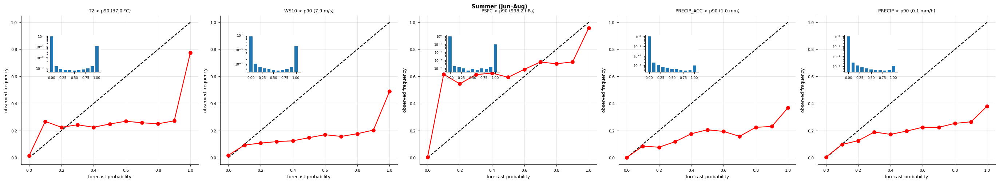

In [22]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    # Reliability diagrams for the p90 exceedance event
    fig, axes = plt.subplots(1, len(VARS), figsize=(5 * len(VARS), 4.5), squeeze=False)
    for i, v in enumerate(VARS):
        ax = axes[0, i]
        p = np.arange(N + 1) / N
        with np.errstate(invalid="ignore", divide="ignore"):
            freq = rel_o[v] / rel_n[v]
        ax.plot([0, 1], [0, 1], "k--"); ax.plot(p, freq, "r-o")
        ax.set_title(f"{v} {EVLAB(v, SEAS)}", fontsize=8)
        ax.set_xlabel("forecast probability"); ax.set_ylabel("observed frequency"); ax.grid(alpha=.3)
        ins = ax.inset_axes([0.15, 0.62, 0.3, 0.25]); ins.bar(p, rel_n[v] / rel_n[v].sum(), width=0.07); ins.set_yscale("log")
        ins.tick_params(labelsize=6)
    plt.tight_layout(); plt.gcf().suptitle(SLAB, y=1.0, fontweight="bold"); save_fig(plt.gcf(), "reliability" + SFX); plt.show()

In [23]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = ["### Analysis: reliability (event = season-specific ERA5 tail: above p%d, below p%d for winter T2)" % (PCTL, 100 - PCTL), ""]
    for v in VARS:
        n = rel_n[v]; o = rel_o[v]; p = np.arange(N + 1) / N
        if n.sum() == 0: continue
        freq = np.divide(o, n, out=np.full_like(o, np.nan), where=n > 0)
        ok = n >= 30
        slope = np.polyfit(p[ok], freq[ok], 1, w=np.sqrt(n[ok]))[0] if ok.sum() >= 3 else np.nan
        pm, of = (n * p).sum() / n.sum(), o.sum() / n.sum()
        sharp = (n[0] + n[-1]) / n.sum()
        if np.isnan(slope): rl = "too few populated probability bins to judge"
        elif slope < 0.8: rl = f"slope {slope:.2f} < 1: **over-confident** (high probabilities verify less often than forecast)"
        elif slope > 1.2: rl = f"slope {slope:.2f} > 1: **under-confident**"
        else: rl = f"slope {slope:.2f}: **reasonably reliable**"
        if pm > 1.15 * of: fb = f"the event is over-forecast (mean probability {pm:.3f} vs observed frequency {of:.3f})"
        elif pm < 0.85 * of: fb = f"the event is under-forecast (mean probability {pm:.3f} vs observed frequency {of:.3f})"
        else: fb = f"event frequency is well captured (forecast {pm:.3f} vs observed {of:.3f})"
        sm = SUMMARY.loc[v]
        better = "the ensemble beats the control" if sm.BSS_ens > sm.BSS_ctrl else "the control is better than the ensemble"
        L.append(f"- **{v}**: {rl}; {fb}. {100*sharp:.0f}% of forecasts are at probability 0 or 1 (sharpness). BSS = {sm.BSS_ens:+.2f} (ensemble) vs {sm.BSS_ctrl:+.2f} (ens0): {better} for extremes.")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: reliability (event = season-specific ERA5 tail: above p90, below p10 for winter T2) — All days

- **T2**: slope 0.64 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.137 vs observed frequency 0.101). 99% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.35 (ensemble) vs +0.32 (ens0): the ensemble beats the control for extremes.
- **WS10**: slope 0.47 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.175 vs observed frequency 0.101). 96% of forecasts are at probability 0 or 1 (sharpness). BSS = -0.15 (ensemble) vs -0.22 (ens0): the ensemble beats the control for extremes.
- **PSFC**: slope 0.93: **reasonably reliable**; event frequency is well captured (forecast 0.104 vs observed 0.100). 100% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.86 (ensemble) vs +0.86 (ens0): the ensemble beats the control for extremes.
- **PRECIP_ACC**: slope 0.53 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.022 vs observed frequency 0.014). 98% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.08 (ensemble) vs -0.10 (ens0): the ensemble beats the control for extremes.
- **PRECIP**: slope 0.63 < 1: **over-confident** (high probabilities verify less often than forecast); event frequency is well captured (forecast 0.025 vs observed 0.022). 98% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.24 (ensemble) vs +0.09 (ens0): the ensemble beats the control for extremes.

### Analysis: reliability (event = season-specific ERA5 tail: above p90, below p10 for winter T2) — Winter (Dec–Feb)

- **T2**: slope 0.56 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.156 vs observed frequency 0.097). 98% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.12 (ensemble) vs +0.06 (ens0): the ensemble beats the control for extremes.
- **WS10**: slope 0.48 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.166 vs observed frequency 0.101). 96% of forecasts are at probability 0 or 1 (sharpness). BSS = -0.10 (ensemble) vs -0.17 (ens0): the ensemble beats the control for extremes.
- **PSFC**: slope 0.90: **reasonably reliable**; event frequency is well captured (forecast 0.108 vs observed 0.100). 100% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.86 (ensemble) vs +0.85 (ens0): the ensemble beats the control for extremes.
- **PRECIP_ACC**: slope 0.54 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.042 vs observed frequency 0.025). 97% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.11 (ensemble) vs -0.07 (ens0): the ensemble beats the control for extremes.
- **PRECIP**: slope 0.64 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.046 vs observed frequency 0.038). 97% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.29 (ensemble) vs +0.14 (ens0): the ensemble beats the control for extremes.

### Analysis: reliability (event = season-specific ERA5 tail: above p90, below p10 for winter T2) — Summer (Jun–Aug)

- **T2**: slope 0.75 < 1: **over-confident** (high probabilities verify less often than forecast); event frequency is well captured (forecast 0.119 vs observed 0.105). 99% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.56 (ensemble) vs +0.55 (ens0): the ensemble beats the control for extremes.
- **WS10**: slope 0.46 < 1: **over-confident** (high probabilities verify less often than forecast); the event is over-forecast (mean probability 0.184 vs observed frequency 0.101). 95% of forecasts are at probability 0 or 1 (sharpness). BSS = -0.19 (ensemble) vs -0.27 (ens0): the ensemble beats the control for extremes.
- **PSFC**: slope 0.95: **reasonably reliable**; event frequency is well captured (forecast 0.100 vs observed 0.100). 100% of forecasts are at probability 0 or 1 (sharpness). BSS = +0.86 (ensemble) vs +0.86 (ens0): the ensemble beats the control for extremes.
- **PRECIP_ACC**: slope 0.34 < 1: **over-confident** (high probabilities verify less often than forecast); event frequency is well captured (forecast 0.003 vs observed 0.003). 99% of forecasts are at probability 0 or 1 (sharpness). BSS = -0.21 (ensemble) vs -0.49 (ens0): the ensemble beats the control for extremes.
- **PRECIP**: slope 0.37 < 1: **over-confident** (high probabilities verify less often than forecast); the event is under-forecast (mean probability 0.003 vs observed frequency 0.006). 99% of forecasts are at probability 0 or 1 (sharpness). BSS = -0.11 (ensemble) vs -0.28 (ens0): the ensemble beats the control for extremes.

### Categorical scores: POD, FAR, CSI
Hits / misses / false alarms for the season-specific tail event (*above the seasonal ERA5 p90*; *below the seasonal p10* for winter 2 m temperature), on Morocco land points. Three yes/no forecasts are scored: the control `ens0`, the ensemble mean, and the **majority vote** of the members (at least half exceed the threshold). Top row: bars; middle row: CSI against lead time; bottom row: performance diagram (top-right = best; dashed lines = frequency bias 0.5, 1, 2; grey curves = CSI).

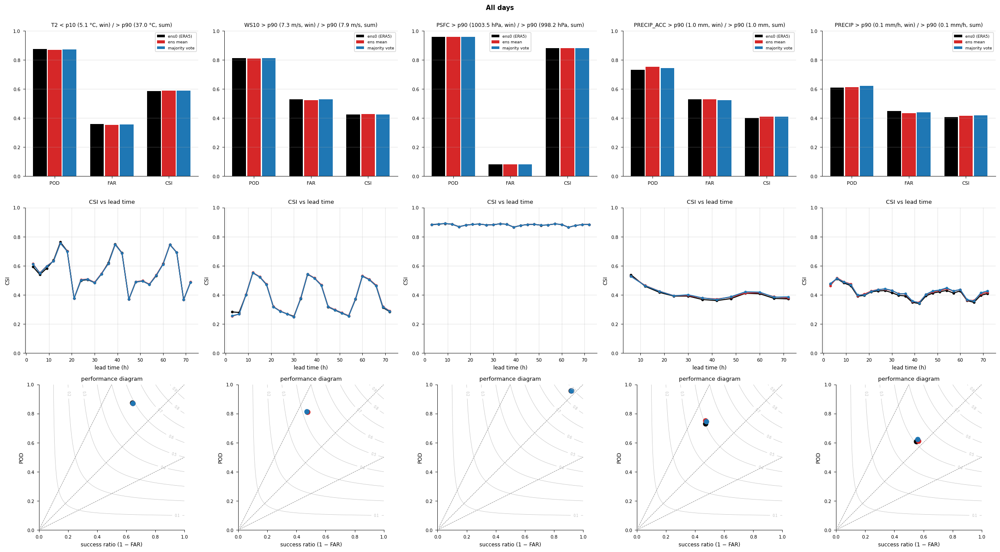

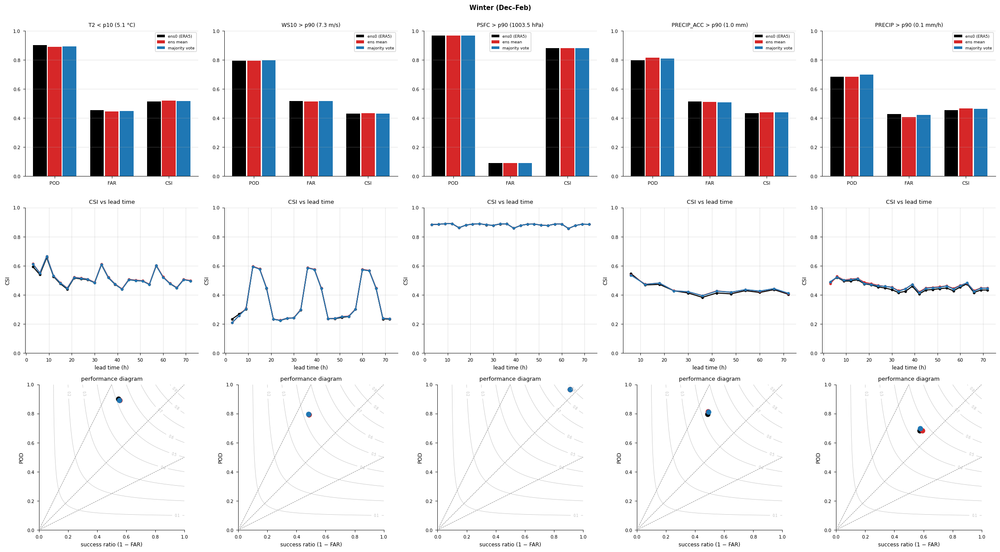

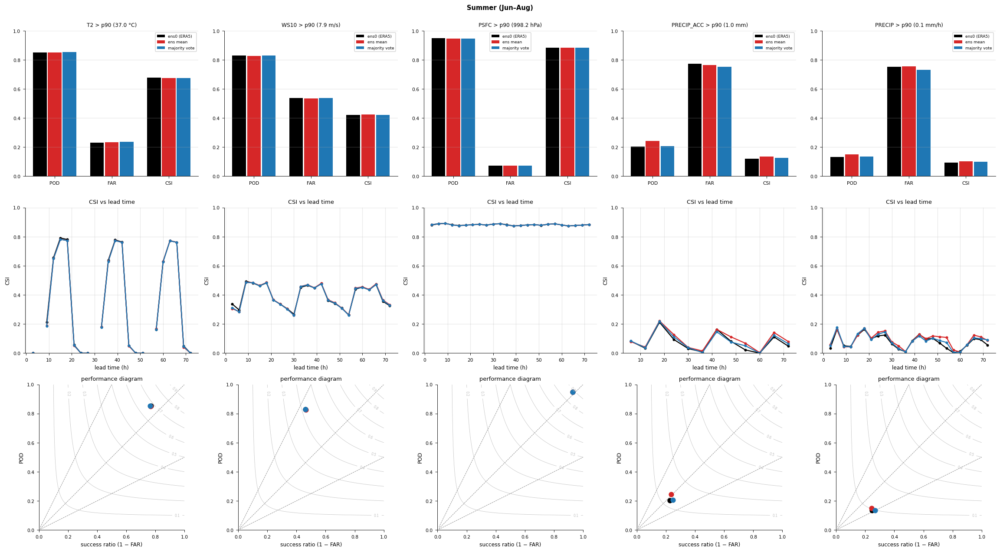

In [24]:
CAT_COL = {"ctrl": "k", "mean": "tab:red", "maj": "tab:blue"}
CAT_NAME = {"ctrl": "ens0 (ERA5)", "mean": "ens mean", "maj": "majority vote"}
def perf_axes(ax):
    x = np.linspace(0.01, 1, 100); X, Y = np.meshgrid(x, x)
    cs = ax.contour(X, Y, 1 / (1 / X + 1 / Y - 1), levels=np.arange(0.1, 1, 0.1), colors="0.75", linewidths=0.5)
    ax.clabel(cs, fmt="%.1f", fontsize=5)
    for b in (0.5, 1, 2): ax.plot(x, np.minimum(b * x, 1), "--", color="0.5", lw=0.6)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("success ratio (1 − FAR)"); ax.set_ylabel("POD")

for SEAS in SEAS_LIST:
    use_season(SEAS)
    fig, axes = plt.subplots(3, len(VARS), figsize=(4.2 * len(VARS), 11.5), squeeze=False)
    for i, v in enumerate(VARS):
        t = SUMMARY.loc[v]
        ax = axes[0, i]
        for q, (sc) in enumerate(["POD", "FAR", "CSI"]):
            for kq, k in enumerate(["ctrl", "mean", "maj"]):
                ax.bar(q + (kq - 1) * 0.26, t[f"{sc}_{k}"], 0.24, color=CAT_COL[k], label=CAT_NAME[k] if q == 0 else None)
        ax.set_xticks(range(3)); ax.set_xticklabels(["POD", "FAR", "CSI"]); ax.set_ylim(0, 1)
        ax.set_title(f"{v} {EVLAB(v, SEAS)}", fontsize=8); ax.legend(fontsize=6); ax.grid(alpha=.3, axis="y")
        ax = axes[1, i]; tl = LEADTAB.loc[v]
        for k in ["ctrl", "mean", "maj"]:
            ax.plot(tl.index, tl[f"CSI_{k}"], "-o", ms=3, color=CAT_COL[k], label=CAT_NAME[k])
        ax.set_xlabel("lead time (h)"); ax.set_ylabel("CSI"); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.set_title("CSI vs lead time")
        ax = axes[2, i]; perf_axes(ax)
        for k in ["ctrl", "mean", "maj"]:
            ax.plot(1 - t[f"FAR_{k}"], t[f"POD_{k}"], "o", ms=7, color=CAT_COL[k], label=CAT_NAME[k])
        ax.set_title("performance diagram")
    fig.suptitle(SLAB, fontweight="bold", y=1.0); plt.tight_layout(); save_fig(fig, "categorical_scores" + SFX); plt.show()


In [25]:
NAMES = {"ctrl": "`ens0`", "mean": "ensemble mean", "maj": "majority vote"}
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = [f"### Analysis: POD / FAR / CSI — {SLAB}", "",
         f"Event = value beyond the season-specific ERA5 threshold (above p{PCTL}; below p{100 - PCTL} for winter 2 m temperature). POD = hits/(hits+misses), FAR = false alarms/(hits+false alarms), CSI = hits/(hits+misses+false alarms), FBI = forecast events / observed events.", ""]
    for v in VARS:
        t = SUMMARY.loc[v]
        parts = "; ".join(f"{NAMES[k]}: POD {t[f'POD_{k}']:.2f}, FAR {t[f'FAR_{k}']:.2f}, CSI {t[f'CSI_{k}']:.2f}, FBI {t[f'FBI_{k}']:.2f}" for k in ("ctrl", "mean", "maj"))
        csi = {k: t[f"CSI_{k}"] for k in ("ctrl", "mean", "maj") if np.isfinite(t[f"CSI_{k}"])}
        best = max(csi, key=csi.get) if csi else None
        fb = t["FBI_maj"]
        fbs = ("the ensemble **under-forecasts** the event" if fb < 0.8 else "the ensemble **over-forecasts** the event" if fb > 1.25 else "the event frequency is about right") if np.isfinite(fb) else "no event forecast"
        warn = f" Only {int(t.n_events)} observed event points: interpret with care." if t.n_events < 30 else ""
        L.append(f"- **{VARS[v]['label']}** (event {EVLAB(v, SEAS)}): {parts}. " +
                 (f"Best CSI: {NAMES[best]} ({csi[best]:.2f}); majority-vote FBI {fb:.2f}: {fbs}." if best else "No event detected by any forecast.") + warn)
    show(L)


### Analysis: POD / FAR / CSI — All days

Event = value beyond the season-specific ERA5 threshold (above p90; below p10 for winter 2 m temperature). POD = hits/(hits+misses), FAR = false alarms/(hits+false alarms), CSI = hits/(hits+misses+false alarms), FBI = forecast events / observed events.

- **2 m temperature** (event < p10 (5.1 °C, win) / > p90 (37.0 °C, sum)): `ens0`: POD 0.87, FAR 0.36, CSI 0.59, FBI 1.37; ensemble mean: POD 0.87, FAR 0.35, CSI 0.59, FBI 1.35; majority vote: POD 0.87, FAR 0.36, CSI 0.59, FBI 1.35. Best CSI: ensemble mean (0.59); majority-vote FBI 1.35: the ensemble **over-forecasts** the event.
- **10 m wind speed** (event > p90 (7.3 m/s, win) / > p90 (7.9 m/s, sum)): `ens0`: POD 0.81, FAR 0.53, CSI 0.43, FBI 1.72; ensemble mean: POD 0.81, FAR 0.52, CSI 0.43, FBI 1.70; majority vote: POD 0.81, FAR 0.53, CSI 0.43, FBI 1.72. Best CSI: ensemble mean (0.43); majority-vote FBI 1.72: the ensemble **over-forecasts** the event.
- **Surface pressure** (event > p90 (1003.5 hPa, win) / > p90 (998.2 hPa, sum)): `ens0`: POD 0.96, FAR 0.08, CSI 0.88, FBI 1.04; ensemble mean: POD 0.96, FAR 0.08, CSI 0.88, FBI 1.04; majority vote: POD 0.96, FAR 0.08, CSI 0.88, FBI 1.04. Best CSI: ensemble mean (0.88); majority-vote FBI 1.04: the event frequency is about right.
- **Precipitation (6 h total)** (event > p90 (1.0 mm, win) / > p90 (1.0 mm, sum)): `ens0`: POD 0.73, FAR 0.53, CSI 0.40, FBI 1.55; ensemble mean: POD 0.75, FAR 0.53, CSI 0.41, FBI 1.59; majority vote: POD 0.74, FAR 0.52, CSI 0.41, FBI 1.56. Best CSI: majority vote (0.41); majority-vote FBI 1.56: the ensemble **over-forecasts** the event.
- **Precipitation (hourly rate)** (event > p90 (0.1 mm/h, win) / > p90 (0.1 mm/h, sum)): `ens0`: POD 0.61, FAR 0.45, CSI 0.41, FBI 1.10; ensemble mean: POD 0.61, FAR 0.43, CSI 0.42, FBI 1.08; majority vote: POD 0.62, FAR 0.44, CSI 0.42, FBI 1.11. Best CSI: majority vote (0.42); majority-vote FBI 1.11: the event frequency is about right.

### Analysis: POD / FAR / CSI — Winter (Dec–Feb)

Event = value beyond the season-specific ERA5 threshold (above p90; below p10 for winter 2 m temperature). POD = hits/(hits+misses), FAR = false alarms/(hits+false alarms), CSI = hits/(hits+misses+false alarms), FBI = forecast events / observed events.

- **2 m temperature** (event < p10 (5.1 °C)): `ens0`: POD 0.90, FAR 0.45, CSI 0.51, FBI 1.65; ensemble mean: POD 0.89, FAR 0.45, CSI 0.52, FBI 1.61; majority vote: POD 0.89, FAR 0.45, CSI 0.52, FBI 1.61. Best CSI: ensemble mean (0.52); majority-vote FBI 1.61: the ensemble **over-forecasts** the event.
- **10 m wind speed** (event > p90 (7.3 m/s)): `ens0`: POD 0.79, FAR 0.52, CSI 0.43, FBI 1.64; ensemble mean: POD 0.79, FAR 0.51, CSI 0.43, FBI 1.63; majority vote: POD 0.80, FAR 0.52, CSI 0.43, FBI 1.65. Best CSI: ensemble mean (0.43); majority-vote FBI 1.65: the ensemble **over-forecasts** the event.
- **Surface pressure** (event > p90 (1003.5 hPa)): `ens0`: POD 0.97, FAR 0.09, CSI 0.88, FBI 1.06; ensemble mean: POD 0.97, FAR 0.09, CSI 0.88, FBI 1.06; majority vote: POD 0.97, FAR 0.09, CSI 0.88, FBI 1.06. Best CSI: ensemble mean (0.88); majority-vote FBI 1.06: the event frequency is about right.
- **Precipitation (6 h total)** (event > p90 (1.0 mm)): `ens0`: POD 0.80, FAR 0.51, CSI 0.43, FBI 1.63; ensemble mean: POD 0.81, FAR 0.51, CSI 0.44, FBI 1.66; majority vote: POD 0.81, FAR 0.51, CSI 0.44, FBI 1.65. Best CSI: ensemble mean (0.44); majority-vote FBI 1.65: the ensemble **over-forecasts** the event.
- **Precipitation (hourly rate)** (event > p90 (0.1 mm/h)): `ens0`: POD 0.68, FAR 0.43, CSI 0.45, FBI 1.19; ensemble mean: POD 0.68, FAR 0.41, CSI 0.46, FBI 1.15; majority vote: POD 0.70, FAR 0.42, CSI 0.46, FBI 1.21. Best CSI: ensemble mean (0.46); majority-vote FBI 1.21: the event frequency is about right.

### Analysis: POD / FAR / CSI — Summer (Jun–Aug)

Event = value beyond the season-specific ERA5 threshold (above p90; below p10 for winter 2 m temperature). POD = hits/(hits+misses), FAR = false alarms/(hits+false alarms), CSI = hits/(hits+misses+false alarms), FBI = forecast events / observed events.

- **2 m temperature** (event > p90 (37.0 °C)): `ens0`: POD 0.85, FAR 0.23, CSI 0.68, FBI 1.11; ensemble mean: POD 0.85, FAR 0.23, CSI 0.68, FBI 1.11; majority vote: POD 0.85, FAR 0.24, CSI 0.67, FBI 1.11. Best CSI: `ens0` (0.68); majority-vote FBI 1.11: the event frequency is about right.
- **10 m wind speed** (event > p90 (7.9 m/s)): `ens0`: POD 0.83, FAR 0.54, CSI 0.42, FBI 1.80; ensemble mean: POD 0.83, FAR 0.53, CSI 0.42, FBI 1.77; majority vote: POD 0.83, FAR 0.54, CSI 0.42, FBI 1.79. Best CSI: ensemble mean (0.42); majority-vote FBI 1.79: the ensemble **over-forecasts** the event.
- **Surface pressure** (event > p90 (998.2 hPa)): `ens0`: POD 0.95, FAR 0.07, CSI 0.88, FBI 1.02; ensemble mean: POD 0.95, FAR 0.07, CSI 0.88, FBI 1.02; majority vote: POD 0.95, FAR 0.07, CSI 0.88, FBI 1.02. Best CSI: majority vote (0.88); majority-vote FBI 1.02: the event frequency is about right.
- **Precipitation (6 h total)** (event > p90 (1.0 mm)): `ens0`: POD 0.20, FAR 0.77, CSI 0.12, FBI 0.90; ensemble mean: POD 0.24, FAR 0.76, CSI 0.14, FBI 1.03; majority vote: POD 0.21, FAR 0.75, CSI 0.13, FBI 0.84. Best CSI: ensemble mean (0.14); majority-vote FBI 0.84: the event frequency is about right.
- **Precipitation (hourly rate)** (event > p90 (0.1 mm/h)): `ens0`: POD 0.13, FAR 0.75, CSI 0.09, FBI 0.54; ensemble mean: POD 0.15, FAR 0.76, CSI 0.10, FBI 0.62; majority vote: POD 0.14, FAR 0.73, CSI 0.10, FBI 0.50. Best CSI: ensemble mean (0.10); majority-vote FBI 0.50: the ensemble **under-forecasts** the event.

### Full contingency-table scores (season-specific tail event, ERA5 truth)

Beyond POD / FAR / CSI, the full set of scores is computed from the same four counts, **summed over days, leads and land points, then the ratios are formed**. Each grid point / time is classified by comparing the forecast event with the ERA5 event (the event = value beyond the seasonal tail threshold: above p90, or below p10 for winter 2 m temperature):

| | ERA5: event | ERA5: no event |
|---|---|---|
| **Forecast: event** | **H** hits | **FA** false alarms |
| **Forecast: no event** | **M** misses | **CN** correct negatives |

n = H + M + FA + CN. Three yes/no forecasts are scored: the control `ens0`, the ensemble mean, and the majority vote (at least half of the members).

| Score | Formula | Range | Perfect | No skill | Plain-language reading |
|---|---|---|---|---|---|
| `accuracy` | (H + CN) / n | 0 to 1 | 1 | — | Fraction of all points classified correctly. **Misleading for rare events**: always forecasting "no event" already scores close to 1. |
| `FBI` | (H + FA) / (H + M) | 0 to ∞ | 1 | — | Frequency bias: forecast events / observed events. **< 1** the event is under-forecast, **> 1** over-forecast. It says nothing about whether the events are in the right place. |
| `POD` | H / (H + M) | 0 to 1 | 1 | — | Share of observed events that were forecast (hit rate). |
| `POFD` | FA / (FA + CN) | 0 to 1 | 0 | = POD | Share of non-events that were wrongly forecast as events (false alarm rate). |
| `FAR` | FA / (H + FA) | 0 to 1 | 0 | — | Share of forecast events that did not occur. |
| `SR` | H / (H + FA) = 1 − FAR | 0 to 1 | 1 | — | Success ratio: share of forecast events that were correct. |
| `CSI` | H / (H + M + FA) | 0 to 1 | 1 | — | Hits among all events that were forecast or observed; ignores CN. It is lower for rare events, so compare it only between forecasts for the same event. |
| `ETS` | (H − H_rand) / (H + M + FA − H_rand), H_rand = (H+M)(H+FA)/n | −1/3 to 1 | 1 | 0 | CSI corrected for hits expected by chance (equitable threat score). |
| `HK` | POD − POFD (Hanssen–Kuipers) | −1 to 1 | 1 | 0 | How well the forecast separates events from non-events: hit rate minus false alarm rate. Not affected by event frequency. |
| `HSS` | 2(H·CN − FA·M) / [(H+FA)(FA+CN) + (H+M)(M+CN)] (Heidke) | −1 to 1 | 1 | 0 | Overall improvement in correct classifications over a random forecast with the same frequencies. |
| `ORSS` | (H·CN − M·FA) / (H·CN + M·FA) (odds-ratio skill score) | −1 to 1 | 1 | 0 | Association between forecast and observed events; strongly depends on both diagonal counts and is easy to push toward 1. |
| `odds_ratio` | (H·CN) / (M·FA) | 0 to ∞ | ∞ | 1 | How many times larger the odds of an event are when it is forecast than when it is not. **< 1** means the forecast is worse than random. |

**How to read them**
- Check **FBI** first: it tells you whether the forecast produces about the right number of events. A forecast with FBI far from 1 is biased in event frequency, and POD / FAR / CSI will reflect that.
- `ETS`, `HK`, `HSS` and `ORSS` correct for hits that would occur by chance, so they are the fair way to compare `ens0`, the ensemble mean and the majority vote when the event is rare (precipitation, and the extreme tails of temperature).
- `accuracy` and `POFD` look very good for rare events almost by construction (CN is huge), so do not use them alone.
- For skill-type scores (`ETS`, `HK`, `HSS`, `ORSS`), **> 0 is better than chance, 0 is no skill, < 0 is worse than chance**. The values of the different scores are not directly comparable with each other.
- Always check the number of observed events (`hits + misses`): with few events, the scores are noisy.

In [26]:
# Full contingency-table scores for the p90 event (verified against ERA5) -----------------------------------------
def cont_scores(h, m, f, c):
    """h hits, m misses, f false alarms, c correct negatives -> dict of all contingency-table scores."""
    h, m, f, c = (float(x) for x in (h, m, f, c)); n = h + m + f + c
    d = lambda a, b: a / b if b > 0 else np.nan
    pod, pofd = d(h, h + m), d(f, f + c)
    h_rand = (h + m) * (h + f) / n if n > 0 else np.nan
    return dict(n=n, hits=h, misses=m, false_alarms=f, correct_neg=c,
                accuracy=d(h + c, n), FBI=d(h + f, h + m), POD=pod, FAR=d(f, h + f), POFD=pofd, SR=d(h, h + f),
                CSI=d(h, h + m + f), ETS=d(h - h_rand, h + m + f - h_rand), HK=pod - pofd,
                HSS=d(2 * (h * c - f * m), (h + f) * (f + c) + (h + m) * (m + c)),
                ORSS=d(h * c - m * f, h * c + m * f), odds_ratio=d(h * c, m * f))

KEY = {"ctrl": "c", "mean": "m", "maj": "p"}                 # forecast -> suffix of the count columns of R
assert "cn_c" in R.columns, "R has no correct-negative counts: re-run the metrics cell above (it now stores cn_*)"

def cont_block(g):
    return pd.DataFrame({k: cont_scores(g[f"hit_{s}"].sum(), g[f"mis_{s}"].sum(), g[f"fa_{s}"].sum(), g[f"cn_{s}"].sum())
                         for k, s in KEY.items()}).T

CONT, CONT_LEAD = {}, {}
for s in SEAS_LIST:
    g_ = R if s == "all" else R[R.season == s]
    CONT[s] = pd.concat({v: cont_block(g_[g_["var"] == v]) for v in VARS if (g_["var"] == v).any()}, names=["var", "forecast"])
    gl = g_.assign(lead_bin=[LEAD_LAB[lead_bin(h)] for h in g_["lead"]])
    CONT_LEAD[s] = pd.concat({(v, lb): cont_block(gl[(gl["var"] == v) & (gl.lead_bin == lb)])
                              for v in VARS for lb in LEAD_LAB if ((gl["var"] == v) & (gl.lead_bin == lb)).any()},
                             names=["var", "lead_bin", "forecast"])
    CONT[s].to_csv(OUT / f"contingency_full{'' if s == 'all' else '_' + s}.csv")
    CONT_LEAD[s].to_csv(OUT / f"contingency_full_by_lead{'' if s == 'all' else '_' + s}.csv")
CONT_ALL = pd.concat(CONT, names=["period"])
CONT_ALL[["n", "hits", "misses", "false_alarms", "correct_neg", "accuracy", "FBI", "POD", "FAR", "POFD", "SR", "CSI",
          "ETS", "HK", "HSS", "ORSS", "odds_ratio"]].round(3)

n       hits    misses  false_alarms  \
period var        forecast                                                  
all    T2         ctrl      13962431.0  1212886.0  174196.0      680707.0   
                  mean      13962431.0  1206241.0  180841.0      661835.0   
                  maj       13962431.0  1207347.0  179735.0      669073.0   
       WS10       ctrl      13962431.0  1177292.0  274441.0     1314477.0   
                  mean      13962431.0  1175720.0  276013.0     1294878.0   
                  maj       13962431.0  1179603.0  272130.0     1319692.0   
       PSFC       ctrl      13962431.0  1402424.0   63068.0      125752.0   
                  mean      13962431.0  1401460.0   64032.0      124353.0   
                  maj       13962431.0  1401672.0   63820.0      124634.0   
       PRECIP_ACC ctrl       6976868.0    72873.0   26701.0       81735.0   
                  mean       6976868.0    74851.0   24723.0       83785.0   
                  maj        6976868.0    74123.0   25451.0       81298.0   
       PRECIP     ctrl      13957214.0   187974.0  120381.0      152573.0   
                  mean      13957214.0   188554.0  119801.0      144757.0   
                  maj       13957214.0   191830.0  116525.0      151092.0   
winter T2         ctrl       6969912.0   595383.0   66265.0      495930.0   
                  mean       6969912.0   588924.0   72724.0      473610.0   
                  maj        6969912.0   589320.0   72328.0      478664.0   
       WS10       ctrl       6969912.0   573575.0  150089.0      610797.0   
                  mean       6969912.0   573850.0  149814.0      604976.0   
                  maj        6969912.0   575806.0  147858.0      616684.0   
       PSFC       ctrl       6969912.0   720574.0   25251.0       72203.0   
                  mean       6969912.0   720343.0   25482.0       71600.0   
                  maj        6969912.0   720408.0   25417.0       71752.0   
       PRECIP_ACC ctrl       3484956.0    70680.0   18152.0       74284.0   
                  mean       3484956.0    72236.0   16596.0       75290.0   
                  maj        3484956.0    71897.0   16935.0       74535.0   
       PRECIP     ctrl       6969912.0   182420.0   84233.0      135702.0   
                  mean       6969912.0   182284.0   84369.0      125371.0   
                  maj        6969912.0   186194.0   80459.0      135672.0   
summer T2         ctrl       6992519.0   617503.0  107931.0      184777.0   
                  mean       6992519.0   617317.0  108117.0      188225.0   
                  maj        6992519.0   618027.0  107407.0      190409.0   
       WS10       ctrl       6992519.0   603717.0  124352.0      703680.0   
                  mean       6992519.0   601870.0  126199.0      689902.0   
                  maj        6992519.0   603797.0  124272.0      703008.0   
       PSFC       ctrl       6992519.0   681850.0   37817.0       53549.0   
                  mean       6992519.0   681117.0   38550.0       52753.0   
                  maj        6992519.0   681264.0   38403.0       52882.0   
       PRECIP_ACC ctrl       3491912.0     2193.0    8549.0        7451.0   
                  mean       3491912.0     2615.0    8127.0        8495.0   
                  maj        3491912.0     2226.0    8516.0        6763.0   
       PRECIP     ctrl       6987302.0     5554.0   36148.0       16871.0   
                  mean       6987302.0     6270.0   35432.0       19386.0   
                  maj        6987302.0     5636.0   36066.0       15420.0   

                            correct_neg  accuracy    FBI    POD    FAR   POFD  \
period var        forecast                                                      
all    T2         ctrl       11894642.0     0.939  1.365  0.874  0.359  0.054   
                  mean       11913514.0     0.940  1.347  0.870  0.354  0.053   
                  maj        11906276.0     0.939  1.353  0.870  0.357  0.053   
       WS10 

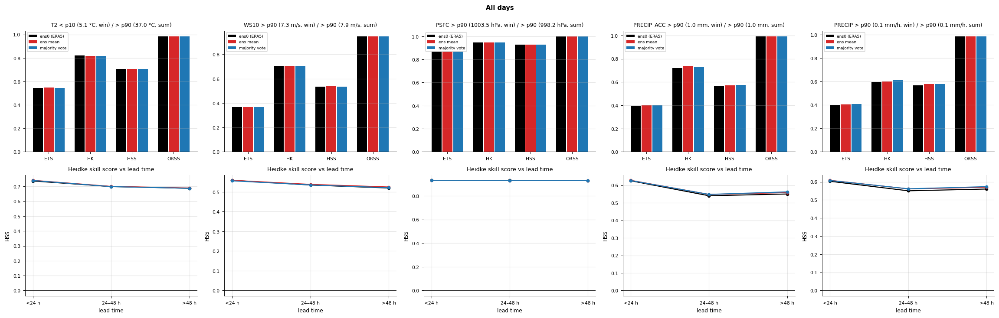

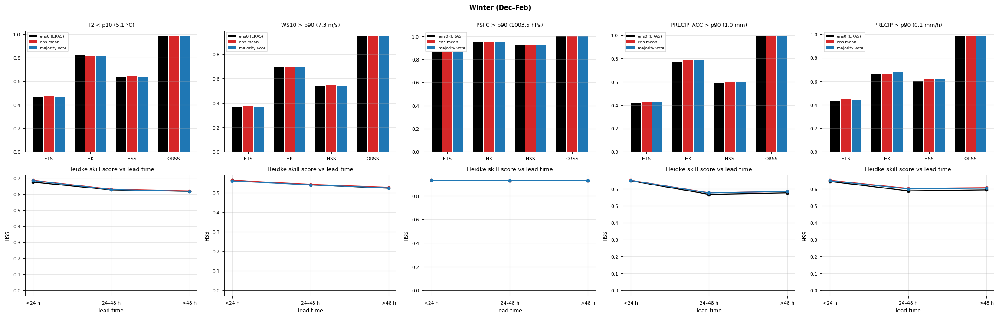

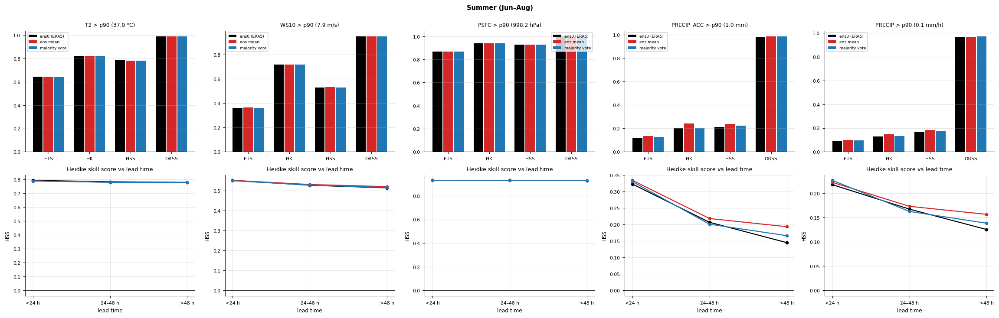

### Analysis: full contingency scores — All days

ETS, HK, HSS and ORSS are 0 for a forecast with no skill beyond chance and 1 for a perfect one.

- **2 m temperature**: `ens0`: HSS 0.71, ETS 0.55, HK 0.82, ORSS 0.98; ensemble mean: HSS 0.71, ETS 0.55, HK 0.82, ORSS 0.98; majority vote: HSS 0.71, ETS 0.55, HK 0.82, ORSS 0.98. Best HSS: ensemble mean (0.71). Good skill beyond chance.
- **10 m wind speed**: `ens0`: HSS 0.54, ETS 0.37, HK 0.71, ORSS 0.95; ensemble mean: HSS 0.54, ETS 0.37, HK 0.71, ORSS 0.95; majority vote: HSS 0.54, ETS 0.37, HK 0.71, ORSS 0.95. Best HSS: ensemble mean (0.54). Good skill beyond chance.
- **Surface pressure**: `ens0`: HSS 0.93, ETS 0.87, HK 0.95, ORSS 1.00; ensemble mean: HSS 0.93, ETS 0.87, HK 0.95, ORSS 1.00; majority vote: HSS 0.93, ETS 0.87, HK 0.95, ORSS 1.00. Best HSS: ensemble mean (0.93). Good skill beyond chance.
- **Precipitation (6 h total)**: `ens0`: HSS 0.57, ETS 0.39, HK 0.72, ORSS 0.99; ensemble mean: HSS 0.57, ETS 0.40, HK 0.74, ORSS 0.99; majority vote: HSS 0.57, ETS 0.40, HK 0.73, ORSS 0.99. Best HSS: majority vote (0.57). Good skill beyond chance.
- **Precipitation (hourly rate)**: `ens0`: HSS 0.57, ETS 0.40, HK 0.60, ORSS 0.99; ensemble mean: HSS 0.58, ETS 0.41, HK 0.60, ORSS 0.99; majority vote: HSS 0.58, ETS 0.41, HK 0.61, ORSS 0.99. Best HSS: majority vote (0.58). Good skill beyond chance.

### Analysis: full contingency scores — Winter (Dec–Feb)

ETS, HK, HSS and ORSS are 0 for a forecast with no skill beyond chance and 1 for a perfect one.

- **2 m temperature**: `ens0`: HSS 0.64, ETS 0.47, HK 0.82, ORSS 0.98; ensemble mean: HSS 0.64, ETS 0.47, HK 0.82, ORSS 0.98; majority vote: HSS 0.64, ETS 0.47, HK 0.81, ORSS 0.98. Best HSS: ensemble mean (0.64). Good skill beyond chance.
- **10 m wind speed**: `ens0`: HSS 0.54, ETS 0.37, HK 0.69, ORSS 0.94; ensemble mean: HSS 0.54, ETS 0.37, HK 0.70, ORSS 0.95; majority vote: HSS 0.54, ETS 0.37, HK 0.70, ORSS 0.95. Best HSS: ensemble mean (0.54). Good skill beyond chance.
- **Surface pressure**: `ens0`: HSS 0.93, ETS 0.87, HK 0.95, ORSS 1.00; ensemble mean: HSS 0.93, ETS 0.87, HK 0.95, ORSS 1.00; majority vote: HSS 0.93, ETS 0.87, HK 0.95, ORSS 1.00. Best HSS: ensemble mean (0.93). Good skill beyond chance.
- **Precipitation (6 h total)**: `ens0`: HSS 0.59, ETS 0.42, HK 0.77, ORSS 0.99; ensemble mean: HSS 0.60, ETS 0.43, HK 0.79, ORSS 0.99; majority vote: HSS 0.60, ETS 0.43, HK 0.79, ORSS 0.99. Best HSS: ensemble mean (0.60). Good skill beyond chance.
- **Precipitation (hourly rate)**: `ens0`: HSS 0.61, ETS 0.44, HK 0.66, ORSS 0.98; ensemble mean: HSS 0.62, ETS 0.45, HK 0.66, ORSS 0.98; majority vote: HSS 0.62, ETS 0.45, HK 0.68, ORSS 0.98. Best HSS: ensemble mean (0.62). Good skill beyond chance.

### Analysis: full contingency scores — Summer (Jun–Aug)

ETS, HK, HSS and ORSS are 0 for a forecast with no skill beyond chance and 1 for a perfect one.

- **2 m temperature**: `ens0`: HSS 0.78, ETS 0.65, HK 0.82, ORSS 0.99; ensemble mean: HSS 0.78, ETS 0.64, HK 0.82, ORSS 0.99; majority vote: HSS 0.78, ETS 0.64, HK 0.82, ORSS 0.99. Best HSS: `ens0` (0.78). Good skill beyond chance.
- **10 m wind speed**: `ens0`: HSS 0.53, ETS 0.36, HK 0.72, ORSS 0.95; ensemble mean: HSS 0.53, ETS 0.36, HK 0.72, ORSS 0.95; majority vote: HSS 0.53, ETS 0.36, HK 0.72, ORSS 0.95. Best HSS: ensemble mean (0.53). Good skill beyond chance.
- **Surface pressure**: `ens0`: HSS 0.93, ETS 0.87, HK 0.94, ORSS 1.00; ensemble mean: HSS 0.93, ETS 0.87, HK 0.94, ORSS 1.00; majority vote: HSS 0.93, ETS 0.87, HK 0.94, ORSS 1.00. Best HSS: majority vote (0.93). Good skill beyond chance.
- **Precipitation (6 h total)**: `ens0`: HSS 0.21, ETS 0.12, HK 0.20, ORSS 0.98; ensemble mean: HSS 0.24, ETS 0.13, HK 0.24, ORSS 0.98; majority vote: HSS 0.22, ETS 0.13, HK 0.21, ORSS 0.99. Best HSS: ensemble mean (0.24). Moderate skill beyond chance.
- **Precipitation (hourly rate)**: `ens0`: HSS 0.17, ETS 0.09, HK 0.13, ORSS 0.97; ensemble mean: HSS 0.18, ETS 0.10, HK 0.15, ORSS 0.97; majority vote: HSS 0.18, ETS 0.10, HK 0.13, ORSS 0.97. Best HSS: ensemble mean (0.18). The best forecast is only marginally better than chance.

In [27]:
# Full contingency scores: bars (ETS, HK, HSS, ORSS) and HSS / ETS vs lead-time bin
SC_PLOT = ["ETS", "HK", "HSS", "ORSS"]
for SEAS in SEAS_LIST:
    SLAB, SFX = SEAS_LABEL[SEAS], ("" if SEAS == "all" else "_" + SEAS)
    fig, axes = plt.subplots(2, len(VARS), figsize=(4.2 * len(VARS), 6.6), squeeze=False)
    for i, v in enumerate(VARS):
        if v not in CONT[SEAS].index.get_level_values("var"): continue
        t = CONT[SEAS].loc[v]
        ax = axes[0, i]
        for q, sc in enumerate(SC_PLOT):
            for kq, k in enumerate(["ctrl", "mean", "maj"]):
                ax.bar(q + (kq - 1) * 0.26, t.loc[k, sc], 0.24, color=CAT_COL[k], label=CAT_NAME[k] if q == 0 else None)
        ax.axhline(0, color="k", lw=0.5); ax.set_xticks(range(len(SC_PLOT))); ax.set_xticklabels(SC_PLOT)
        ax.set_title(f"{v} {EVLAB(v, SEAS)}", fontsize=8); ax.legend(fontsize=6); ax.grid(alpha=.3, axis="y")
        ax = axes[1, i]; tl = CONT_LEAD[SEAS]
        for k in ["ctrl", "mean", "maj"]:
            y_ = [tl.loc[(v, lb, k), "HSS"] if (v, lb, k) in tl.index else np.nan for lb in LEAD_LAB]
            ax.plot(LEAD_LAB, y_, "-o", ms=4, color=CAT_COL[k], label=CAT_NAME[k])
        ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("HSS"); ax.set_xlabel("lead time"); ax.grid(alpha=.3)
        ax.set_title("Heidke skill score vs lead time")
    fig.suptitle(SLAB, fontweight="bold", y=1.0); plt.tight_layout(); save_fig(fig, "contingency_full" + SFX); plt.show()

for SEAS in SEAS_LIST:
    L = [f"### Analysis: full contingency scores — {SEAS_LABEL[SEAS]}", "",
         "ETS, HK, HSS and ORSS are 0 for a forecast with no skill beyond chance and 1 for a perfect one.", ""]
    for v in VARS:
        if v not in CONT[SEAS].index.get_level_values("var"): continue
        t = CONT[SEAS].loc[v]
        hss = t["HSS"].dropna()
        if hss.empty:
            L.append(f"- **{VARS[v]['label']}**: no event / non-event pairs, scores undefined."); continue
        best = hss.idxmax()
        txt = "; ".join(f"{NAMES[k]}: HSS {t.loc[k, 'HSS']:.2f}, ETS {t.loc[k, 'ETS']:.2f}, HK {t.loc[k, 'HK']:.2f}, ORSS {t.loc[k, 'ORSS']:.2f}" for k in KEY)
        L.append(f"- **{VARS[v]['label']}**: {txt}. Best HSS: {NAMES[best]} ({hss[best]:.2f}). "
                 + ("The best forecast is only marginally better than chance." if hss[best] < 0.2 else
                    "Good skill beyond chance." if hss[best] > 0.5 else "Moderate skill beyond chance."))
    show(L)

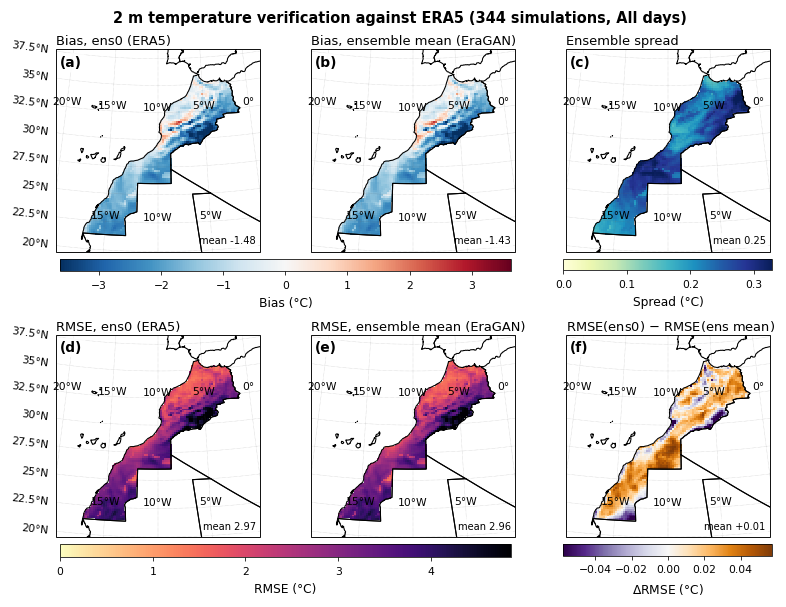

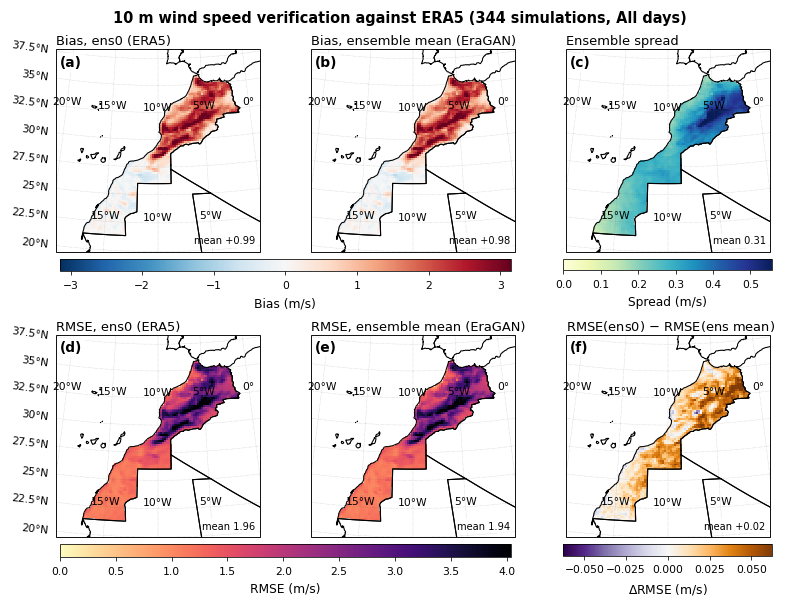

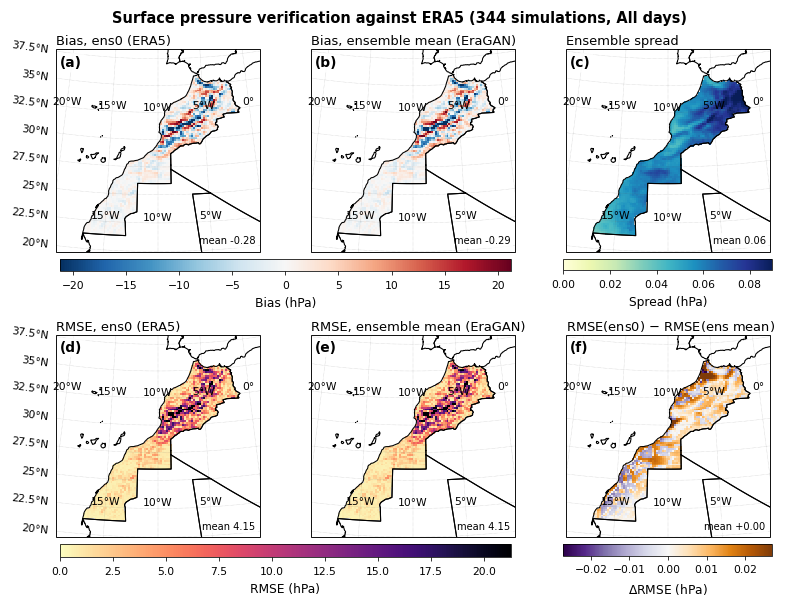

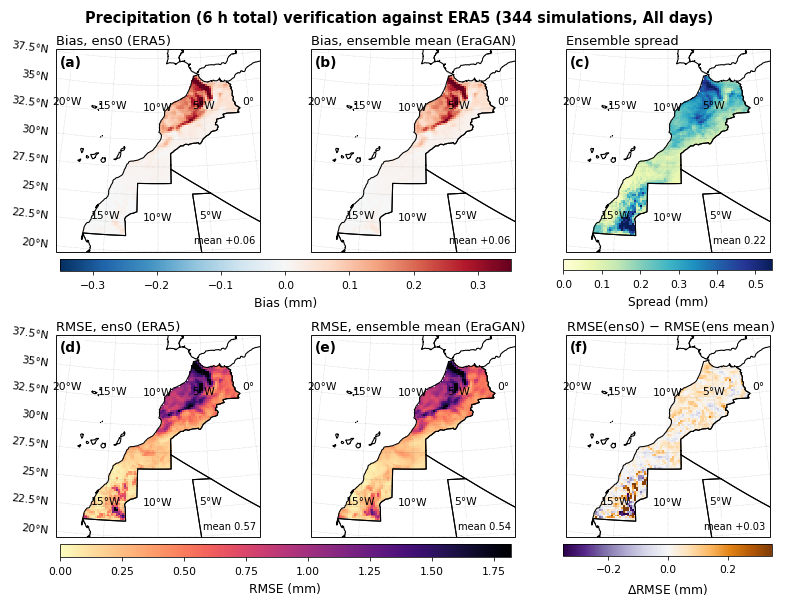

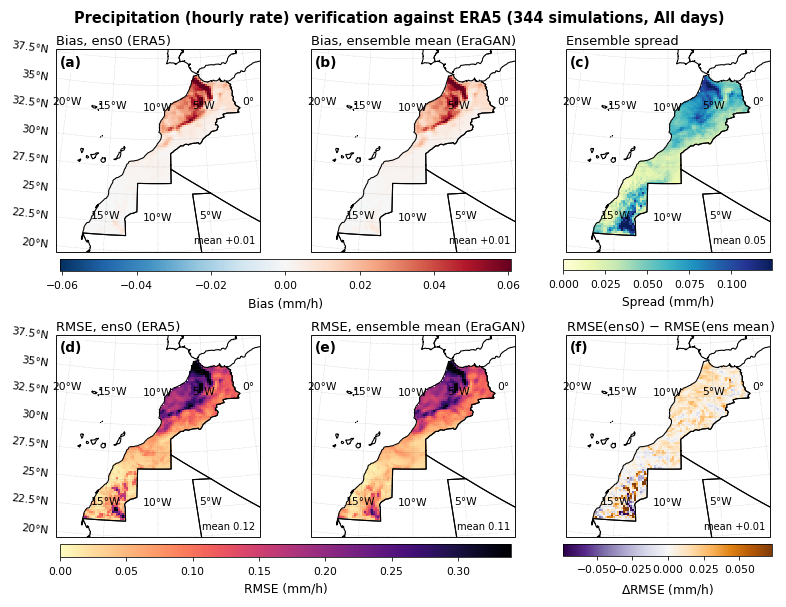

...

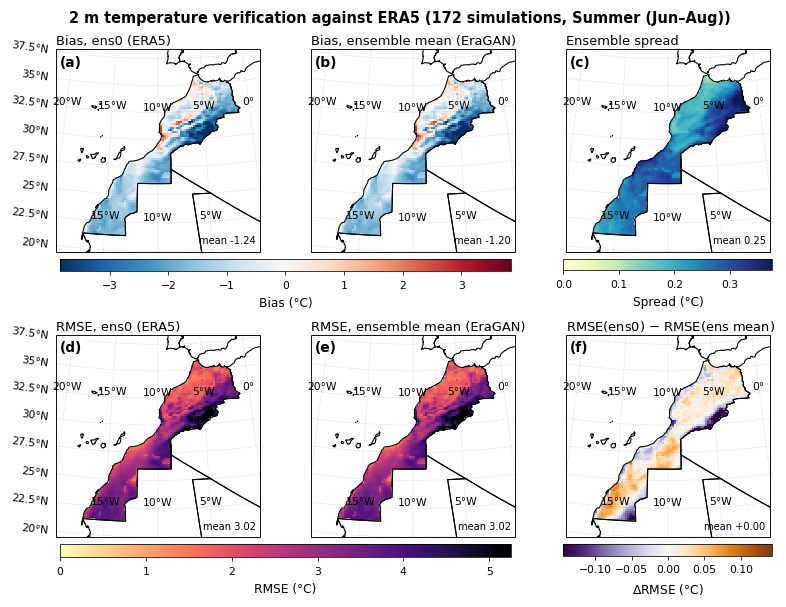

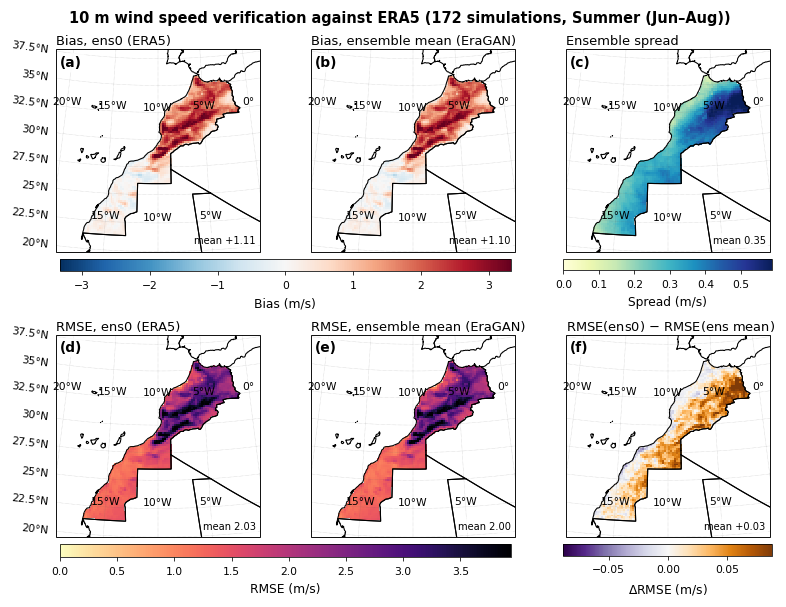

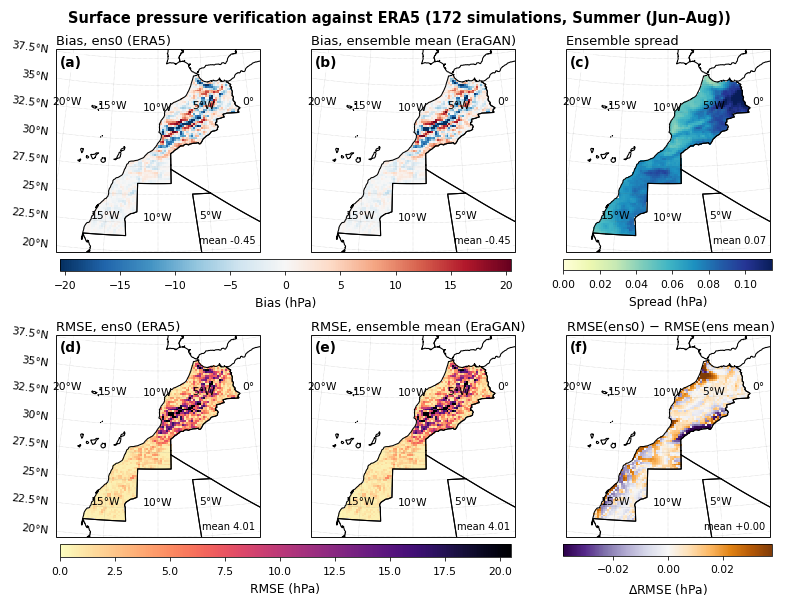

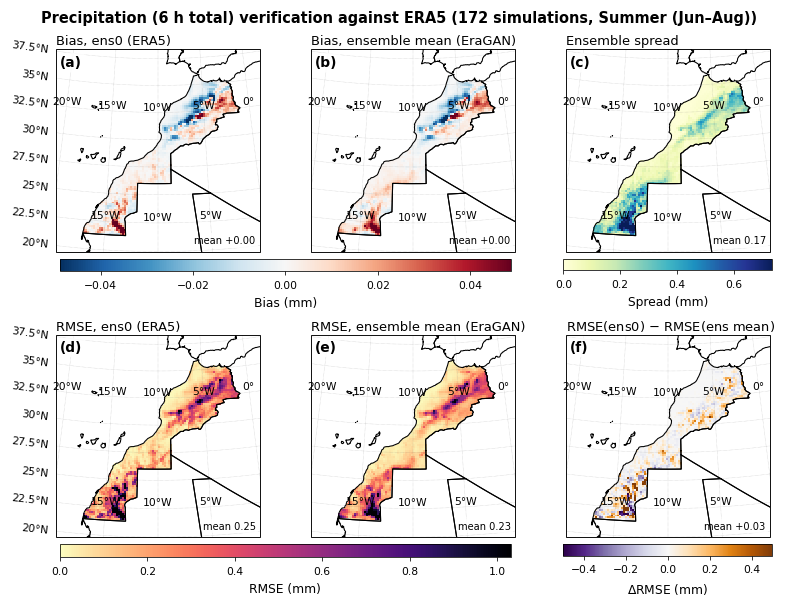

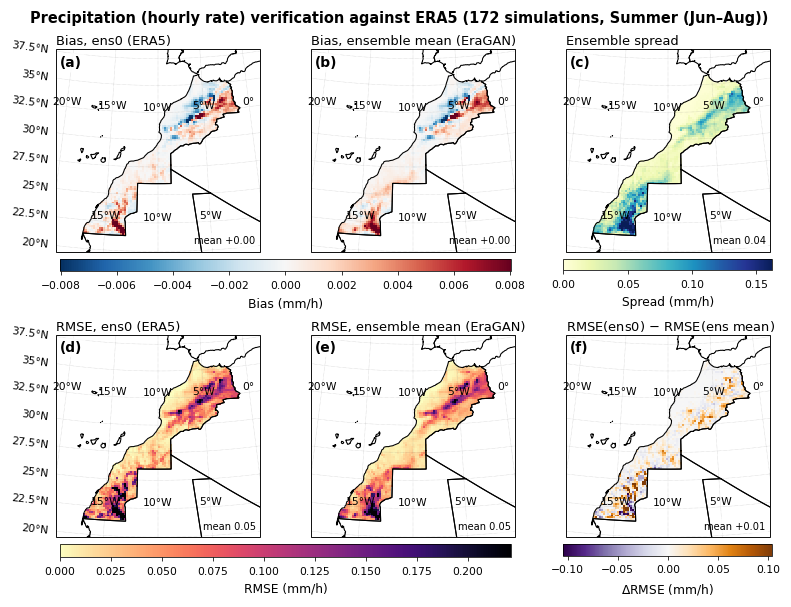

In [28]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    for v in VARS:
        M = MAP[v]; c = np.maximum(M["cnt"], 1); u = VARS[v]["unit"]
        nz = M["cnt"] == 0
        b_c, b_m = M["bias_c"] / c, M["bias_m"] / c
        r_c, r_m = np.sqrt(M["se_c"] / c), np.sqrt(M["se_m"] / c)
        spr = np.sqrt(M["var"] / c)
        dr  = r_c - r_m                                   # >0 : ensemble mean closer to ERA5 than ens0
        for a_ in (b_c, b_m, r_c, r_m, spr, dr): a_[nz] = np.nan      # points outside Morocco (never counted) stay blank
        bl  = np.nanpercentile(np.abs(np.r_[b_c.ravel(), b_m.ravel()]), 98)
        rh  = np.nanpercentile(np.r_[r_c.ravel(), r_m.ravel()], 98)
        sh  = np.nanpercentile(spr, 98)
        dl  = np.nanpercentile(np.abs(dr), 98)

        kw = dict(subplot_kw=dict(projection=MAPPROJ)) if HAS_CARTOPY else {}
        fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.4), constrained_layout=True, **kw)
        ims = [
            map_panel(fig, axes[0, 0], b_c, "RdBu_r", -bl, bl, "(a)", "Bias, ens0 (ERA5)",           f"mean {np.nanmean(b_c):+.2f}", True, False),
            map_panel(fig, axes[0, 1], b_m, "RdBu_r", -bl, bl, "(b)", "Bias, ensemble mean (EraGAN)", f"mean {np.nanmean(b_m):+.2f}", False, False),
            map_panel(fig, axes[0, 2], spr, "YlGnBu", 0, sh, "(c)", "Ensemble spread",               f"mean {np.nanmean(spr):.2f}", False, False),
            map_panel(fig, axes[1, 0], r_c, "magma_r", 0, rh, "(d)", "RMSE, ens0 (ERA5)",             f"mean {np.nanmean(r_c):.2f}", True, True),
            map_panel(fig, axes[1, 1], r_m, "magma_r", 0, rh, "(e)", "RMSE, ensemble mean (EraGAN)",  f"mean {np.nanmean(r_m):.2f}", False, True),
            map_panel(fig, axes[1, 2], dr,  "PuOr_r",  -dl, dl, "(f)", "RMSE(ens0) $-$ RMSE(ens mean)", f"mean {np.nanmean(dr):+.2f}", False, True),
        ]
        for im, ax_set, lab in [(ims[0], [axes[0, 0], axes[0, 1]], f"Bias ({u})"),
                                (ims[2], [axes[0, 2]],             f"Spread ({u})"),
                                (ims[3], [axes[1, 0], axes[1, 1]], f"RMSE ({u})"),
                                (ims[5], [axes[1, 2]],             rf"$\Delta$RMSE ({u})")]:
            cb = fig.colorbar(im, ax=ax_set, orientation="horizontal", shrink=0.9 if len(ax_set) > 1 else 0.85,
                              pad=0.03, aspect=35 if len(ax_set) > 1 else 18)
            cb.set_label(lab); cb.ax.tick_params(width=0.5, length=2.5); cb.outline.set_linewidth(0.5)
        fig.suptitle(f"{VARS[v]['label']} verification against ERA5 ({len(DSEL)} simulations, {SLAB})", fontsize=9.5, fontweight="bold")
        save_fig(fig, f"maps_{v}{SFX}"); plt.show()

In [29]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = ["### Analysis: spatial maps", ""]
    for v in VARS:
        M = MAP[v]; ok = M["cnt"] > 0; c = np.maximum(M["cnt"], 1); u = VARS[v]["unit"]
        b_c, b_m = (M["bias_c"] / c)[ok], (M["bias_m"] / c)[ok]
        r_c, r_m = np.sqrt(M["se_c"] / c)[ok], np.sqrt(M["se_m"] / c)[ok]
        spr = np.sqrt(M["var"] / c)[ok]
        better = np.mean(r_m < r_c) * 100
        cc = np.corrcoef(spr, r_m)[0, 1] if spr.std() > 0 and r_m.std() > 0 else np.nan
        la, lo = LAT[ok], LON[ok]; i = np.argmax(r_m)
        sp = "the spread is spatially informative: it is large where the error is large" if cc > 0.5 else ("the spread is only weakly related to where the errors are" if cc > 0.2 else "the spread carries almost no spatial information about the error")
        L.append(f"- **{VARS[v]['label']}**: domain-mean bias {b_c.mean():+.2f} {u} for `ens0` vs {b_m.mean():+.2f} {u} for the ensemble mean (mean absolute grid-point bias {np.abs(b_c).mean():.2f} vs {np.abs(b_m).mean():.2f}). Mean RMSE {r_c.mean():.2f} (`ens0`) vs {r_m.mean():.2f} (ensemble mean) {u}; the ensemble mean has the lower RMSE at {better:.0f}% of grid points. Largest ensemble-mean RMSE ({r_m[i]:.2f} {u}) is near {la[i]:.2f}N, {lo[i]:.2f}E. Spatial correlation spread vs error = {cc:.2f}: {sp}.")
    L.append("")
    L.append("Panel (f) is positive (orange) where the EraGAN ensemble mean is closer to ERA5 than the control; a mostly negative panel means the ERA5-driven run is better there.")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: spatial maps — All days

- **2 m temperature**: domain-mean bias -1.48 °C for `ens0` vs -1.43 °C for the ensemble mean (mean absolute grid-point bias 1.57 vs 1.53). Mean RMSE 2.97 (`ens0`) vs 2.96 (ensemble mean) °C; the ensemble mean has the lower RMSE at 76% of grid points. Largest ensemble-mean RMSE (5.71 °C) is near 30.73N, -4.64E. Spatial correlation spread vs error = 0.26: the spread is only weakly related to where the errors are.
- **10 m wind speed**: domain-mean bias +0.99 m/s for `ens0` vs +0.98 m/s for the ensemble mean (mean absolute grid-point bias 1.08 vs 1.08). Mean RMSE 1.96 (`ens0`) vs 1.94 (ensemble mean) m/s; the ensemble mean has the lower RMSE at 91% of grid points. Largest ensemble-mean RMSE (4.80 m/s) is near 31.20N, -6.93E. Spatial correlation spread vs error = 0.66: the spread is spatially informative: it is large where the error is large.
- **Surface pressure**: domain-mean bias -0.28 hPa for `ens0` vs -0.29 hPa for the ensemble mean (mean absolute grid-point bias 3.97 vs 3.97). Mean RMSE 4.15 (`ens0`) vs 4.15 (ensemble mean) hPa; the ensemble mean has the lower RMSE at 65% of grid points. Largest ensemble-mean RMSE (49.55 hPa) is near 30.88N, -8.63E. Spatial correlation spread vs error = 0.11: the spread carries almost no spatial information about the error.
- **Precipitation (6 h total)**: domain-mean bias +0.06 mm for `ens0` vs +0.06 mm for the ensemble mean (mean absolute grid-point bias 0.06 vs 0.06). Mean RMSE 0.57 (`ens0`) vs 0.54 (ensemble mean) mm; the ensemble mean has the lower RMSE at 70% of grid points. Largest ensemble-mean RMSE (3.08 mm) is near 35.15N, -5.40E. Spatial correlation spread vs error = 0.71: the spread is spatially informative: it is large where the error is large.
- **Precipitation (hourly rate)**: domain-mean bias +0.01 mm/h for `ens0` vs +0.01 mm/h for the ensemble mean (mean absolute grid-point bias 0.01 vs 0.01). Mean RMSE 0.12 (`ens0`) vs 0.11 (ensemble mean) mm/h; the ensemble mean has the lower RMSE at 77% of grid points. Largest ensemble-mean RMSE (0.57 mm/h) is near 35.15N, -5.40E. Spatial correlation spread vs error = 0.75: the spread is spatially informative: it is large where the error is large.

Panel (f) is positive (orange) where the EraGAN ensemble mean is closer to ERA5 than the control; a mostly negative panel means the ERA5-driven run is better there.

### Analysis: spatial maps — Winter (Dec–Feb)

- **2 m temperature**: domain-mean bias -1.71 °C for `ens0` vs -1.66 °C for the ensemble mean (mean absolute grid-point bias 1.78 vs 1.73). Mean RMSE 2.90 (`ens0`) vs 2.87 (ensemble mean) °C; the ensemble mean has the lower RMSE at 82% of grid points. Largest ensemble-mean RMSE (4.99 °C) is near 30.73N, -4.64E. Spatial correlation spread vs error = -0.13: the spread carries almost no spatial information about the error.
- **10 m wind speed**: domain-mean bias +0.87 m/s for `ens0` vs +0.87 m/s for the ensemble mean (mean absolute grid-point bias 1.06 vs 1.06). Mean RMSE 1.86 (`ens0`) vs 1.84 (ensemble mean) m/s; the ensemble mean has the lower RMSE at 82% of grid points. Largest ensemble-mean RMSE (5.24 m/s) is near 31.20N, -6.93E. Spatial correlation spread vs error = 0.80: the spread is spatially informative: it is large where the error is large.
- **Surface pressure**: domain-mean bias -0.12 hPa for `ens0` vs -0.13 hPa for the ensemble mean (mean absolute grid-point bias 4.11 vs 4.11). Mean RMSE 4.27 (`ens0`) vs 4.27 (ensemble mean) hPa; the ensemble mean has the lower RMSE at 62% of grid points. Largest ensemble-mean RMSE (50.84 hPa) is near 30.88N, -8.63E. Spatial correlation spread vs error = 0.38: the spread is only weakly related to where the errors are.
- **Precipitation (6 h total)**: domain-mean bias +0.12 mm for `ens0` vs +0.12 mm for the ensemble mean (mean absolute grid-point bias 0.12 vs 0.12). Mean RMSE 0.67 (`ens0`) vs 0.64 (ensemble mean) mm; the ensemble mean has the lower RMSE at 68% of grid points. Largest ensemble-mean RMSE (4.36 mm) is near 35.15N, -5.40E. Spatial correlation spread vs error = 0.94: the spread is spatially informative: it is large where the error is large.
- **Precipitation (hourly rate)**: domain-mean bias +0.02 mm/h for `ens0` vs +0.02 mm/h for the ensemble mean (mean absolute grid-point bias 0.02 vs 0.02). Mean RMSE 0.13 (`ens0`) vs 0.13 (ensemble mean) mm/h; the ensemble mean has the lower RMSE at 68% of grid points. Largest ensemble-mean RMSE (0.81 mm/h) is near 35.15N, -5.40E. Spatial correlation spread vs error = 0.95: the spread is spatially informative: it is large where the error is large.

Panel (f) is positive (orange) where the EraGAN ensemble mean is closer to ERA5 than the control; a mostly negative panel means the ERA5-driven run is better there.

### Analysis: spatial maps — Summer (Jun–Aug)

- **2 m temperature**: domain-mean bias -1.24 °C for `ens0` vs -1.20 °C for the ensemble mean (mean absolute grid-point bias 1.42 vs 1.39). Mean RMSE 3.02 (`ens0`) vs 3.02 (ensemble mean) °C; the ensemble mean has the lower RMSE at 65% of grid points. Largest ensemble-mean RMSE (6.34 °C) is near 30.73N, -4.64E. Spatial correlation spread vs error = 0.55: the spread is spatially informative: it is large where the error is large.
- **10 m wind speed**: domain-mean bias +1.11 m/s for `ens0` vs +1.10 m/s for the ensemble mean (mean absolute grid-point bias 1.16 vs 1.16). Mean RMSE 2.03 (`ens0`) vs 2.00 (ensemble mean) m/s; the ensemble mean has the lower RMSE at 83% of grid points. Largest ensemble-mean RMSE (4.84 m/s) is near 28.55N, -9.69E. Spatial correlation spread vs error = 0.43: the spread is only weakly related to where the errors are.
- **Surface pressure**: domain-mean bias -0.45 hPa for `ens0` vs -0.45 hPa for the ensemble mean (mean absolute grid-point bias 3.86 vs 3.85). Mean RMSE 4.01 (`ens0`) vs 4.01 (ensemble mean) hPa; the ensemble mean has the lower RMSE at 58% of grid points. Largest ensemble-mean RMSE (48.23 hPa) is near 30.88N, -8.63E. Spatial correlation spread vs error = -0.10: the spread carries almost no spatial information about the error.
- **Precipitation (6 h total)**: domain-mean bias +0.00 mm for `ens0` vs +0.00 mm for the ensemble mean (mean absolute grid-point bias 0.01 vs 0.01). Mean RMSE 0.25 (`ens0`) vs 0.23 (ensemble mean) mm; the ensemble mean has the lower RMSE at 55% of grid points. Largest ensemble-mean RMSE (1.90 mm) is near 21.97N, -13.81E. Spatial correlation spread vs error = 0.86: the spread is spatially informative: it is large where the error is large.
- **Precipitation (hourly rate)**: domain-mean bias +0.00 mm/h for `ens0` vs +0.00 mm/h for the ensemble mean (mean absolute grid-point bias 0.00 vs 0.00). Mean RMSE 0.05 (`ens0`) vs 0.05 (ensemble mean) mm/h; the ensemble mean has the lower RMSE at 56% of grid points. Largest ensemble-mean RMSE (0.40 mm/h) is near 22.14N, -13.82E. Spatial correlation spread vs error = 0.86: the spread is spatially informative: it is large where the error is large.

Panel (f) is positive (orange) where the EraGAN ensemble mean is closer to ERA5 than the control; a mostly negative panel means the ERA5-driven run is better there.

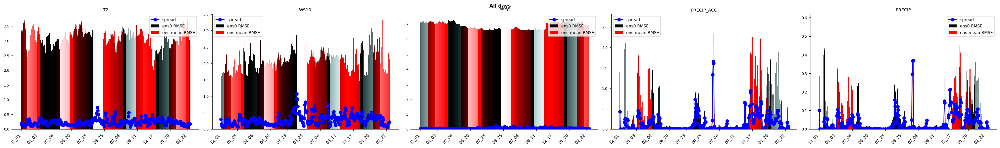

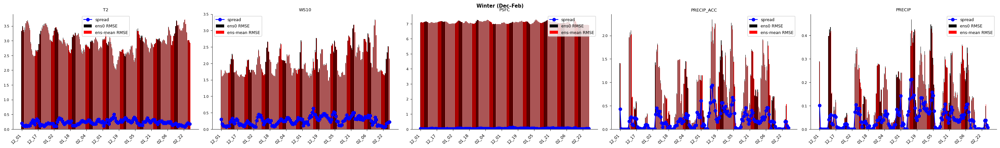

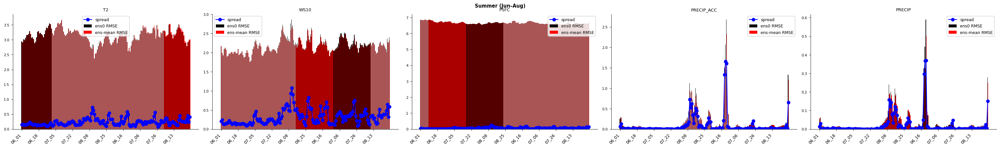

In [30]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    # Day-by-day scores: is the benefit consistent or driven by a few days?
    fig, axes = plt.subplots(1, len(VARS), figsize=(5.5 * len(VARS), 4), squeeze=False)
    for i, v in enumerate(VARS):
        t = DAYTAB.loc[v]
        x = np.arange(len(t))
        axes[0, i].bar(x - .2, t.rmse_ctrl, .4, color="k", label="ens0 RMSE")
        axes[0, i].bar(x + .2, t.rmse_mean, .4, color="r", label="ens-mean RMSE")
        axes[0, i].plot(x, t.spread, "b-o", label="spread")
        # axes[0, i].set_xticks(x); axes[0, i].set_xticklabels([s[5:] for s in t.index], rotation=70, fontsize=7)
        step = max(1, len(x) // 10)
        axes[0, i].set_xticks(x[::step]); axes[0, i].set_xticklabels([s[5:] for s in t.index][::step], rotation=45, ha="right", fontsize=8)
        axes[0, i].set_title(v); axes[0, i].legend(fontsize=8)
    plt.tight_layout(); plt.gcf().suptitle(SLAB, y=1.0, fontweight="bold"); save_fig(plt.gcf(), "per_day" + SFX); plt.show()

In [31]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = ["### Analysis: day-by-day consistency and significance", ""]
    for v in VARS:
        t = DAYTAB.loc[v]; nd = len(t)
        bd = int((t.rmse_mean < t.rmse_ctrl).sum())
        best, worst = t["RMSE_gain_%"].idxmax(), t["RMSE_gain_%"].idxmin()
        r = CI.loc[v]
        if r.CRPSS_lo > 0: sig = "**significantly positive**"
        elif r.CRPSS_hi < 0: sig = "**significantly negative**"
        else: sig = "**not distinguishable from zero**"
        note = f" (only {nd} days, treat the interval as indicative)" if nd < 6 else ""
        L.append(f"- **{v}**: the ensemble mean beats `ens0` (RMSE) on {bd}/{nd} days. Best day {best} ({t.loc[best, 'RMSE_gain_%']:+.1f}%), worst day {worst} ({t.loc[worst, 'RMSE_gain_%']:+.1f}%). Bootstrap CRPSS = {r.CRPSS_mean:+.3f} [{r.CRPSS_lo:+.3f}, {r.CRPSS_hi:+.3f}]: {sig}{note}.")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: day-by-day consistency and significance — All days

- **T2**: the ensemble mean beats `ens0` (RMSE) on 234/337 days. Best day 2018_08_11 (+4.8%), worst day 2022_07_25 (-3.3%). Bootstrap CRPSS = +0.035 [+0.033, +0.037]: **significantly positive**.
- **WS10**: the ensemble mean beats `ens0` (RMSE) on 289/337 days. Best day 2018_08_11 (+6.8%), worst day 2018_02_06 (-0.8%). Bootstrap CRPSS = +0.063 [+0.060, +0.067]: **significantly positive**.
- **PSFC**: the ensemble mean beats `ens0` (RMSE) on 269/337 days. Best day 2026_01_31 (+0.2%), worst day 2022_06_22 (-0.1%). Bootstrap CRPSS = +0.005 [+0.005, +0.006]: **significantly positive**.
- **PRECIP_ACC**: the ensemble mean beats `ens0` (RMSE) on 248/337 days. Best day 2017_12_24 (+49.6%), worst day 2022_08_12 (-21.3%). Bootstrap CRPSS = +0.187 [+0.172, +0.203]: **significantly positive**.
- **PRECIP**: the ensemble mean beats `ens0` (RMSE) on 228/337 days. Best day 2017_12_03 (+100.0%), worst day 2017_12_04 (-inf%). Bootstrap CRPSS = +0.216 [+0.198, +0.234]: **significantly positive**.

### Analysis: day-by-day consistency and significance — Winter (Dec–Feb)

- **T2**: the ensemble mean beats `ens0` (RMSE) on 147/167 days. Best day 2025_12_13 (+3.8%), worst day 2018_02_27 (-1.0%). Bootstrap CRPSS = +0.041 [+0.038, +0.044]: **significantly positive**.
- **WS10**: the ensemble mean beats `ens0` (RMSE) on 151/167 days. Best day 2025_12_13 (+4.7%), worst day 2018_02_06 (-0.8%). Bootstrap CRPSS = +0.065 [+0.061, +0.070]: **significantly positive**.
- **PSFC**: the ensemble mean beats `ens0` (RMSE) on 160/167 days. Best day 2026_01_31 (+0.2%), worst day 2026_02_05 (-0.1%). Bootstrap CRPSS = +0.005 [+0.005, +0.006]: **significantly positive**.
- **PRECIP_ACC**: the ensemble mean beats `ens0` (RMSE) on 129/167 days. Best day 2017_12_24 (+49.6%), worst day 2017_12_21 (-13.9%). Bootstrap CRPSS = +0.178 [+0.164, +0.194]: **significantly positive**.
- **PRECIP**: the ensemble mean beats `ens0` (RMSE) on 132/167 days. Best day 2017_12_03 (+100.0%), worst day 2017_12_04 (-inf%). Bootstrap CRPSS = +0.207 [+0.190, +0.225]: **significantly positive**.

### Analysis: day-by-day consistency and significance — Summer (Jun–Aug)

- **T2**: the ensemble mean beats `ens0` (RMSE) on 87/170 days. Best day 2018_08_11 (+4.8%), worst day 2022_07_25 (-3.3%). Bootstrap CRPSS = +0.029 [+0.027, +0.032]: **significantly positive**.
- **WS10**: the ensemble mean beats `ens0` (RMSE) on 138/170 days. Best day 2018_08_11 (+6.8%), worst day 2022_06_22 (-0.8%). Bootstrap CRPSS = +0.062 [+0.057, +0.068]: **significantly positive**.
- **PSFC**: the ensemble mean beats `ens0` (RMSE) on 109/170 days. Best day 2018_06_20 (+0.1%), worst day 2022_06_22 (-0.1%). Bootstrap CRPSS = +0.006 [+0.005, +0.006]: **significantly positive**.
- **PRECIP_ACC**: the ensemble mean beats `ens0` (RMSE) on 119/170 days. Best day 2018_08_11 (+27.7%), worst day 2022_08_12 (-21.3%). Bootstrap CRPSS = +0.246 [+0.190, +0.294]: **significantly positive**.
- **PRECIP**: the ensemble mean beats `ens0` (RMSE) on 96/170 days. Best day 2018_06_10 (+28.7%), worst day 2018_06_25 (-inf%). Bootstrap CRPSS = +0.281 [+0.220, +0.332]: **significantly positive**.

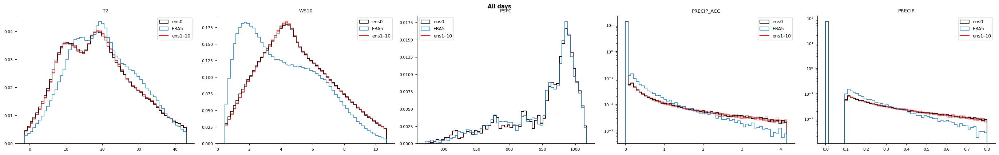

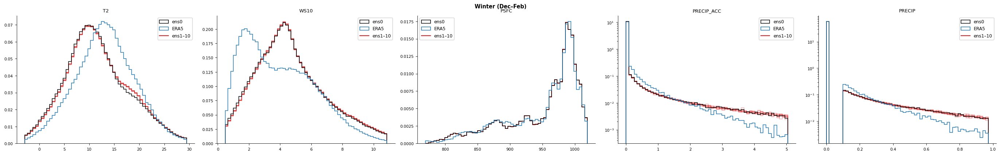

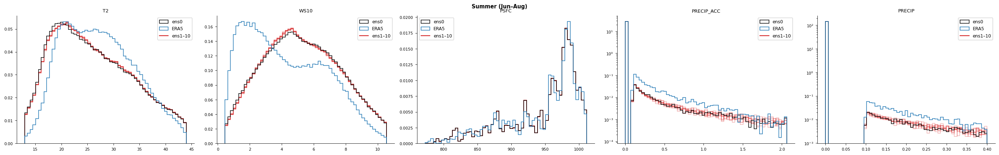

In [32]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    # Distribution check: do EraGAN-driven members reproduce the ERA5 distribution at the surface?
    fig, axes = plt.subplots(1, len(VARS), figsize=(5 * len(VARS), 3.8), squeeze=False)
    for i, v in enumerate(VARS):
        ax = axes[0, i]
        sl = (slice(None), slice(None), slice(None, None, STRIDE), slice(None, None, STRIDE))
        obs = np.concatenate([DSEL[d]["obs"][v][:, ::STRIDE, ::STRIDE].ravel() for d in DSEL]); obs = obs[np.isfinite(obs)]
        lo, hi = np.percentile(obs, [0.0, 99.9] if v.startswith("PRECIP") else [0.5, 99.5])
        if hi <= lo: hi = lo + 1.0
        bins = np.linspace(lo, hi, 60)
        for m in range(1, N + 1):
            x = np.concatenate([DSEL[d]["fc"][v][m, :, ::STRIDE, ::STRIDE].ravel() for d in DSEL]); x = x[np.isfinite(x)]
            ax.hist(x, bins, density=True, histtype="step", color="tab:red", alpha=.35)
        x0 = np.concatenate([DSEL[d]["fc"][v][0, :, ::STRIDE, ::STRIDE].ravel() for d in DSEL]); x0 = x0[np.isfinite(x0)]
        ax.hist(x0, bins, density=True, histtype="step", color="k", lw=1.5, label="ens0")
        ax.hist(obs, bins, density=True, histtype="step", color="tab:blue", lw=2, label="ERA5")
        ax.plot([], [], color="tab:red", label="ens1–10"); ax.set_title(v); ax.legend(fontsize=8)
        if v.startswith("PRECIP"): ax.set_yscale("log")
    plt.tight_layout(); plt.gcf().suptitle(SLAB, y=1.0, fontweight="bold"); save_fig(plt.gcf(), "distributions" + SFX); plt.show()

In [33]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    from scipy.stats import ks_2samp
    rs = np.random.default_rng(1)
    def pool(get, m=None, n=20000):
        x = np.concatenate([get(d) for d in DSEL.values()]); x = x[np.isfinite(x)]
        return rs.choice(x, min(n, x.size), replace=False)
    L = ["### Analysis: distributions", ""]
    for v in VARS:
        u = VARS[v]["unit"]
        ob = pool(lambda d: d["obs"][v][:, ::STRIDE, ::STRIDE].ravel())
        c0 = pool(lambda d: d["fc"][v][0, :, ::STRIDE, ::STRIDE].ravel())
        en = pool(lambda d: d["fc"][v][1:, :, ::STRIDE, ::STRIDE].ravel())
        k0, ke = ks_2samp(c0, ob).statistic, ks_2samp(en, ob).statistic
        sr = en.std() / ob.std()
        if sr < 0.9: vv = "the EraGAN-driven members **underestimate variability** (smoothed fields)"
        elif sr > 1.1: vv = "the EraGAN-driven members **exaggerate variability**"
        else: vv = "variability is well reproduced"
        cmp_ = "as well as" if abs(ke - k0) < 0.01 else ("better than" if ke < k0 else "worse than")
        L.append(f"- **{v}**: ERA5 mean/std {ob.mean():.2f}/{ob.std():.2f} {u}; `ens0` {c0.mean():.2f}/{c0.std():.2f}; EraGAN members {en.mean():.2f}/{en.std():.2f} (std ratio {sr:.2f}): {vv}. 5th-95th percentiles: ERA5 [{np.percentile(ob,5):.1f}, {np.percentile(ob,95):.1f}], members [{np.percentile(en,5):.1f}, {np.percentile(en,95):.1f}]. KS distance to ERA5 = {ke:.3f} (members) vs {k0:.3f} (`ens0`): the members reproduce the ERA5 distribution {cmp_} the control.")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: distributions — All days

- **T2**: ERA5 mean/std 20.09/9.68 °C; `ens0` 18.85/10.36; EraGAN members 18.78/10.26 (std ratio 1.06): variability is well reproduced. 5th-95th percentiles: ERA5 [5.0, 37.0], members [3.4, 37.4]. KS distance to ERA5 = 0.072 (members) vs 0.073 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **WS10**: ERA5 mean/std 4.17/2.41 m/s; `ens0` 5.13/2.58; EraGAN members 5.18/2.59 (std ratio 1.07): variability is well reproduced. 5th-95th percentiles: ERA5 [1.0, 8.5], members [1.5, 9.9]. KS distance to ERA5 = 0.187 (members) vs 0.179 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PSFC**: ERA5 mean/std 947.71/55.16 hPa; `ens0` 948.08/57.49; EraGAN members 946.57/58.25 (std ratio 1.06): variability is well reproduced. 5th-95th percentiles: ERA5 [835.4, 1006.9], members [825.2, 1007.5]. KS distance to ERA5 = 0.020 (members) vs 0.018 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PRECIP_ACC**: ERA5 mean/std 0.05/0.33 mm; `ens0` 0.13/1.03; EraGAN members 0.12/0.92 (std ratio 2.79): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [0.0, 0.2], members [0.0, 0.1]. KS distance to ERA5 = 0.018 (members) vs 0.017 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PRECIP**: ERA5 mean/std 0.01/0.06 mm/h; `ens0` 0.02/0.18; EraGAN members 0.02/0.18 (std ratio 3.10): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [0.0, 0.0], members [0.0, 0.0]. KS distance to ERA5 = 0.007 (members) vs 0.008 (`ens0`): the members reproduce the ERA5 distribution as well as the control.

### Analysis: distributions — Winter (Dec–Feb)

- **T2**: ERA5 mean/std 13.16/6.13 °C; `ens0` 11.46/6.77; EraGAN members 11.69/6.72 (std ratio 1.10): variability is well reproduced. 5th-95th percentiles: ERA5 [2.9, 23.2], members [1.2, 23.5]. KS distance to ERA5 = 0.145 (members) vs 0.159 (`ens0`): the members reproduce the ERA5 distribution better than the control.
- **WS10**: ERA5 mean/std 4.00/2.30 m/s; `ens0` 4.88/2.61; EraGAN members 4.97/2.60 (std ratio 1.13): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [1.0, 8.2], members [1.4, 9.9]. KS distance to ERA5 = 0.190 (members) vs 0.171 (`ens0`): the members reproduce the ERA5 distribution worse than the control.
- **PSFC**: ERA5 mean/std 949.12/56.74 hPa; `ens0` 949.41/59.83; EraGAN members 948.61/60.05 (std ratio 1.06): variability is well reproduced. 5th-95th percentiles: ERA5 [833.9, 1010.0], members [822.1, 1010.0]. KS distance to ERA5 = 0.020 (members) vs 0.024 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PRECIP_ACC**: ERA5 mean/std 0.08/0.40 mm; `ens0` 0.19/1.18; EraGAN members 0.21/1.17 (std ratio 2.90): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [0.0, 0.5], members [0.0, 0.8]. KS distance to ERA5 = 0.020 (members) vs 0.019 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PRECIP**: ERA5 mean/std 0.01/0.07 mm/h; `ens0` 0.03/0.24; EraGAN members 0.03/0.22 (std ratio 2.94): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [0.0, 0.0], members [0.0, 0.0]. KS distance to ERA5 = 0.016 (members) vs 0.017 (`ens0`): the members reproduce the ERA5 distribution as well as the control.

### Analysis: distributions — Summer (Jun–Aug)

- **T2**: ERA5 mean/std 27.22/6.98 °C; `ens0` 26.07/7.99; EraGAN members 26.20/7.96 (std ratio 1.14): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [17.1, 39.7], members [14.9, 40.8]. KS distance to ERA5 = 0.090 (members) vs 0.099 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **WS10**: ERA5 mean/std 4.36/2.51 m/s; `ens0` 5.39/2.55; EraGAN members 5.42/2.56 (std ratio 1.02): variability is well reproduced. 5th-95th percentiles: ERA5 [0.9, 8.7], members [1.5, 9.9]. KS distance to ERA5 = 0.190 (members) vs 0.185 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PSFC**: ERA5 mean/std 946.06/54.04 hPa; `ens0` 945.41/56.18; EraGAN members 944.58/57.00 (std ratio 1.05): variability is well reproduced. 5th-95th percentiles: ERA5 [836.7, 1004.3], members [822.1, 1004.0]. KS distance to ERA5 = 0.024 (members) vs 0.019 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PRECIP_ACC**: ERA5 mean/std 0.01/0.15 mm; `ens0` 0.02/0.40; EraGAN members 0.01/0.31 (std ratio 2.05): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [0.0, 0.0], members [0.0, 0.0]. KS distance to ERA5 = 0.016 (members) vs 0.015 (`ens0`): the members reproduce the ERA5 distribution as well as the control.
- **PRECIP**: ERA5 mean/std 0.00/0.03 mm/h; `ens0` 0.00/0.04; EraGAN members 0.00/0.05 (std ratio 1.76): the EraGAN-driven members **exaggerate variability**. 5th-95th percentiles: ERA5 [0.0, 0.0], members [0.0, 0.0]. KS distance to ERA5 = 0.004 (members) vs 0.004 (`ens0`): the members reproduce the ERA5 distribution as well as the control.

In [34]:
MR_S = {}
for SEAS in SEAS_LIST:
    use_season(SEAS)
    # Member-vs-member: is any EraGAN member an outlier? (RMSE of each member vs ERA5, averaged over everything)
    mem_rmse = {v: [] for v in VARS}
    for v in VARS:
        for m in range(len(ALL)):
            se, n = 0.0, 0
            for d in DSEL.values():
                e = d["fc"][v][m] - d["obs"][v]
                e = e[np.isfinite(e)]; se += (e**2).sum(); n += e.size
            mem_rmse[v].append(np.sqrt(se / max(n, 1)))
    MR = pd.DataFrame(mem_rmse, index=ALL).round(3)
    MR.to_csv(OUT / f"rmse_per_member{SFX}.csv"); MR_S[SEAS] = MR
    display(Markdown(f"**{SLAB}**")); display(MR.T)

**All days**

,ens0,ens1,ens2,ens3,ens4,ens5,ens6,ens7,ens8,ens9,ens10
T2,3.029,3.363,3.360,3.356,3.356,3.354,3.356,3.353,3.353,3.356,3.353
WS10,2.105,2.223,2.223,2.221,2.220,2.220,2.215,2.216,2.218,2.215,2.217
PSFC,6.879,6.876,6.876,6.876,6.874,6.875,6.876,6.875,6.877,6.876,6.876
PRECIP_ACC,0.753,0.754,0.756,0.761,0.756,0.757,0.739,0.758,0.755,0.746,0.756
PRECIP,0.150,0.151,0.151,0.152,0.151,0.151,0.148,0.152,0.151,0.150,0.151


**Winter (Dec–Feb)**

,ens0,ens1,ens2,ens3,ens4,ens5,ens6,ens7,ens8,ens9,ens10
T2,2.959,3.295,3.296,3.292,3.291,3.290,3.294,3.289,3.289,3.294,3.290
WS10,2.062,2.190,2.190,2.188,2.185,2.186,2.179,2.180,2.184,2.179,2.184
PSFC,7.084,7.080,7.080,7.079,7.078,7.079,7.079,7.078,7.079,7.079,7.079
PRECIP_ACC,0.986,0.984,0.987,0.986,0.986,0.989,0.968,0.987,0.985,0.968,0.982
PRECIP,0.194,0.194,0.194,0.194,0.194,0.195,0.191,0.194,0.194,0.191,0.193


**Summer (Jun–Aug)**

,ens0,ens1,ens2,ens3,ens4,ens5,ens6,ens7,ens8,ens9,ens10
T2,3.098,3.430,3.423,3.419,3.419,3.417,3.418,3.417,3.416,3.417,3.415
WS10,2.148,2.256,2.255,2.254,2.254,2.253,2.251,2.252,2.251,2.250,2.250
PSFC,6.666,6.665,6.665,6.665,6.665,6.665,6.665,6.665,6.665,6.665,6.665
PRECIP_ACC,0.397,0.404,0.410,0.425,0.417,0.411,0.389,0.414,0.403,0.415,0.418
PRECIP,0.086,0.088,0.089,0.092,0.090,0.088,0.084,0.090,0.088,0.091,0.090


In [35]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    MR = MR_S[SEAS]

    L = ["### Analysis: member-by-member RMSE", ""]
    for v in VARS:
        r = MR[v]; mem = r.drop(CTRL)
        med = mem.median(); mad = (mem - med).abs().median()
        bad = [k for k, x in mem.items() if x > 1.15 * med or (mad > 0 and x > med + 3 * 1.4826 * mad)]
        rk = int((r < r[CTRL]).sum()) + 1
        msg = ("outlier member(s): " + ", ".join(bad) + " (check these EraGAN samples)") if bad else "no outlier member"
        L.append(f"- **{v}**: members range {mem.min():.3f} ({mem.idxmin()}) to {mem.max():.3f} ({mem.idxmax()}) with median {med:.3f}, a {100*(mem.max()/mem.min()-1):.0f}% spread between best and worst; {msg}. `ens0` RMSE = {r[CTRL]:.3f} (rank {rk} of {len(r)}; expected to be favourable because it is driven by the verifying data).")
    L[0] += f" — {SLAB}"; show(L)

### Analysis: member-by-member RMSE — All days

- **T2**: members range 3.353 (ens7) to 3.363 (ens1) with median 3.356, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 3.029 (rank 1 of 11; expected to be favourable because it is driven by the verifying data).
- **WS10**: members range 2.215 (ens6) to 2.223 (ens1) with median 2.219, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 2.105 (rank 1 of 11; expected to be favourable because it is driven by the verifying data).
- **PSFC**: members range 6.874 (ens4) to 6.877 (ens8) with median 6.876, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 6.879 (rank 11 of 11; expected to be favourable because it is driven by the verifying data).
- **PRECIP_ACC**: members range 0.739 (ens6) to 0.761 (ens3) with median 0.756, a 3% spread between best and worst; no outlier member. `ens0` RMSE = 0.753 (rank 3 of 11; expected to be favourable because it is driven by the verifying data).
- **PRECIP**: members range 0.148 (ens6) to 0.152 (ens3) with median 0.151, a 3% spread between best and worst; no outlier member. `ens0` RMSE = 0.150 (rank 2 of 11; expected to be favourable because it is driven by the verifying data).

### Analysis: member-by-member RMSE — Winter (Dec–Feb)

- **T2**: members range 3.289 (ens7) to 3.296 (ens2) with median 3.292, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 2.959 (rank 1 of 11; expected to be favourable because it is driven by the verifying data).
- **WS10**: members range 2.179 (ens6) to 2.190 (ens1) with median 2.184, a 1% spread between best and worst; no outlier member. `ens0` RMSE = 2.062 (rank 1 of 11; expected to be favourable because it is driven by the verifying data).
- **PSFC**: members range 7.078 (ens4) to 7.080 (ens1) with median 7.079, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 7.084 (rank 11 of 11; expected to be favourable because it is driven by the verifying data).
- **PRECIP_ACC**: members range 0.968 (ens6) to 0.989 (ens5) with median 0.985, a 2% spread between best and worst; no outlier member. `ens0` RMSE = 0.986 (rank 6 of 11; expected to be favourable because it is driven by the verifying data).
- **PRECIP**: members range 0.191 (ens6) to 0.195 (ens5) with median 0.194, a 2% spread between best and worst; no outlier member. `ens0` RMSE = 0.194 (rank 4 of 11; expected to be favourable because it is driven by the verifying data).

### Analysis: member-by-member RMSE — Summer (Jun–Aug)

- **T2**: members range 3.415 (ens10) to 3.430 (ens1) with median 3.418, a 0% spread between best and worst; outlier member(s): ens1 (check these EraGAN samples). `ens0` RMSE = 3.098 (rank 1 of 11; expected to be favourable because it is driven by the verifying data).
- **WS10**: members range 2.250 (ens9) to 2.256 (ens1) with median 2.253, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 2.148 (rank 1 of 11; expected to be favourable because it is driven by the verifying data).
- **PSFC**: members range 6.665 (ens1) to 6.665 (ens1) with median 6.665, a 0% spread between best and worst; no outlier member. `ens0` RMSE = 6.666 (rank 11 of 11; expected to be favourable because it is driven by the verifying data).
- **PRECIP_ACC**: members range 0.389 (ens6) to 0.425 (ens3) with median 0.413, a 9% spread between best and worst; no outlier member. `ens0` RMSE = 0.397 (rank 2 of 11; expected to be favourable because it is driven by the verifying data).
- **PRECIP**: members range 0.084 (ens6) to 0.092 (ens3) with median 0.090, a 10% spread between best and worst; no outlier member. `ens0` RMSE = 0.086 (rank 2 of 11; expected to be favourable because it is driven by the verifying data).

### Winter vs summer comparison
Key scores side by side (also saved as `seasonal_comparison.csv`).

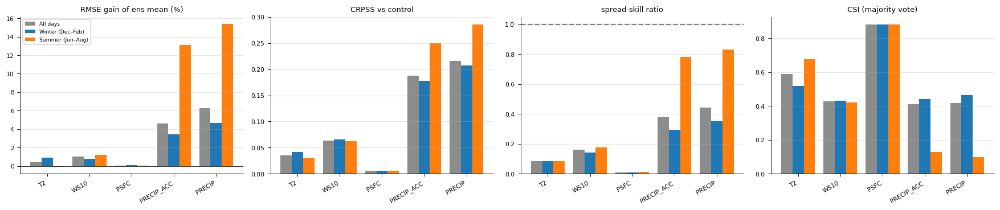

RMSE_gain_%  CRPSS_vs_ctrl    SSR  BSS_ens  POD_maj  \
var        period                                                        
PRECIP     all           6.263          0.216  0.443    0.241    0.622   
           summer       15.388          0.286  0.833   -0.112    0.135   
           winter        4.662          0.207  0.351    0.288    0.698   
PRECIP_ACC all           4.629          0.187  0.378    0.081    0.744   
           summer       13.127          0.250  0.780   -0.211    0.207   
           winter        3.403          0.178  0.292    0.108    0.809   
PSFC       all           0.046          0.005  0.010    0.858    0.956   
           summer        0.017          0.006  0.012    0.860    0.947   
           winter        0.071          0.005  0.007    0.855    0.966   
T2         all           0.383          0.035  0.085    0.346    0.870   
           summer       -0.066          0.030  0.086    0.557    0.852   
           winter        0.876          0.041  0.083    0.118    0.891   
WS10       all           1.000          0.064  0.161   -0.147    0.813   
           summer        1.194          0.062  0.176   -0.190    0.829   
           winter        0.788          0.065  0.143   -0.103    0.796   

                   FAR_maj  CSI_maj  rmse_ctrl  rmse_mean  
var        period                                          
PRECIP     all       0.441    0.418      0.147      0.138  
           summer    0.732    0.099      0.082      0.070  
           winter    0.422    0.463      0.191      0.182  
PRECIP_ACC all       0.523    0.410      0.736      0.702  
           summer    0.752    0.127      0.378      0.328  
           winter    0.509    0.440      0.971      0.938  
PSFC       all       0.082    0.881      6.877      6.874  
           summer    0.072    0.882      6.664      6.663  
           winter    0.091    0.881      7.084      7.079  
T2         all       0.357    0.587      3.096      3.084  
           summer    0.236    0.675      3.161      3.163  
           winter    0.448    0.517      3.029      3.003  
WS10       all       0.528    0.426      2.145      2.124  
           summer    0.538    0.422      2.190      2.164  
           winter    0.517    0.430      2.100      2.084

In [36]:
# Winter vs summer, side by side
SEAS_TAB = pd.concat({s: STATS[s]["SUMMARY"][["RMSE_gain_%", "CRPSS_vs_ctrl", "SSR", "BSS_ens", "POD_maj", "FAR_maj", "CSI_maj", "rmse_ctrl", "rmse_mean"]] for s in SEAS_LIST},
                     names=["period", "var"]).swaplevel().sort_index()
SEAS_TAB.to_csv(OUT / "seasonal_comparison.csv")
if len(SEAS_LIST) > 1:
    cols = [("RMSE_gain_%", "RMSE gain of ens mean (%)"), ("CRPSS_vs_ctrl", "CRPSS vs control"), ("SSR", "spread-skill ratio"), ("CSI_maj", "CSI (majority vote)")]
    cc = {"all": "0.55", "winter": "tab:blue", "summer": "tab:orange"}
    fig, axes = plt.subplots(1, len(cols), figsize=(4.0 * len(cols), 3.4), squeeze=False)
    w = 0.8 / len(SEAS_LIST)
    for a, (c, lab) in zip(axes[0], cols):
        for q, s in enumerate(SEAS_LIST):
            a.bar(np.arange(len(VARS)) + (q - (len(SEAS_LIST) - 1) / 2) * w, [STATS[s]["SUMMARY"][c].get(v, np.nan) for v in VARS], w, color=cc.get(s, None), label=SEAS_LABEL[s])
        a.set_xticks(range(len(VARS))); a.set_xticklabels(list(VARS), rotation=30, ha="right"); a.set_title(lab); a.grid(alpha=.3, axis="y")
        if c == "SSR": a.axhline(1, color="gray", ls="--")
        else: a.axhline(0, color="k", lw=0.5)
    axes[0, 0].legend(fontsize=6); plt.tight_layout(); save_fig(fig, "seasonal_comparison"); plt.show()
SEAS_TAB.round(3)


## 5. Overall assessment (auto-generated)

In [37]:
for SEAS in SEAS_LIST:
    use_season(SEAS)
    L = ["### Overall assessment", ""]
    for v in VARS:
        sm, r = SUMMARY.loc[v], CI.loc[v]
        if r.CRPSS_lo > 0: sk = f"the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS {r.CRPSS_mean:+.3f}, 95% CI [{r.CRPSS_lo:+.3f}, {r.CRPSS_hi:+.3f}])"
        elif r.CRPSS_hi < 0: sk = f"the ERA5-driven control is **significantly better** than the EraGAN ensemble (CRPSS {r.CRPSS_mean:+.3f}, CI [{r.CRPSS_lo:+.3f}, {r.CRPSS_hi:+.3f}])"
        else: sk = f"no significant CRPS difference from the control (CRPSS {r.CRPSS_mean:+.3f}, CI [{r.CRPSS_lo:+.3f}, {r.CRPSS_hi:+.3f}])"
        if sm.SSR < 0.85: adv = "increase the EraGAN sampling diversity or the number of members"
        elif sm.SSR > 1.15: adv = "reduce the EraGAN perturbation amplitude"
        else: adv = "keep the current spread"
        L.append(f"- **{VARS[v]['label']}**: {sk}. Ensemble-mean RMSE is {sm['RMSE_gain_%']:+.1f}% vs `ens0`. SSR = {sm.SSR:.2f} ({disp_verdict(sm.SSR)}); suggestion: {adv}. Extreme-event BSS: {sm.BSS_ens:+.2f} vs {sm.BSS_ctrl:+.2f} for `ens0`.")
    L.append("")
    L.append("*These statements are generated automatically from the numbers above. Verification is against ERA5, which also drives `ens0`, so the control is favoured: a positive result is robust, a negative one should be re-checked against station observations.*")
    L[0] += f" — {SLAB}"; show(L)

### Overall assessment — All days

- **2 m temperature**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.035, 95% CI [+0.033, +0.037]). Ensemble-mean RMSE is +0.4% vs `ens0`. SSR = 0.08 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.35 vs +0.32 for `ens0`.
- **10 m wind speed**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.063, 95% CI [+0.060, +0.067]). Ensemble-mean RMSE is +1.0% vs `ens0`. SSR = 0.16 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: -0.15 vs -0.22 for `ens0`.
- **Surface pressure**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.005, 95% CI [+0.005, +0.006]). Ensemble-mean RMSE is +0.0% vs `ens0`. SSR = 0.01 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.86 vs +0.86 for `ens0`.
- **Precipitation (6 h total)**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.187, 95% CI [+0.172, +0.203]). Ensemble-mean RMSE is +4.6% vs `ens0`. SSR = 0.38 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.08 vs -0.10 for `ens0`.
- **Precipitation (hourly rate)**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.216, 95% CI [+0.198, +0.234]). Ensemble-mean RMSE is +6.3% vs `ens0`. SSR = 0.44 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.24 vs +0.09 for `ens0`.

*These statements are generated automatically from the numbers above. Verification is against ERA5, which also drives `ens0`, so the control is favoured: a positive result is robust, a negative one should be re-checked against station observations.*

### Overall assessment — Winter (Dec–Feb)

- **2 m temperature**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.041, 95% CI [+0.038, +0.044]). Ensemble-mean RMSE is +0.9% vs `ens0`. SSR = 0.08 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.12 vs +0.06 for `ens0`.
- **10 m wind speed**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.065, 95% CI [+0.061, +0.070]). Ensemble-mean RMSE is +0.8% vs `ens0`. SSR = 0.14 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: -0.10 vs -0.17 for `ens0`.
- **Surface pressure**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.005, 95% CI [+0.005, +0.006]). Ensemble-mean RMSE is +0.1% vs `ens0`. SSR = 0.01 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.86 vs +0.85 for `ens0`.
- **Precipitation (6 h total)**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.178, 95% CI [+0.164, +0.194]). Ensemble-mean RMSE is +3.4% vs `ens0`. SSR = 0.29 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.11 vs -0.07 for `ens0`.
- **Precipitation (hourly rate)**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.207, 95% CI [+0.190, +0.225]). Ensemble-mean RMSE is +4.7% vs `ens0`. SSR = 0.35 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.29 vs +0.14 for `ens0`.

*These statements are generated automatically from the numbers above. Verification is against ERA5, which also drives `ens0`, so the control is favoured: a positive result is robust, a negative one should be re-checked against station observations.*

### Overall assessment — Summer (Jun–Aug)

- **2 m temperature**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.029, 95% CI [+0.027, +0.032]). Ensemble-mean RMSE is -0.1% vs `ens0`. SSR = 0.09 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.56 vs +0.55 for `ens0`.
- **10 m wind speed**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.062, 95% CI [+0.057, +0.068]). Ensemble-mean RMSE is +1.2% vs `ens0`. SSR = 0.18 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: -0.19 vs -0.27 for `ens0`.
- **Surface pressure**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.006, 95% CI [+0.005, +0.006]). Ensemble-mean RMSE is +0.0% vs `ens0`. SSR = 0.01 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: +0.86 vs +0.86 for `ens0`.
- **Precipitation (6 h total)**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.246, 95% CI [+0.190, +0.294]). Ensemble-mean RMSE is +13.1% vs `ens0`. SSR = 0.78 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: -0.21 vs -0.49 for `ens0`.
- **Precipitation (hourly rate)**: the EraGAN ensemble **adds significant probabilistic skill** over the single ERA5-driven run (CRPSS +0.281, 95% CI [+0.220, +0.332]). Ensemble-mean RMSE is +15.4% vs `ens0`. SSR = 0.83 (**under-dispersive** (spread too small for the error: over-confident)); suggestion: increase the EraGAN sampling diversity or the number of members. Extreme-event BSS: -0.11 vs -0.28 for `ens0`.

*These statements are generated automatically from the numbers above. Verification is against ERA5, which also drives `ens0`, so the control is favoured: a positive result is robust, a negative one should be re-checked against station observations.*

## 6. What to look for
* **CRPSS > 0 with a CI above zero** → the EraGAN ensemble adds value over the single ERA5-driven run.
* **SSR < 1 and U-shaped rank histogram** → ensemble too tight; EraGAN perturbations are too small. **SSR > 1** → too much noise.
* **Spread at lead 0** reflects EraGAN initial diversity; check that it grows with lead time (it should for a healthy ensemble).
* **Member RMSE table**: a member far above the others signals a bad EraGAN sample.
* **BSS_ens > BSS_ctrl** → probabilistic information helps for extremes.
* **POD high, FAR low, CSI high, FBI ≈ 1** → events are detected without many false alarms and with the right frequency. A majority-vote FBI far below 1 means the members are too smooth to reach the event threshold.
* **Initial conditions (section 2c)**: `ens0` should start at ~0 error; members with a clearly larger initial RMSE are bad EraGAN samples; the initial spread should be comparable to the initial error of the ensemble mean.
* **Winter vs summer**: compare the two blocks of every table/figure; differences in precipitation scores mostly reflect the different number of wet events (see `n_events`).


## 7. Verification against station observations (independent truth)
Because `ens0` is driven by ERA5, verifying it against ERA5 flatters it. Here every member is also verified against **your station observations**, which are independent of both ERA5 and the EraGAN perturbations.

* **Observation file** (one row per station and time): `wmoid, datetime, t2m_o, d2m_o, mslp_o, tp_o, sp_o, ws_o, wd_o, o_Neb, o_visi, o_WTH, rh_o, station, lon_era5, lat_era5`. Set `OBS_FILE` in the next cell (or leave `None` to search `ROOTS` for `*obs*.csv`). Exact duplicate rows are removed, impossible values are set to missing, and times are assumed to be UTC like the WRF output.
* **Matching:** each station is matched to the nearest WRF land grid point (`lon_era5` / `lat_era5` are used as station coordinates; these are ERA5 cell centres, so replace them with the true coordinates if you have them). Stations farther than `STN_MAX_KM` from a grid point are dropped. No terrain-height correction is applied to T2.
* **Variables verified:** every variable of `VARS` that has an observation column (`T2` ← `t2m_o`, `WS10` ← `ws_o`, precipitation ← `tp_o`). Check `OBS_WS_FACTOR` (wind unit) and `OBS_TP_H` (hours covered by each `tp_o` value).
* **Scores:** bias, RMSE, MAE, correlation, fair CRPS, CRPSS vs `ens0`, spread-skill ratio, Brier skill score and the full contingency scores for the season-specific tail event of the station observations ("above the seasonal p90", or "below the seasonal p10" for winter T2) (floors from `thr_min` for precipitation), rank histograms and reliability diagrams, lead-time and diurnal curves, per-station bars and a station map.
* **ERA5 at the station** is scored as a fourth "forecast". It is the reference for the question *does WRF (ens0) or the EraGAN ensemble add value over the driving analysis at the stations?* Every period (all days, winter, summer) is reported.

In [38]:
# ---------------- 7a. station observations: configuration, loading, quality control ----------------
OBS_FILE   = None            # e.g. DRIVE / "WRF-GEN" / "obs_stations.csv"; None = look for *obs*.csv in ROOTS and their parents
OBS_COLS   = {"T2": "t2m_o", "WS10": "ws_o", "PRECIP": "tp_o"}   # model variable -> observation column
OBS_WS_FACTOR    = 1.0       # multiply ws_o by this to get m/s (0.5144 if the observations are in knots, 0.2778 if km/h)
OBS_TP_H         = 1         # hours covered by each tp_o value (1 = hourly totals, 3 / 6 / 24 = totals over the hours ending at the time stamp)
OBS_UTC_OFFSET_H = 0         # add this to the observation time stamps to get UTC
STN_MIN_PAIRS    = 30        # stations with fewer valid obs/forecast pairs are left out of the per-station tables
STN_MAX_KM       = None      # drop stations farther than this from a WRF land grid point (None = 2 grid spacings)
OBS_RANGE        = {"T2": (-60, 60), "WS10": (0, 80), "PRECIP": (0, 500)}      # physical limits: values outside are set to missing

def find_obs_file():
    if OBS_FILE: return Path(OBS_FILE)
    for r in ROOTS + [r.parent for r in ROOTS]:
        for pat in ("obs*.csv", "*obs*.csv", "*station*.csv", "*obs*.csv.gz"):
            hit = sorted(r.glob(pat))
            if hit: return hit[0]
    return None

OBS_PATH = find_obs_file()
assert OBS_PATH is not None and OBS_PATH.exists(), ("observation file not found: set OBS_FILE in this cell "
                                                    "(csv with columns wmoid, datetime, t2m_o, ..., station, lon_era5, lat_era5)")
print("observation file:", OBS_PATH)

OBS = pd.read_csv(OBS_PATH, low_memory=False)
OBS = OBS.loc[:, ~OBS.columns.astype(str).str.startswith("Unnamed")]          # index column written by to_csv
for c in ("datetime", "station", "lat_era5", "lon_era5"):
    assert c in OBS.columns, f"column '{c}' missing from the observation file (found: {list(OBS.columns)})"
n0 = len(OBS)
OBS["datetime"] = pd.to_datetime(OBS["datetime"], errors="coerce") + pd.Timedelta(hours=OBS_UTC_OFFSET_H)
OBS = OBS.dropna(subset=["datetime", "station"]).drop_duplicates()             # the sample shows repeated identical rows
num = [c for c in OBS.columns if c not in ("datetime", "station") and pd.api.types.is_numeric_dtype(OBS[c])]
if OBS.duplicated(["station", "datetime"]).any():                              # same station and time with different values -> average
    OBS = OBS.groupby(["station", "datetime"], as_index=False)[num].mean()
print(f"{n0} rows read -> {len(OBS)} unique station-time rows, {OBS.station.nunique()} stations, "
      f"{OBS.datetime.min():%Y-%m-%d} to {OBS.datetime.max():%Y-%m-%d}")

# unit checks and quality control
if "t2m_o" in OBS and OBS["t2m_o"].median() > 150:
    OBS["t2m_o"] -= 273.15; print("t2m_o looked like Kelvin -> converted to °C")
if OBS_COLS.get("WS10") in OBS: OBS[OBS_COLS["WS10"]] *= OBS_WS_FACTOR
for v, (lo, hi) in OBS_RANGE.items():
    c = OBS_COLS.get(v)
    if c in OBS:
        bad = (OBS[c] < lo) | (OBS[c] > hi)
        if bad.any(): print(f"{c}: {int(bad.sum())} values outside [{lo}, {hi}] set to missing")
        OBS.loc[bad, c] = np.nan
avail = {v: c for v, c in OBS_COLS.items() if c in OBS.columns and OBS[c].notna().any()}
print("observation coverage (% non-missing):", {c: round(100 * OBS[c].notna().mean(), 1) for c in avail.values()})

# ---------------- stations -> nearest WRF land grid point ----------------
STN = OBS.groupby("station").agg(lat=("lat_era5", "median"), lon=("lon_era5", "median"), n_obs=("datetime", "size"))
cosl = np.cos(np.deg2rad(np.nanmean(LAT)))
dx_km = float(np.nanmedian(np.hypot(np.diff(LAT, axis=1), np.diff(LON, axis=1) * cosl))) * 111.19
if STN_MAX_KM is None: STN_MAX_KM = 2 * dx_km
print(f"WRF grid spacing ~{dx_km:.1f} km; stations farther than {STN_MAX_KM:.0f} km from a land grid point are dropped")
iy, ix, dist = [], [], []
for st, r_ in STN.iterrows():
    d2 = (LAT - r_.lat) ** 2 + ((LON - r_.lon) * np.cos(np.deg2rad(r_.lat))) ** 2
    d2 = np.where(MASK, d2, np.inf)
    a, b = np.unravel_index(np.argmin(d2), d2.shape)
    iy.append(a); ix.append(b); dist.append(float(np.sqrt(d2[a, b])) * 111.19)
STN["iy"], STN["ix"], STN["dist_km"] = iy, ix, dist
STN["wrf_lat"], STN["wrf_lon"] = LAT[STN.iy, STN.ix], LON[STN.iy, STN.ix]
dropped = STN.index[STN.dist_km > STN_MAX_KM].tolist()
if dropped: print("dropped (too far from the WRF domain / land mask):", dropped)
STN = STN[STN.dist_km <= STN_MAX_KM]
assert len(STN), "no station falls inside the WRF domain: check lat_era5 / lon_era5 and STN_MAX_KM"
STN_LIST, IY, IX = STN.index.tolist(), STN.iy.values, STN.ix.values
STN.round(2)

observation file: /content/drive/MyDrive/WRF-GEN/obs_stations_2016-2024.csv
29708112 rows read -> 2390736 unique station-time rows, 36 stations, 2016-01-01 to 2024-10-31
t2m_o: 1 values outside [-60, 60] set to missing
observation coverage (% non-missing): {'t2m_o': np.float64(88.9), 'ws_o': np.float64(87.5), 'tp_o': np.float64(5.5)}
WRF grid spacing ~19.9 km; stations farther than 40 km from a land grid point are dropped


,lat,lon,n_obs,iy,ix,dist_km,wrf_lat,wrf_lon
station,,,,,,,,
AGADIR,30.47,-9.68,66480,60,53,6.67,30.530001,-9.69
AIT-MELLOUL,30.22,-9.43,67248,58,54,7.21,30.170000,-9.48
BOUARFA,32.47,-1.93,76704,73,89,8.33,32.540001,-1.90
CASA-ANFA,33.47,-7.68,75240,76,62,7.61,33.400002,-7.71
DAKHLA,23.72,-15.93,63456,22,21,19.54,23.590000,-15.80
EL-HOCEIMA,35.22,-3.93,69384,86,79,19.22,35.060001,-3.84
EL-JADIDA,33.22,-8.43,72264,75,59,6.48,33.230000,-8.37
ERRACHIDIA,31.97,-4.43,46680,69,78,10.03,31.990000,-4.33
ESSAOUIRA-PORT,31.47,-9.68,69408,65,53,4.10,31.430000,-9.68


In [39]:
# ---------------- 7b. observation series on the WRF time axis, and the station-forecast table ----------------
def obs_series(st, v, hrs_step):
    """Observation series of one station for variable v (same definition as in the WRF/ERA5 verification), or None."""
    g = OBS[OBS.station == st].set_index("datetime").sort_index()
    c = OBS_COLS[v.replace("_ACC", "")] if v.replace("_ACC", "") in OBS_COLS else None
    if c is None or c not in g: return None
    s = g[c]
    if v == "T2" or v == "WS10": return s
    # precipitation: tp_o is a total over OBS_TP_H hours ending at the time stamp
    s = s.reindex(pd.date_range(s.index.min().floor(f"{OBS_TP_H}h"), s.index.max(), freq=f"{OBS_TP_H}h"))
    if v == "PRECIP_ACC":
        if ACC_H % OBS_TP_H: return None
        k = ACC_H // OBS_TP_H
        return pd.Series(dry_cut(s.rolling(k, min_periods=k).sum().values, ACC_MIN), index=s.index)
    if v == "PRECIP":                                     # mean rate (mm/h) over one WRF output interval
        if abs(hrs_step - OBS_TP_H) > 1e-6: return None
        return pd.Series(dry_cut((s / OBS_TP_H).values), index=s.index)

step_h = float(np.median(np.diff(next(iter(D.values()))["lead"])))
OBS_SER, SVARS = {}, []
for v in VARS:
    ser = {st: obs_series(st, v, step_h) for st in STN_LIST}
    ser = {st: s for st, s in ser.items() if s is not None}
    if ser:
        OBS_SER[v] = ser; SVARS.append(v)
    else:
        print(f"{v}: no usable observation (column missing, or OBS_TP_H={OBS_TP_H} does not fit ACC_H={ACC_H} / output step {step_h:g} h) -> skipped")
print("variables verified against stations:", SVARS)

RNG_ST = np.random.default_rng(7)
SRv, ENS = {}, {}
for v in SVARS:
    parts, ens_parts = [], []
    for day, d in D.items():
        t = d["times"]
        o = np.column_stack([OBS_SER[v][st].reindex(t).values if st in OBS_SER[v] else np.full(len(t), np.nan)
                             for st in STN_LIST]).astype("float32")                      # (time, station)
        f = d["fc"][v][:, :, IY, IX]                                                     # (member, time, station)
        e = d["obs"][v][:, IY, IX]                                                       # ERA5 at the station cell
        ok = np.isfinite(o) & np.isfinite(f).all(0) & (d["lead"][:, None] >= SPINUP_H)
        tt, ss = np.nonzero(ok)
        if not len(tt): continue
        ens, y = f[1:, tt, ss], o[tt, ss]
        rk = (ens < y).sum(0) + np.floor(RNG_ST.random(len(y)) * ((ens == y).sum(0) + 1)).astype(int)
        parts.append(pd.DataFrame(dict(day=day, season=DAY_SEASON[day], var=v, station=np.array(STN_LIST)[ss], time=t[tt],
                                       lead=d["lead"][tt], obs=y, era5=e[tt, ss], ctrl=f[0, tt, ss], mean=ens.mean(0),
                                       var_ens=ens.var(0, ddof=1), crps=crps_fair(ens, y), rank=rk)))
        ens_parts.append(ens)
    if parts:
        SRv[v], ENS[v] = pd.concat(parts, ignore_index=True), np.concatenate(ens_parts, axis=1)
assert SRv, "no valid station / forecast pair: check the observation dates against the simulated days and the units"

# event thresholds from the station observations: same rule as for ERA5 (season-specific; cold tail for winter T2; same floors)
THR_S, EVS_S = {}, {}
for v in SRv:
    for s_ in SEAS_LIST:
        sub = SRv[v] if s_ == "all" else SRv[v][SRv[v].season == s_]
        if sub.empty: continue
        sg_, pc_ = event_def(v, s_)
        t_ = float(np.nanpercentile(sub.obs, pc_))
        if sg_ == ">": t_ = max(t_, VARS[v].get("thr_min", -np.inf))
        THR_S[(s_, v)], EVS_S[(s_, v)] = t_, sg_
print("station event thresholds (season-specific, from the observations):")
for s_ in SEAS_LIST:
    print(f"  {s_:7s}", {v: f"{EVS_S[(s_, v)]} {THR_S[(s_, v)]:.2f}" for v in SRv if (s_, v) in THR_S})

def EVLAB_S(v, s):
    u = VARS[v]["unit"]
    if s != "all" and (s, v) in THR_S:
        return f"{EVS_S[(s, v)]} {THR_S[(s, v)]:.1f} {u} (obs p{event_def(v, s)[1]})"
    return " / ".join(f"{EVS_S[(x, v)]} {THR_S[(x, v)]:.1f} {u} ({x[:3]})" for x in SEAS_LIST if x != "all" and (x, v) in THR_S)

for v, g in SRv.items():
    keys = g["season"].where(g["season"].isin(SEAS_LIST), "all")          # days outside every season -> pooled threshold
    thr = keys.map(lambda s_: THR_S[(s_, v)]).to_numpy(dtype=float)       # one threshold per row
    cold = (keys.map(lambda s_: EVS_S[(s_, v)]).to_numpy() == "<")        # one tail direction per row
    ev_row = lambda a_: np.where(cold, np.asarray(a_) < thr, np.asarray(a_) > thr)
    g["k"] = np.where(cold, ENS[v] < thr, ENS[v] > thr).sum(0)
    g["p"] = g.k / N
    g["ev_o"], g["ev_c"], g["ev_m"] = ev_row(g.obs.values), ev_row(g.ctrl.values), ev_row(g["mean"].values)
    g["ev_p"], g["ev_e"] = g.p >= 0.5, ev_row(g.era5.values)
SR = pd.concat(SRv.values(), ignore_index=True)
SR["hour"] = pd.DatetimeIndex(SR.time).hour
print(f"{len(SR)} observation-forecast pairs, {SR.station.nunique()} stations, {SR.day.nunique()} simulation days")
SR.groupby("var").agg(pairs=("obs", "size"), stations=("station", "nunique"), obs_mean=("obs", "mean"),
                      obs_event_rate=("ev_o", "mean")).round(3)

PSFC: no usable observation (column missing, or OBS_TP_H=1 does not fit ACC_H=6 / output step 3 h) -> skipped
PRECIP: no usable observation (column missing, or OBS_TP_H=1 does not fit ACC_H=6 / output step 3 h) -> skipped
variables verified against stations: ['T2', 'WS10', 'PRECIP_ACC']
station event thresholds (season-specific, from the observations):
  all     {'T2': '> 29.80', 'WS10': '> 7.00', 'PRECIP_ACC': '> 1.00'}
  winter  {'T2': '< 6.40', 'WS10': '> 7.00', 'PRECIP_ACC': '> 5.40'}
  summer  {'T2': '> 31.90', 'WS10': '> 7.00', 'PRECIP_ACC': '> 1.00'}
334304 observation-forecast pairs, 36 stations, 250 simulation days


,pairs,stations,obs_mean,obs_event_rate
var,,,,
PRECIP_ACC,6122,27,0.717,0.051
T2,166543,36,20.170,0.099
WS10,161639,36,3.686,0.089


In [40]:
# ---------------- 7c. scores against the stations: tables per period ----------------
def stn_summary(g, v):
    """Continuous, probabilistic and categorical scores of one block of station pairs."""
    s = {"n": len(g), "n_stations": g.station.nunique()}
    for nm in ("ctrl", "mean", "era5"):
        e = g[nm] - g.obs
        s[f"bias_{nm}"], s[f"rmse_{nm}"], s[f"mae_{nm}"] = e.mean(), np.sqrt((e ** 2).mean()), e.abs().mean()
        s[f"corr_{nm}"] = g[nm].corr(g.obs)
    s["spread"], s["crps"] = np.sqrt(g.var_ens.mean()), g.crps.mean()
    s["SSR"] = np.sqrt((N + 1) / N) * s["spread"] / s["rmse_mean"]
    s["RMSE_gain_%"] = 100 * (1 - s["rmse_mean"] / s["rmse_ctrl"])                  # ensemble mean vs ens0
    s["CRPSS_vs_ctrl"] = 1 - s["crps"] / s["mae_ctrl"]
    s["ctrl_vs_ERA5_%"] = 100 * (1 - s["rmse_ctrl"] / s["rmse_era5"]) if s["rmse_era5"] > 1e-9 else np.nan               # >0: WRF ens0 closer to the obs than ERA5 itself
    s["mean_vs_ERA5_%"] = 100 * (1 - s["rmse_mean"] / s["rmse_era5"]) if s["rmse_era5"] > 1e-9 else np.nan
    o = g.ev_o.mean()
    s["BSS_ens"] = 1 - ((g.p - g.ev_o) ** 2).mean() / (o * (1 - o)) if 0 < o < 1 else np.nan
    s["BSS_ctrl"] = 1 - ((g.ev_c.astype(float) - g.ev_o) ** 2).mean() / (o * (1 - o)) if 0 < o < 1 else np.nan
    s["event_rate_obs"] = o
    return pd.Series(s)

def stn_cont(g):
    ge = g[np.isfinite(g.era5)]
    rows = {}
    for k, col, gg in (("ctrl", "ev_c", g), ("mean", "ev_m", g), ("maj", "ev_p", g), ("era5", "ev_e", ge)):
        f, o = gg[col].values.astype(bool), gg.ev_o.values.astype(bool)
        rows[k] = cont_scores((f & o).sum(), (~f & o).sum(), (f & ~o).sum(), (~f & ~o).sum())
    return pd.DataFrame(rows).T

PER = {s: (SR if s == "all" else SR[SR.season == s]) for s in SEAS_LIST}
PER = {s: g for s, g in PER.items() if len(g)}
ST_SUM  = {s: pd.DataFrame({v: stn_summary(g[g["var"] == v], v) for v in SRv if (g["var"] == v).any()}).T for s, g in PER.items()}
ST_CONT = {s: pd.concat({v: stn_cont(g[g["var"] == v]) for v in SRv if (g["var"] == v).any()}, names=["var", "forecast"]) for s, g in PER.items()}
def by_station(g, v):
    t = pd.DataFrame({st: stn_summary(x, v) for st, x in g.groupby("station")}).T
    t.index.name = "station"
    return t[t.n >= STN_MIN_PAIRS]
ST_STN  = {s: pd.concat({v: by_station(g[g["var"] == v], v) for v in SRv if (g["var"] == v).any()}, names=["var"]) for s, g in PER.items()}
for s in PER:
    sfx = "" if s == "all" else "_" + s
    ST_SUM[s].to_csv(OUT / f"stations_summary{sfx}.csv"); ST_CONT[s].to_csv(OUT / f"stations_contingency_full{sfx}.csv")
    ST_STN[s].to_csv(OUT / f"stations_by_station{sfx}.csv")
SR.to_csv(OUT / "stations_pairs.csv.gz", index=False)
print("Headline scores against station observations (per period):")
STN_SUM_ALL = pd.concat(ST_SUM, names=["period", "var"])
STN_SUM_ALL.round(3)

Headline scores against station observations (per period):


n  n_stations  bias_ctrl  rmse_ctrl  mae_ctrl  \
period var                                                                
all    T2          166543.0        36.0     -0.212      3.025     2.209   
       WS10        161639.0        36.0      0.780      2.319     1.755   
       PRECIP_ACC    6122.0        27.0     -0.259      2.068     0.450   
winter T2           55387.0        33.0     -0.778      2.571     1.998   
       WS10         53765.0        33.0      0.811      2.271     1.713   
       PRECIP_ACC    2800.0        26.0     -0.524      3.024     0.938   
summer T2          111156.0        36.0      0.070      3.228     2.315   
       WS10        107874.0        36.0      0.764      2.342     1.776   
       PRECIP_ACC    3322.0         9.0     -0.035      0.416     0.038   

                   corr_ctrl  bias_mean  rmse_mean  mae_mean  corr_mean  ...  \
period var                                                               ...   
all    T2              0.930     -0.128      3.043     2.220      0.929  ...   
       WS10            0.632      0.779      2.309     1.748      0.634  ...   
       PRECIP_ACC      0.788     -0.266      2.012     0.436      0.804  ...   
winter T2              0.873     -0.701      2.561     1.987      0.870  ...   
       WS10            0.621      0.804      2.261     1.704      0.623  ...   
       PRECIP_ACC      0.781     -0.542      2.942     0.909      0.798  ...   
summer T2              0.853      0.157      3.256     2.336      0.850  ...   
       WS10            0.634      0.766      2.333     1.770      0.636  ...   
       PRECIP_ACC      0.364     -0.034      0.411     0.037      0.342  ...   

                   spread   crps    SSR  RMSE_gain_%  CRPSS_vs_ctrl  \
period var                                                            
all    T2           0.223  2.155  0.077       -0.590          0.025   
       WS10         0.262  1.675  0.119        0.420          0.046   
       PRECIP_ACC   0.332  0.402  0.173        2.677          0.106   
winter T2           0.223  1.919  0.091        0.363          0.039   
       WS10         0.211  1.632  0.098        0.475          0.047   
       PRECIP_ACC   0.486  0.836  0.173        2.714          0.109   
summer T2           0.223  2.272  0.072       -0.889          0.019   
       WS10         0.284  1.696  0.128        0.394          0.045   
       PRECIP_ACC   0.068  0.036  0.174        1.072          0.054   

                   ctrl_vs_ERA5_%  mean_vs_ERA5_%  BSS_ens  BSS_ctrl  \
period var                                                             
all    T2                 -51.472         -52.365    0.256     0.239   
       WS10               -27.981         -27.443   -0.532    -0.591   
       PRECIP_ACC          27.133          29.084    0.314     0.285   
winter T2                 -45.747         -45.217    0.143     0.106   
       WS10               -30.178         -29.561   -0.353    -0.424   
       PRECIP_ACC          27.548          29.514    0.324     0.289   
summer T2                 -53.358         -54.721    0.312     0.305   
       WS10               -26.968         -26.467   -0.606    -0.661   
       PRECIP_ACC          -4.366          -3.246    0.017     0.017   

                   event_rate_obs  
period var                         
all    T2                   0.099  
       WS10                 0.089  
       PRECIP_ACC           0.051  
winter T2                   0.098  
       WS10                 0.075  
       PRECIP_ACC           0.099  
summer T2                   0.100  
       WS10                 0.096  
       PRECIP_ACC           0.011  

[9 rows x 24 columns]

In [41]:
# Full contingency scores against the stations (ens0, ensemble mean, majority vote, ERA5 at the station)
STN_CONT_ALL = pd.concat(ST_CONT, names=["period"])
STN_CONT_ALL[["n", "hits", "misses", "false_alarms", "correct_neg", "accuracy", "FBI", "POD", "FAR", "POFD", "SR", "CSI",
              "ETS", "HK", "HSS", "ORSS", "odds_ratio"]].round(3)

n     hits  misses  false_alarms  \
period var        forecast                                            
all    T2         ctrl      166543.0  12886.0  3662.0        7675.0   
                  mean      166543.0  12751.0  3797.0        7571.0   
                  maj       166543.0  12771.0  3777.0        7645.0   
                  era5      165539.0  11935.0  4242.0        3172.0   
       WS10       ctrl      161639.0   9330.0  5017.0       15788.0   
                  mean      161639.0   9263.0  5084.0       15667.0   
                  maj       161639.0   9318.0  5029.0       15871.0   
                  era5      160640.0   7485.0  6784.0        3459.0   
       PRECIP_ACC ctrl        6122.0    140.0   174.0          39.0   
                  mean        6122.0    132.0   182.0          30.0   
                  maj         6122.0    133.0   181.0          31.0   
                  era5        6122.0     26.0   288.0           0.0   
winter T2         ctrl       55387.0   4037.0  1405.0        2983.0   
                  mean       55387.0   3860.0  1582.0        2752.0   
                  maj        55387.0   3872.0  1570.0        2804.0   
                  era5       55387.0   3859.0  1583.0        1518.0   
       WS10       ctrl       53765.0   2581.0  1454.0        3860.0   
                  mean       53765.0   2579.0  1456.0        3814.0   
                  maj        53765.0   2601.0  1434.0        3886.0   
                  era5       53765.0   2060.0  1975.0        1338.0   
       PRECIP_ACC ctrl        2800.0    139.0   139.0          39.0   
                  mean        2800.0    131.0   147.0          30.0   
                  maj         2800.0    132.0   146.0          31.0   
                  era5        2800.0     20.0   258.0           0.0   
summer T2         ctrl      111156.0   8849.0  2257.0        4692.0   
                  mean      111156.0   8891.0  2215.0        4819.0   
                  maj       111156.0   8899.0  2207.0        4841.0   
                  era5      110152.0   8076.0  2659.0        1654.0   
       WS10       ctrl      107874.0   6749.0  3563.0       11928.0   
                  mean      107874.0   6684.0  3628.0       11853.0   
                  maj       107874.0   6717.0  3595.0       11985.0   
                  era5      106875.0   5425.0  4809.0        2121.0   
       PRECIP_ACC ctrl        3322.0      1.0    35.0           0.0   
                  mean        3322.0      1.0    35.0           0.0   
                  maj         3322.0      1.0    35.0           0.0   
                  era5        3322.0      6.0    30.0           0.0   

                            correct_neg  accuracy    FBI    POD    FAR   POFD  \
period var        forecast                                                      
all    T2         ctrl         142320.0     0.932  1.243  0.779  0.373  0.051   
                  mean         142424.0     0.932  1.228  0.771  0.373  0.050   
                  maj          142350.0     0.931  1.234  0.772  0.374  0.051   
                  era5         146190.0     0.955  0.934  0.738  0.210  0.021   
       WS10       ctrl         131504.0     0.871  1.751  0.650  0.629  0.107   
                  mean         131625.0     0.872  1.738  0.646  0.628  0.106   
                  maj          131421.0     0.871  1.756  0.649  0.630  0.108   
                  era5         142912.0     0.936  0.767  0.525  0.316  0.024   
       PRECIP_ACC ctrl           5769.0     0.965  0.570  0.446  0.218  0.007   
                  mean           5778.0     0.965  0.516  0.420  0.185  0.005   
                  maj            5777.0     0.965  0.522  0.424  0.189  0.005   
                  era5           5808.0     0.953  0.083  0.083  0.000  0.000   
winter T2         ctrl          46962.0     0.921  1.290  0.742  0.425  0.060   
                  mean          47193.0     0.922  1.215  0.709  0.416  0.055   
                  maj           47141.0 

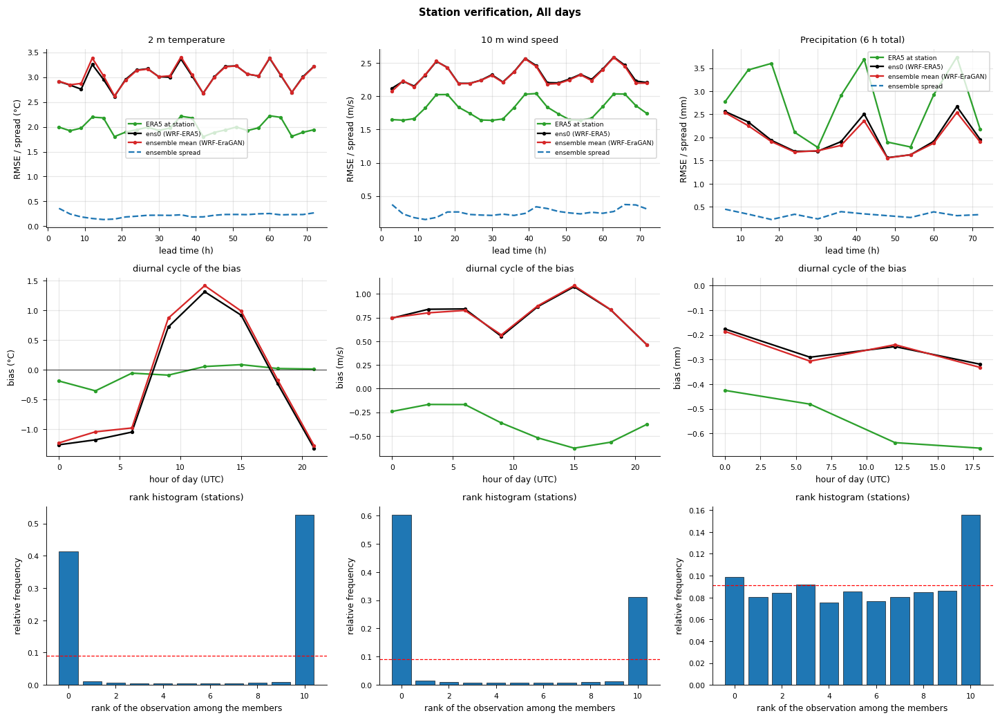

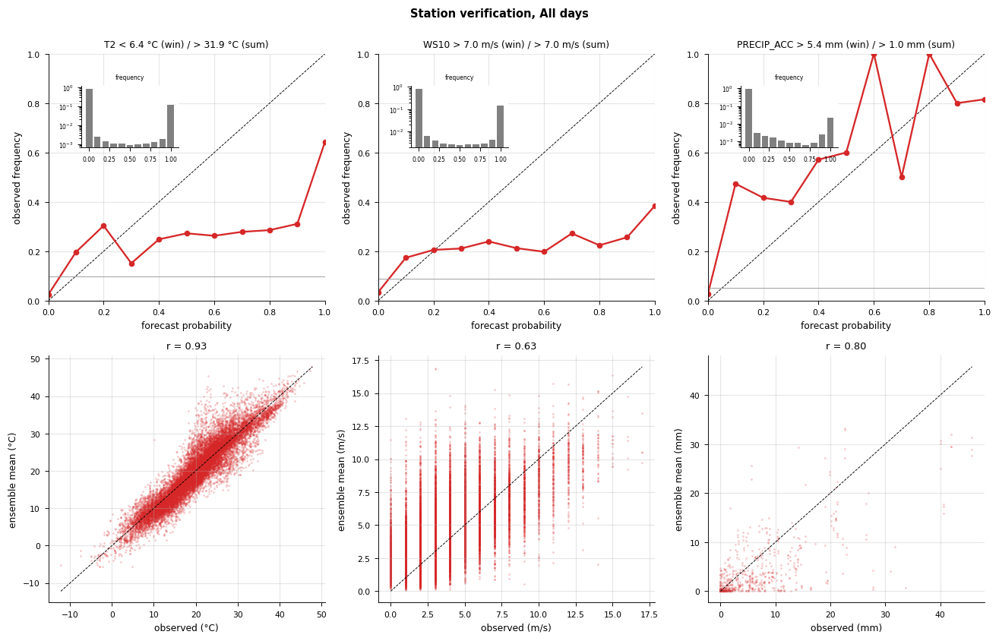

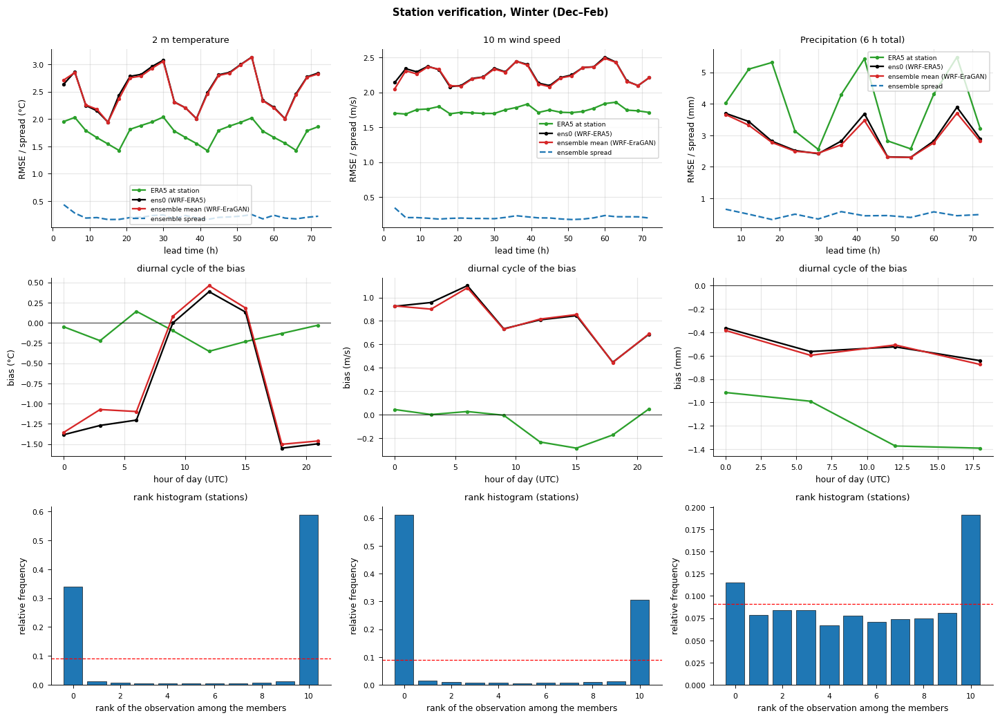

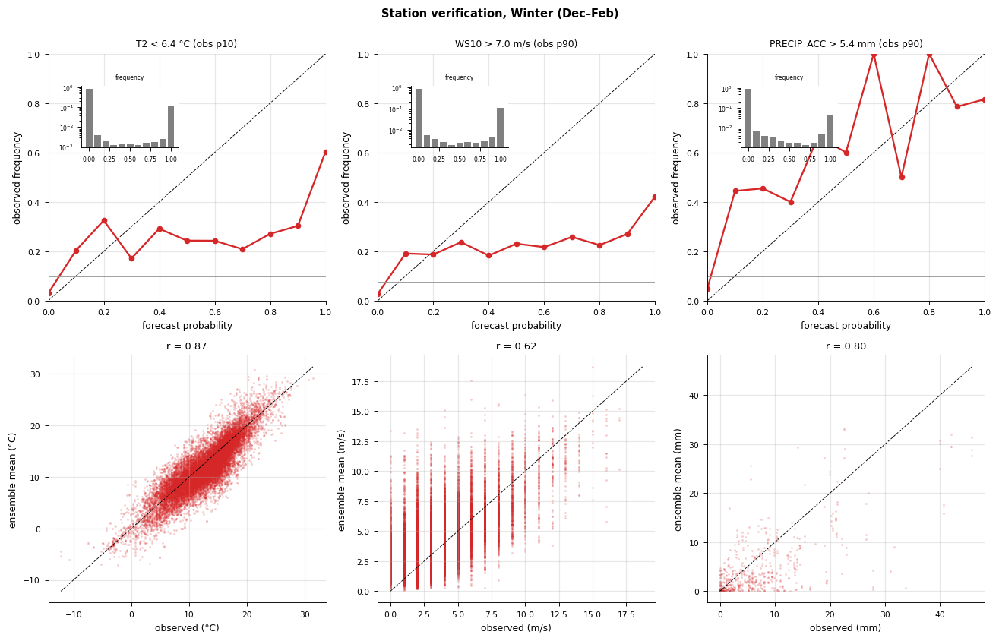

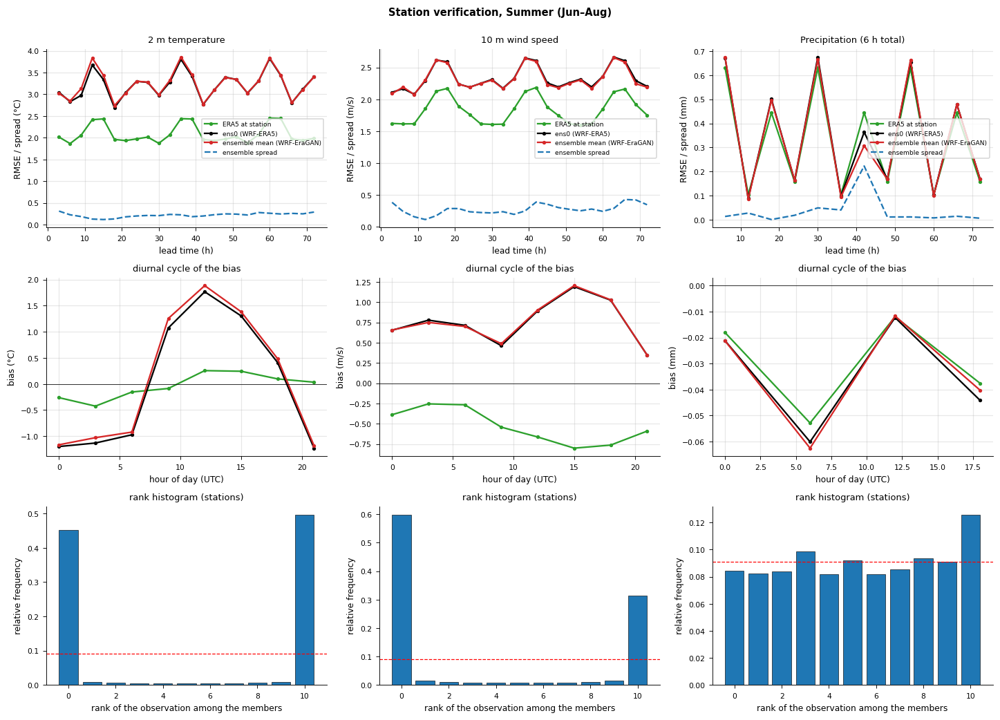

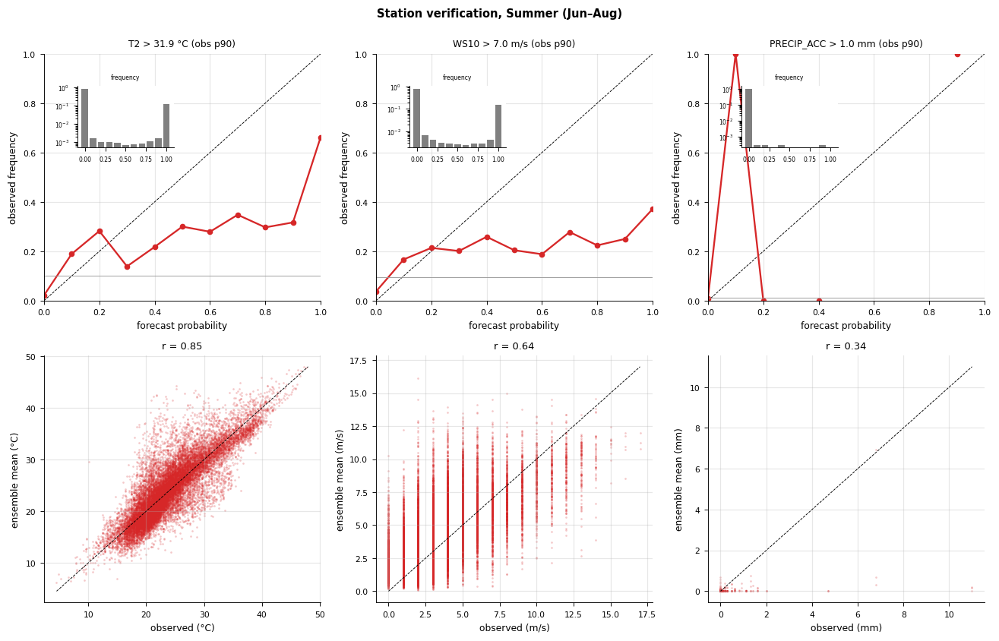

In [42]:
# Lead-time and diurnal curves against the stations, rank histograms, reliability diagrams
ST_COL  = {"era5": "tab:green", "ctrl": "k", "mean": "tab:red"}
ST_NAME = {"era5": "ERA5 at station", "ctrl": "ens0 (WRF-ERA5)", "mean": "ensemble mean (WRF-EraGAN)"}
for SEAS, g_all in PER.items():
    SLAB, SFX = SEAS_LABEL[SEAS], ("" if SEAS == "all" else "_" + SEAS)
    sv = [v for v in SRv if (g_all["var"] == v).any()]
    fig, axes = plt.subplots(3, len(sv), figsize=(4.4 * len(sv), 9.4), squeeze=False)
    for i, v in enumerate(sv):
        g = g_all[g_all["var"] == v]; u = VARS[v]["unit"]
        # (1) RMSE and spread vs lead time
        ax = axes[0, i]
        gl = g.assign(**{f"se_{k}": (g[k] - g.obs) ** 2 for k in ST_COL}).groupby("lead")
        for k in ST_COL: ax.plot(gl[f"se_{k}"].mean().pipe(np.sqrt), "-o", ms=2.5, color=ST_COL[k], label=ST_NAME[k])
        ax.plot(gl["var_ens"].mean().pipe(np.sqrt), "--", color="tab:blue", label="ensemble spread")
        ax.set_xlabel("lead time (h)"); ax.set_ylabel(f"RMSE / spread ({u})"); ax.grid(alpha=.3); ax.set_title(f"{VARS[v]['label']}"); ax.legend(fontsize=6)
        # (2) bias vs hour of day (UTC)
        ax = axes[1, i]
        for k in ST_COL: ax.plot((g[k] - g.obs).groupby(g.hour).mean(), "-o", ms=2.5, color=ST_COL[k], label=ST_NAME[k])
        ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel(f"bias ({u})"); ax.grid(alpha=.3); ax.set_title("diurnal cycle of the bias")
        # (3) rank histogram
        ax = axes[2, i]
        rc = np.bincount(g["rank"].values, minlength=N + 1)
        ax.bar(range(N + 1), rc / rc.sum(), color="tab:blue", edgecolor="k", lw=0.4); ax.axhline(1 / (N + 1), color="r", ls="--", lw=0.8)
        ax.set_xlabel("rank of the observation among the members"); ax.set_ylabel("relative frequency"); ax.set_title("rank histogram (stations)")
    fig.suptitle(f"Station verification, {SLAB}", fontweight="bold", y=1.0); plt.tight_layout(); save_fig(fig, "stations_leadtime_diurnal_rank" + SFX); plt.show()

    # reliability diagram of the p90 event + scatter obs vs ensemble mean
    fig, axes = plt.subplots(2, len(sv), figsize=(4.0 * len(sv), 7.6), squeeze=False)
    for i, v in enumerate(sv):
        g = g_all[g_all["var"] == v]; u = VARS[v]["unit"]
        ax = axes[0, i]
        n_k, o_k = np.bincount(g.k, minlength=N + 1), np.bincount(g.k, weights=g.ev_o.astype(float), minlength=N + 1)
        fr = np.where(n_k > 0, o_k / np.maximum(n_k, 1), np.nan)
        ax.plot([0, 1], [0, 1], "k--", lw=0.6); ax.plot(np.arange(N + 1) / N, fr, "-o", color="tab:red", ms=4)
        ax.axhline(g.ev_o.mean(), color="0.6", lw=0.6); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel("forecast probability"); ax.set_ylabel("observed frequency"); ax.grid(alpha=.3)
        ax.set_title(f"{v} {EVLAB_S(v, SEAS)}", fontsize=8)
        ins = ax.inset_axes([0.12, 0.62, 0.35, 0.25]); ins.bar(np.arange(N + 1) / N, n_k / n_k.sum(), width=0.8 / N, color="0.5"); ins.set_yscale("log")
        ins.tick_params(labelsize=5); ins.set_title("frequency", fontsize=5)
        ax = axes[1, i]
        sub = g.sample(min(len(g), 20000), random_state=0)
        ax.scatter(sub.obs, sub["mean"], s=3, alpha=.25, color="tab:red", lw=0)
        lim = [min(sub.obs.min(), sub["mean"].min()), max(sub.obs.max(), sub["mean"].max())]
        ax.plot(lim, lim, "k--", lw=0.6); ax.set_xlabel(f"observed ({u})"); ax.set_ylabel(f"ensemble mean ({u})"); ax.grid(alpha=.3)
        ax.set_title(f"r = {g['mean'].corr(g.obs):.2f}")
    fig.suptitle(f"Station verification, {SLAB}", fontweight="bold", y=1.0); plt.tight_layout(); save_fig(fig, "stations_reliability_scatter" + SFX); plt.show()

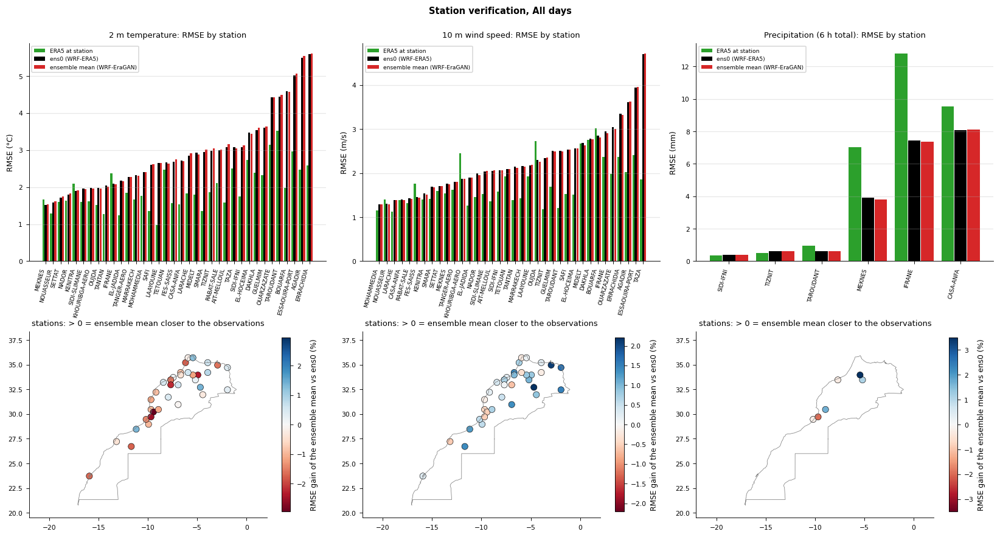

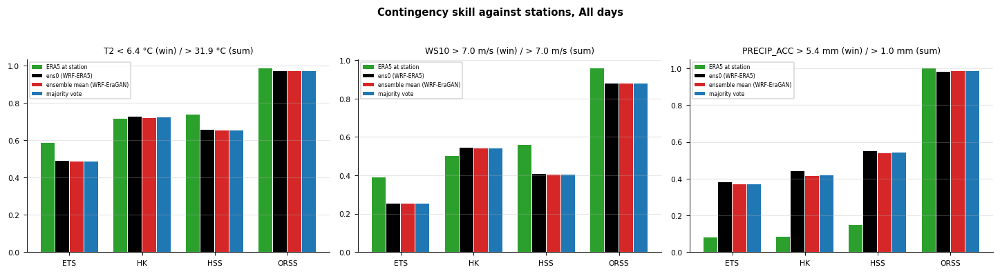

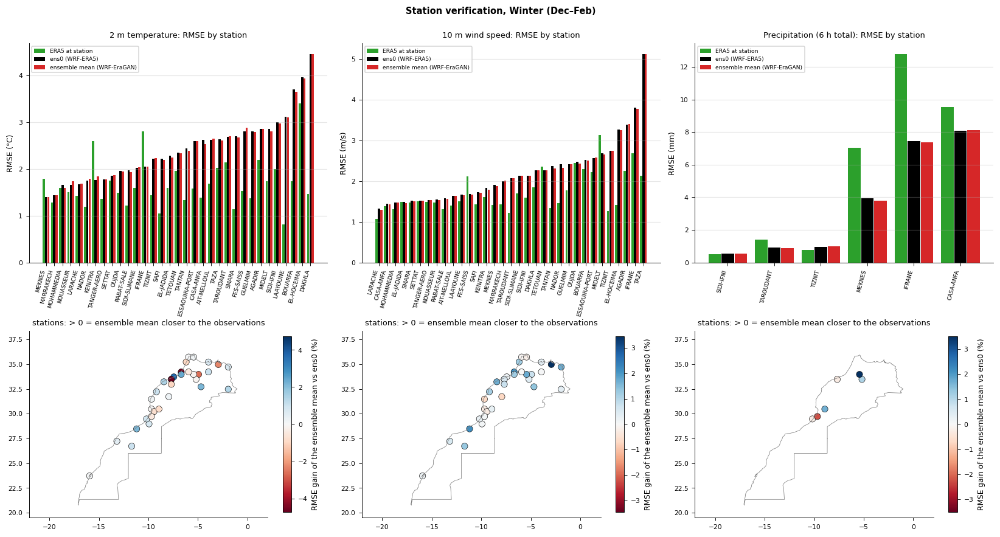

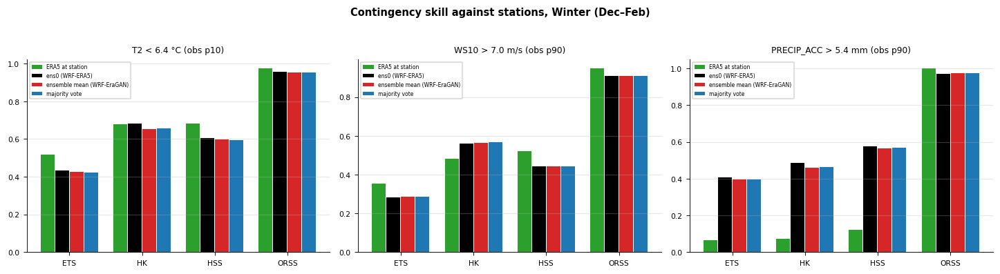

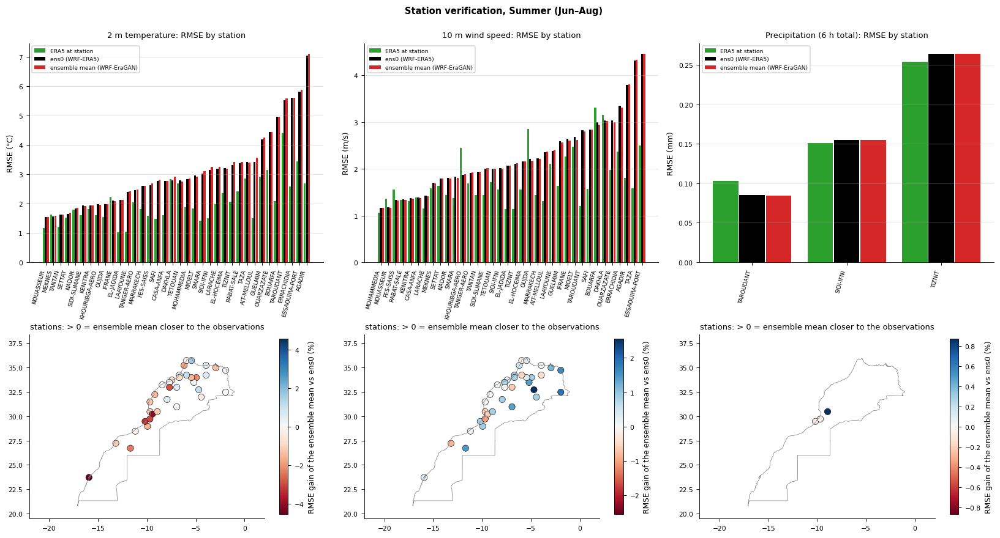

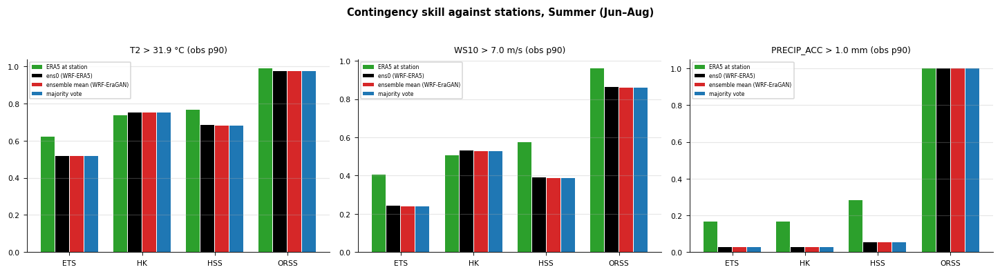

In [43]:
# Per-station scores (bars) and station map of the skill of the ensemble mean
def land_outline(ax):
    for gm in getattr(MORO, "geoms", [MORO]) if LAND_ONLY else []:
        xs, ys = gm.exterior.xy; ax.plot(xs, ys, color="0.5", lw=0.5)

for SEAS, g_all in PER.items():
    SLAB, SFX = SEAS_LABEL[SEAS], ("" if SEAS == "all" else "_" + SEAS)
    T = ST_STN[SEAS]
    sv = [v for v in SRv if v in T.index.get_level_values("var")]
    if not sv: continue
    fig, axes = plt.subplots(2, len(sv), figsize=(5.0 * len(sv), 8.0), squeeze=False)
    for i, v in enumerate(sv):
        t = T.loc[v].sort_values("rmse_ctrl"); x = np.arange(len(t)); u = VARS[v]["unit"]
        ax = axes[0, i]
        for kq, k in enumerate(["era5", "ctrl", "mean"]):
            ax.bar(x + (kq - 1) * 0.28, t[f"rmse_{k}"], 0.27, color=ST_COL[k], label=ST_NAME[k])
        ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=75, ha="right", fontsize=6); ax.set_ylabel(f"RMSE ({u})")
        ax.set_title(f"{VARS[v]['label']}: RMSE by station"); ax.legend(fontsize=6); ax.grid(alpha=.3, axis="y")
        ax = axes[1, i]
        land_outline(ax)
        c = t["RMSE_gain_%"].reindex(STN.index); lim = np.nanmax(np.abs(c)) or 1
        sc = ax.scatter(STN.lon, STN.lat, c=c, cmap="RdBu", vmin=-lim, vmax=lim, s=45, edgecolor="k", lw=0.4)
        fig.colorbar(sc, ax=ax, shrink=0.8, label="RMSE gain of the ensemble mean vs ens0 (%)")
        ax.set_xlim(float(LON.min()), float(LON.max())); ax.set_ylim(float(LAT.min()), float(LAT.max())); ax.set_aspect("equal")
        ax.set_title("stations: > 0 = ensemble mean closer to the observations")
    fig.suptitle(f"Station verification, {SLAB}", fontweight="bold", y=1.0); plt.tight_layout(); save_fig(fig, "stations_by_station" + SFX); plt.show()

    # full contingency scores against the stations
    fig, axes = plt.subplots(1, len(sv), figsize=(4.4 * len(sv), 3.4), squeeze=False)
    for i, v in enumerate(sv):
        t = ST_CONT[SEAS].loc[v]; ax = axes[0, i]
        for q, sc_ in enumerate(SC_PLOT):
            for kq, k in enumerate(["era5", "ctrl", "mean", "maj"]):
                ax.bar(q + (kq - 1.5) * 0.2, t.loc[k, sc_], 0.19, color={**ST_COL, "maj": "tab:blue"}[k],
                       label={**ST_NAME, "maj": "majority vote"}[k] if q == 0 else None)
        ax.axhline(0, color="k", lw=0.5); ax.set_xticks(range(len(SC_PLOT))); ax.set_xticklabels(SC_PLOT)
        ax.set_title(f"{v} {EVLAB_S(v, SEAS)}", fontsize=8); ax.grid(alpha=.3, axis="y"); ax.legend(fontsize=5)
    fig.suptitle(f"Contingency skill against stations, {SLAB}", fontweight="bold", y=1.04); plt.tight_layout(); save_fig(fig, "stations_contingency" + SFX); plt.show()

In [44]:
# Written analysis of the station verification
for SEAS in PER:
    t_all, c_all = ST_SUM[SEAS], ST_CONT[SEAS]
    L = [f"### Analysis: verification against station observations — {SEAS_LABEL[SEAS]}", ""]
    for v in t_all.index:
        t, u = t_all.loc[v], VARS[v]["unit"]
        L.append(f"- **{VARS[v]['label']}** ({int(t.n_stations)} stations, {int(t.n)} pairs): bias / RMSE against the observations are "
                 f"{t.bias_era5:+.2f} / {t.rmse_era5:.2f} {u} for ERA5, {t.bias_ctrl:+.2f} / {t.rmse_ctrl:.2f} {u} for `ens0` and "
                 f"{t.bias_mean:+.2f} / {t.rmse_mean:.2f} {u} for the ensemble mean. "
                 + (f"`ens0` is {'closer to' if t['ctrl_vs_ERA5_%'] > 0 else 'farther from'} the stations than ERA5 itself ({t['ctrl_vs_ERA5_%']:+.1f}% RMSE), " if np.isfinite(t['ctrl_vs_ERA5_%']) else "")
                 + f"and the ensemble mean {'improves' if t['RMSE_gain_%'] > 0 else 'degrades'} `ens0` by {abs(t['RMSE_gain_%']):.1f}% RMSE. "
                 f"CRPSS vs `ens0` = {t.CRPSS_vs_ctrl:+.3f}; SSR = {t.SSR:.2f}, {disp_verdict(t.SSR)}.")
        c = c_all.loc[v]; hss = c["HSS"].dropna()
        if len(hss):
            b = hss.idxmax()
            lab = {"ctrl": "`ens0`", "mean": "the ensemble mean", "maj": "the majority vote", "era5": "ERA5"}[b]
            L.append(f"  - Event obs {EVLAB_S(v, SEAS)} ({int(c.loc['ctrl', 'hits'] + c.loc['ctrl', 'misses'])} observed events): "
                     f"best HSS is {lab} ({hss[b]:.2f}); ens0 HSS {c.loc['ctrl', 'HSS']:.2f}, ensemble mean {c.loc['mean', 'HSS']:.2f}, "
                     f"majority vote {c.loc['maj', 'HSS']:.2f}, ERA5 {c.loc['era5', 'HSS']:.2f}.")
    L += ["", "*A positive `ctrl_vs_ERA5_%` means the WRF run adds value over the driving analysis at the stations (downscaling); a positive `RMSE_gain_%` means the EraGAN ensemble adds value over `ens0`. Differences between the station and the ERA5 verification (sections 3-5) show how much of the ERA5-based result is due to sharing the same truth.*"]
    show(L)

### Analysis: verification against station observations — All days

- **2 m temperature** (36 stations, 166543 pairs): bias / RMSE against the observations are -0.06 / 2.00 °C for ERA5, -0.21 / 3.03 °C for `ens0` and -0.13 / 3.04 °C for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-51.5% RMSE), and the ensemble mean degrades `ens0` by 0.6% RMSE. CRPSS vs `ens0` = +0.025; SSR = 0.08, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs < 6.4 °C (win) / > 31.9 °C (sum) (16548 observed events): best HSS is ERA5 (0.74); ens0 HSS 0.66, ensemble mean 0.65, majority vote 0.65, ERA5 0.74.
- **10 m wind speed** (36 stations, 161639 pairs): bias / RMSE against the observations are -0.38 / 1.81 m/s for ERA5, +0.78 / 2.32 m/s for `ens0` and +0.78 / 2.31 m/s for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-28.0% RMSE), and the ensemble mean improves `ens0` by 0.4% RMSE. CRPSS vs `ens0` = +0.046; SSR = 0.12, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 7.0 m/s (win) / > 7.0 m/s (sum) (14347 observed events): best HSS is ERA5 (0.56); ens0 HSS 0.41, ensemble mean 0.40, majority vote 0.40, ERA5 0.56.
- **Precipitation (6 h total)** (27 stations, 6122 pairs): bias / RMSE against the observations are -0.55 / 2.84 mm for ERA5, -0.26 / 2.07 mm for `ens0` and -0.27 / 2.01 mm for the ensemble mean. `ens0` is closer to the stations than ERA5 itself (+27.1% RMSE), and the ensemble mean improves `ens0` by 2.7% RMSE. CRPSS vs `ens0` = +0.106; SSR = 0.17, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 5.4 mm (win) / > 1.0 mm (sum) (314 observed events): best HSS is `ens0` (0.55); ens0 HSS 0.55, ensemble mean 0.54, majority vote 0.54, ERA5 0.15.

*A positive `ctrl_vs_ERA5_%` means the WRF run adds value over the driving analysis at the stations (downscaling); a positive `RMSE_gain_%` means the EraGAN ensemble adds value over `ens0`. Differences between the station and the ERA5 verification (sections 3-5) show how much of the ERA5-based result is due to sharing the same truth.*

### Analysis: verification against station observations — Winter (Dec–Feb)

- **2 m temperature** (33 stations, 55387 pairs): bias / RMSE against the observations are -0.12 / 1.76 °C for ERA5, -0.78 / 2.57 °C for `ens0` and -0.70 / 2.56 °C for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-45.7% RMSE), and the ensemble mean improves `ens0` by 0.4% RMSE. CRPSS vs `ens0` = +0.039; SSR = 0.09, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs < 6.4 °C (obs p10) (5442 observed events): best HSS is ERA5 (0.68); ens0 HSS 0.60, ensemble mean 0.60, majority vote 0.60, ERA5 0.68.
- **10 m wind speed** (33 stations, 53765 pairs): bias / RMSE against the observations are -0.08 / 1.74 m/s for ERA5, +0.81 / 2.27 m/s for `ens0` and +0.80 / 2.26 m/s for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-30.2% RMSE), and the ensemble mean improves `ens0` by 0.5% RMSE. CRPSS vs `ens0` = +0.047; SSR = 0.10, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 7.0 m/s (obs p90) (4035 observed events): best HSS is ERA5 (0.52); ens0 HSS 0.44, ensemble mean 0.44, majority vote 0.44, ERA5 0.52.
- **Precipitation (6 h total)** (26 stations, 2800 pairs): bias / RMSE against the observations are -1.17 / 4.17 mm for ERA5, -0.52 / 3.02 mm for `ens0` and -0.54 / 2.94 mm for the ensemble mean. `ens0` is closer to the stations than ERA5 itself (+27.5% RMSE), and the ensemble mean improves `ens0` by 2.7% RMSE. CRPSS vs `ens0` = +0.109; SSR = 0.17, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 5.4 mm (obs p90) (278 observed events): best HSS is `ens0` (0.58); ens0 HSS 0.58, ensemble mean 0.57, majority vote 0.57, ERA5 0.12.

*A positive `ctrl_vs_ERA5_%` means the WRF run adds value over the driving analysis at the stations (downscaling); a positive `RMSE_gain_%` means the EraGAN ensemble adds value over `ens0`. Differences between the station and the ERA5 verification (sections 3-5) show how much of the ERA5-based result is due to sharing the same truth.*

### Analysis: verification against station observations — Summer (Jun–Aug)

- **2 m temperature** (36 stations, 111156 pairs): bias / RMSE against the observations are -0.03 / 2.10 °C for ERA5, +0.07 / 3.23 °C for `ens0` and +0.16 / 3.26 °C for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-53.4% RMSE), and the ensemble mean degrades `ens0` by 0.9% RMSE. CRPSS vs `ens0` = +0.019; SSR = 0.07, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 31.9 °C (obs p90) (11106 observed events): best HSS is ERA5 (0.77); ens0 HSS 0.68, ensemble mean 0.68, majority vote 0.68, ERA5 0.77.
- **10 m wind speed** (36 stations, 107874 pairs): bias / RMSE against the observations are -0.54 / 1.84 m/s for ERA5, +0.76 / 2.34 m/s for `ens0` and +0.77 / 2.33 m/s for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-27.0% RMSE), and the ensemble mean improves `ens0` by 0.4% RMSE. CRPSS vs `ens0` = +0.045; SSR = 0.13, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 7.0 m/s (obs p90) (10312 observed events): best HSS is ERA5 (0.58); ens0 HSS 0.39, ensemble mean 0.39, majority vote 0.39, ERA5 0.58.
- **Precipitation (6 h total)** (9 stations, 3322 pairs): bias / RMSE against the observations are -0.03 / 0.40 mm for ERA5, -0.03 / 0.42 mm for `ens0` and -0.03 / 0.41 mm for the ensemble mean. `ens0` is farther from the stations than ERA5 itself (-4.4% RMSE), and the ensemble mean improves `ens0` by 1.1% RMSE. CRPSS vs `ens0` = +0.054; SSR = 0.17, **under-dispersive** (spread too small for the error: over-confident).
  - Event obs > 1.0 mm (obs p90) (36 observed events): best HSS is ERA5 (0.28); ens0 HSS 0.05, ensemble mean 0.05, majority vote 0.05, ERA5 0.28.

*A positive `ctrl_vs_ERA5_%` means the WRF run adds value over the driving analysis at the stations (downscaling); a positive `RMSE_gain_%` means the EraGAN ensemble adds value over `ens0`. Differences between the station and the ERA5 verification (sections 3-5) show how much of the ERA5-based result is due to sharing the same truth.*